# EXP_10. ¿Sigue mejorando K1 cuando el corte temporal se implementa bien?

**CRISP-DM: volver a preparar los datos y evaluar de nuevo.** EXP_08 encontró que
corregir MIX con el **contraste vecinal** de la integral NDVI Planet reducía el RMSE.
EXP_09 fijó esa variable **cortada al 31 de octubre** como K1. Mejoró a MIX en dos
juegos de particiones, pero no superó su umbral de familia (p ≈ 0.13 > 0.10), y su
regla recomendó **MIX**.

**Por qué se repite K1.** Una revisión encontró que el corte estaba mal implementado.
La curva se suavizaba e interpolaba **con todo el año** y se recortaba después, así que
capturas de noviembre podían cambiar valores de octubre. Este cuaderno corrige solo eso
y vuelve a medir.

**Lectura de la corrida registrada.** Reconstruye ambas variables desde las capturas,
verifica la invariancia temporal y evalúa las predicciones guardadas. **Cero ajustes
al ejecutarlo.** No genera las 59 predicciones. No es una confirmación independiente:
K1 se eligió después de explorar estas mismas etiquetas.

**Recorrido:** una parcela → las 197 → comparación en dos juegos de particiones →
territorio y concentración → nulos → decisión y límites.

## 1. Fuentes y alcance

| Entrada | Se hace aquí | No se hace aquí |
| --- | --- | --- |
| 32,257 capturas Planet de la receta (NDVI finito, nube ≤20 %) | Reconstruir las integrales publicada y corregida; probar la invariancia | Leer píxeles ni cambiar la receta |
| Centroides UTM y conjunto de las 197 parcelas | Vecinos a <1 km y cobertura, solo con X | Usar rendimiento para elegir la receta |
| Particiones históricas y nuevas | Verificar correspondencia con las predicciones guardadas | Generar particiones nuevas |
| Predicciones OOF, parámetros y nulos de la corrida | Comprobar la ecuación, recalcular métricas, reglas y concentración | Reentrenar ni recalcular los nulos |

La celda técnica verifica tamaño y SHA-256 de cada insumo. El código de la corrida
(`modelo_10.py`, `experimento_10.py`) queda como texto comentado inspeccionable: **no se
ejecuta**. Para reproducir el entrenamiento, ver la sección 9.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T23:44:10.435128+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos verificados y código de la corrida para inspección; no se entrena { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'capturas': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/capturas_receta.csv', 'bytes': 936151, 'sha256': 'be8adde5d27a93b492a9a39d5d1984bac0c75020aa19c9311d35c59021351a81', 'uso': 'capturas', 'origen': 'data/exp_10_verificacion_contraste_vecinal/capturas_receta.csv', 'bytes_zlib_base64': '...'}, 'metadatos': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/metadatos.csv', 'bytes': 13917, 'sha256': '9882c9793559084a98ddebd3a08137baec766f83df1191a29a6485077e925424', 'uso': 'metadatos', 'origen': 'data/exp_10_verificacion_contraste_vecinal/metadatos.csv', 'bytes_zlib_base64': 'eNqNm9uOHraRhO/zFH6AAcEzm5eCIiRarKUg673ZG2OgNRIFsmQkEbB5+/2Kh3Fke0jZgGTZ/vmTfaiu6u55/fvv//T2P1//4e2btw/ffv74/t37n95/enj59s1//Peb794+/N/3Pz786/sff/fiDy+/9z48vHz88NPnD/zy+PHh1Zvv/vzqzYtvX7/S/1ly6dm74LPlGKzbQwzVW+NfWU2pthDWKfHh5V/f/+Xj418/P/7GMc1i9M6iL/pM6xzTa2zmWvD8p2w+rXPSw3+9//iXz+8/fH7HMX/686vfv3758vXbNw+llmTNZd9Dyj0Hzoi+lxyc8ceeYtlXyccHWenBRZ7F9XvVTSqPKy7m3q2E7us6ppxf1ENOrviWLeVc63iRL8HlyHk++7yOqZdjeiouNyzju5d9Iw/wGKYG3zPm2YZpXxjmF8fUEHJ3zXhAqCkEHVOb766GyIVStXWKnW9TY6nOeoklR/w0HlV8cr5UIqFxi3VOf3j5+fHzP3/46Yd33/zvD9/88f3HT3/79I/HXx1YamsO5/iUeGTVvRJfoogKqfjc53nBn+/VfDUXWhjhE5PuVZrHabXWHmrYx4Qvj/n38LFoIbhSeg8h8fXjbbXI8aHzL5Mtx4dLKPeWuiuhNvMxRmVE79jLxV587Lhgn5NunvfReZkl+RaHrbFwdqGnmsmJso7JF9OEVB15U417hZFZRLJu2EO0TJSuc27xbDwrFcIQm6Y4zGPkPsEQrZawj6nPm7hZsOj4YGup+jbDJ+dMhmL8XsJ+UrtcJZPVtaXmU8Cgw9v4TCcnLrBiOVxiObXqXYoxkeCpzAeRG45ga6AXl1zn9CNeJD2ggBstkWN6E0FTk6teOAQqzVOif3j14/sP7x8/fvrmf7jPPx9/fVLqxbXEXSogqgDkgdwR49aUuccycQzHh2FkA0uBzCrASdPKhbcSfqSIzysA4yWQsXDky5OeVmayN+sEco382edlH9LtYJ/iQUqHkXwjUOooEE3xZ96IPmtluSte4hikqi5kP+I3jVe1GJvzBHEnG3xc55QvrvPv8Qe21+oy5cAAv5ELeBxgLBkbU8i2gS+YbKoqHvDKGUsMpChEkSOW8Hi0/aJ2uAmhQikgBQXDqg41AfBcjtiJFNJtXDukUwNzXfcyJx8bqW1EnQNu8DsAv87oz9+DdwcH4OHNAL7oHtiYgA5BZq3LqMk/X3bDBKXSeBKZNEoLGEgkF2sRx68MSAfwbZXK5LBrj7HEWSwTSQQ6AS7WV+lOl4htls3hBOCk+1xGjFQMQpaT72GHWjojryXgyUUDZ2Lhn2c1AcG70JsSsx+UjyU3U8gwLddXkZx2IR1cDuRVDFxpHVO+rlZW8pHki/AhSltcGeAbtAm0CA2nrwOPEIxXwGzjUnCTMN+WAAegD2APu8qldkS97o1iGXPNEAoTeNZYi8CdJ9a+kzHZ0UTJwFtgXGfUxUrwnauCvkpCrghOhwiOlHwXJm0sNjIpFzkrBFEm23Uy+zPtyyWpgEBiQx/Glb2pKZFggGstuobFjg/C6dAsLtUKf+lBBcc4Qgn0hRbty8Tn8ylRaUFHwK1GP20SsGziDP7els3pCAyxE8CKkuDLLJAEjvNtAHF+skn+iqKkYoJ5yF9vfRSlIiZAnSIV4r7OhT1APaIr1UNnLbaRmZWC4IrJLFSTFXa5Hr0k7gr1LTzHlzK8BBOCZ7cAJyCEVsDk9vAd+fTIQe8+/YaX9CaobKFUpmGeBPw5BYtBZ/PCiWwPbx4/Pr57xEY/PSo3v338+zDWi7+//8evjUXk42tyAmJUlYZCUz0cIAXVAeJt936jfo06RaFsXbJjUD8C2CU4MdzENlEq/pAX3aD3uDqDz6kMXgLyqKBjMsJxnxEeXnz48dOHT//6NeJYSlJyGCUKxTiDOKDmANZNdWs5H/L02wj2RVCSY0mfhL1yk5EbiUilTljNInMrBMqFTxCGDu/DkTDz4FvY1aCmYIeRZfuYm8yTeQLlsuXJrskyTCyOgvCsO5JK+QqyBeenUkPU+yRJqTlqEZQUKFjH1EvJAVmcAgjHcZVxDMEolmsSIOuUdiMmmLgXkorYjiPLuAu2SVQPM9vH2Nk0fKmDmMApkPKDE6CHq4NFdpAI2bmO6c9GTqtUFVgfGF5RwKoPMMdKiiFegLW0yWO9CTs+BW6ANZ3aNB4EiQXvUefQ4u2lGp5PBK/STb21hhbyo1R5RBwwHRE1WHmfcaPDQ7xQfdGseQQebzRpInxFKj7d5YTMhdIGuFfJjrBEBxHvIE85ht0tqflr5bN5CIV+62TmlM8Ga8fwPOypftbys6e+qDUdSzixNZgJWSg3kewUQswLSMLB1gH1kpMQcWGdSScOig+zJxJxN4bfxbNeehSQNpC8UmrKYG9kOapc7icfMfo6xW56A1IMuzGeMPK6ql8CVBCMYTcU6gWBSWZoUpM0BILD4loZZxslLK5Tmj+zAcIcOclvUJFYJgOU/42aVyFPy7rtEL3GtzmJ1Sb0ziMZgRbVX2Ri2aZt8VpRklPfSaA76glxTw1skoR9k752aUmQh5iAasL3pZUCPIZzMlbvT6qlnbHXq2eIf/SkKNsWqltzUZTAFDrrlIOSI0q4PrEun84uHbUKJA4iOsYf1xn1KDpgz1B88o7PDB1HmAQSCoAiG+s27g12I+KFwCPnapzGrfAAL9BqW223MxXm3tnpQmnAvyLFIx9AW73xKVL6WXJEbl/T6NVE+Rl54HuQqqRSIfiXf+wYt0VNGSfQBxfIHR1D1GeVS8mEXUbszIWL+isFd1CT40xnyVTKSGg4fLdXKA6/iU2wPLg0sYI88KONZkpBx2fFr2x3Qyx9JVbiD3StxBKgaZNUxcGzYvCSDsvbBMKzZS0r7IZ9IVATLyG0FNgM/Jv03TqjHCVYIOz4mGTbDJiSFEGQZC6ZnrxUn49/1A2IC1UQm2u76wRkZaCLKNz11U49CKgPaYhHkxTToEBVTVMyCXpXtptPLYjemodlikfziIksHZnaK7WllBC3Uc+BG6QFCDsEQh7xVrmE4i1KgWxm2C9kAYJRHYkk6ZZn57UorZq6/37V1n5qQ3BtiifpTBmlRo/yDEN0ak/m3jZV6De0JRxwJ1QONjkKotoZmmagM/wT0+3pAHClw5aT4JVQCwPgUKGKVqqS2NQ6Ix9a2klTFWoeCUOELVYJrMBhkCQw8X2RU7iCSCStuFIgYmcbsI9OBIHTut9Q2y9dM6JE7UR1b+OsZN3EepPaBRhqH9MuhBspDWiD2hB3W91N6olkKQw37LZKP5PcTL46z0XQt1KdCn6CxBnYL4jbmdzP3V/KD27tsJ3Y4ZjDTcQJOIO7qG9LaQd/C90oXoBExCJlDYvQXq2q3VlWYzL4c+eX+BSVlFxTB3C6ivcQ0W3UprDPucRvETIkC1ADqepxDknqNEAgHtYh6dwXRy04lQ0Keh5NtKqyDVgUNf9XWdSg5Vxbc4pDlKVASi/CTJojb9C1Hc6wzrk0IJqASipTbfm8ZgbcUC1ydbXDOuYSxK2IS+ISQg62OxmQV2PaJD5Xy5Ucf66ojT5IQ0wEtR/0eQ9OOvW0A2V6kdxwGcSRBbGoSZTVRh+NECzdowZegKjluI7pl2MAOWpsjklttDl2Rc7An6kI+GtZ5Tp+k5iGEgLfPs/evHo9TnGdCJrlo3AJXxRqlkOwLIVwdEy9j0OmF/UXV2EMmsCdclJiFS0+GMNsEgGjMHGRK1OTeh1zmCUnhK9TR54abZrFUJJQRIJfoZ+ttA5nopsTDwK/gZa2ZkNiZA7A60BeStsw5ca7cVMFHtB5wN6MOuUjd5KA3bc5kd0Wi4kIQrmrGn8CFs3vxO3Cz0AV2lldQeXQL009Lg0WhhxBtkGgEx6qG6mCPW9bTXgdN+cCEbIwm6SGVSi5UPq8kyh8/RDZqhvtF/l8HIhQIRn4hXxdpRIufWnnfcmOqqqtBuagYJqLDdAAp1hKfs/14I5nYqMBHmxXArYuCRja7KX0ojbxOuYc0ipIAtORBnNchBZAGlsoBSC0ZfbzLA7xBwkp6leozzSbXka1iuoS9ac8vYziUBIadqE9rSgi17TdQ4yD6mnM+zY3TNYcLecBNXOeoUUPLkgUcMV9yimquTOGURip3s71iJDEtNRLg+Vs37fb5AjLoIbRGuorTSkova9kF8vefrJn1UpWZ5qyT4D0OIGdsCxUCUK+bNP2w/4KokbDnAqDl7iSYEJWECuJcLE2ZXFI/mu6rWRZki4HTAV0nIWiRakn9VIoyOs9KdwWK5D3oTbJhImlEABCmoOxbtqdg3CZzIEVVX08sqlIbI96JUzuCEG49mrLhMtkrsmWkixUcPwz3IR1vMtJAYDq3td5XsNVAgsIQ9pSN9FRs6k9VAJxh7gsK+7SJXqBTahAoo5HNQKn9NGYXX08yEpaoXcex1HrKCq+AKl7Vh8USdwoauKznd6eF6UkYdZoAPSzNi6iQWrX7kiCIvmni5wZseSNAz5VYfLohtSk6TBUErJlcbuoX1eEusaeUh/mF0OKSeWryfub4eRLD8KEtWrUKvTGMteY7qokN/RdX0Uin9fTWtCc0qshY6N/DEwMzeG9SueuejmefFTxKiy24t48cco0FVNXmhxYzflwnMiJpzkPkUpAzKrgsY3SQCqh4Ffg5jOhiGpYhLGoAlEb5ZeSjOynGqO/LWyrlPMx6kICDFAlNdJHHWjaoNLwC9jaLqqHBj9XIGXkIDJm4l1CWnYtOyEPnx50aEBQzIgLxDL1J9U5uvUa5RD6qpz7GpfOGZDpTMJSnYLZPcASjpypushmjbl/1ZRKSy/Ee0S89TSInyYISnSIOoRuHlb8VwBVNhUO+PjMgt40ee++EwLbUYfpm7qjBEht4IkWp5TX1EnirgMWpNRqI2iM8PwZbfRRqjpe0c8ziB6UHLEPo97yqRzHyVRBpw0NTROnHKwSGwSzYd/8dJF8OiSoxStU6BrsT/lfKC54ywNYKxOv87ZYx3qm73xqNs9ER2FCkNMSc9jn1GcLrXof2gkxYhgAHoUWSgcV6UgYoGGThnLegWg6hqBAhjU/B0sJdga4cL2klYJ1zKmBBntDJxH/LfY5pu0tmkb11G1tfK4zbhNjrUKpxqtv52cdidp9JeCytPNy0WXeJt0lO5hFcdPZ4Y+dZzYgI2vZY51z20Gr+nJN10Wa531QCMCoFjTj2sQJ9UYb0KVwuZi1uDZ3IBFmxek2XrV6pVFNF0+VsepaNXQYsVfTkGaaMNlq9XDlhxfPTJyVdPJzbbOTAWOAdGgUGKQo1+evG5RokkDQ46Yyt5MQulC+0c8GNLdt63mqhDkcDlUP0NKUT0UcyGIhiMzv69y2KHkQ5xQtWpW+ep3gZiMItBy6b3NbCbauyVJXLqXV1qPCOS1Lmzrs+zq3RpqHNkRRwT51JcISCYd2LtrrXac0f+EwVVs8Yzl66m0SW8PspoFI2qZp4aq3qY9aUAHTplauY2dWCAH1WBW/XaO3aAzklceA3hAnRbvxamfsYVlohy4wNQOpHLSi2ue4WNSHcpfnKsjqz7T8NaUtmgIHtVxHV3tchyLrtPEEQdoI3E7NYNxUtWoRu8Zjc3TRtdkD00RYLMRrl20HLUJxClIEMZqn8uuq4rDpmOKmiL+cu/1yl5gENnSA93FmE1cRUkHteqlP5r2tAUtaZy2BEMKzL4jkIzGaGklbULRbI80POgRu9hjCblMWp40/cbO1+UP2H7ZtvDT0kEphMmfgU8AFUxXM7LtYuPYoi9NCPbU2TGqGteYjTdRkHROPulrLfMjWrtb00ubaqtPUtv8MvHYaYZA9lOqohG6zg5LzqI/ECiGXltA6Ddy0vQ/2ojSB+1kevX4GQb9oFLmvcYFeTSH1syTSSmk2KCW3nRY3+pjFr3PqcXdjbJdqgUU/ajC7nEWNOSyDYF9HnElDVot+7B2Z+jlzHRoKoDVRtZq2c45DN+20qmuNIvITuSHTwKfpJ0L67lXYbcfBSwgLAgjeeQxg1WSUCsuy3cb55djtixET/F9bn1p9JrbCbMBoIhq1/5A2+h+nbvopBM3Px+LtbKpTy+CXVTuqT1Kvx9M9rGnJQ0JCYnX9eILmZeSmtm6Wh/ulwwDiarGgQhXK6jDgINQEQUtBSLs70M/Lv6loLcLEnXqb7WPonKi7pjBxh36/NX7JOoQMb6DMTrytkUKJm7OWVdcp9brGmcf2vNdKs4i81jiTVtCROFCG0p/81G7mQR5hUUppSRO5oXcdGgwLBxpq+d3/A4gAwGA='}, 'etiquetas': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/etiquetas_138.csv', 'bytes': 1765, 'sha256': 'dd43b5b0468f56eaf5c58b1a055e8b7d8039a3037902564d6e65dce1a3941cc1', 'uso': 'etiquetas', 'origen': 'data/exp_10_verificacion_contraste_vecinal/etiquetas_138.csv', 'bytes_zlib_base64': 'eNpNVM2OmzEIvPdZosjY/JjjqrvaRmqTqtp73v8tarzjwI35ADPA8N3en38fv2+fj/vj8u/j/n77c/u4fz2eX89fbz/ePn8+W6PLuArsfuGrDgBejgZbLnIlBdAVxQ5gJX0uhxzgCxiiqC1AsHeR4xgLtOPhBSbKk1z6VRnAlscnwCz1yZNlb8mlU2QgvfdCrI+SsXtExa6RjqgRKcczgiUbAC9iyB8SvYDXKKMYc9nI5pYFmVYyYpgzniUHxFrio3E+QbMk+9qIoIJQiZKRzwpnhsQOX0G6QENHYmU8UopI7JBBS2OH0gH6KjKPJ/YmBxT2asUu72qQZ8jJWo7K6qIspn4cpRELunayZ5Ywz5dm0cIMiaPXGY8quM5NHCKZRUneyl59k0K+h/gF4nMrUvbCxP1VndqeG2zKp2hfG8NOUVLbrBRAcgX0fXkDYObUaV8bOqHva5sAUdI6QM8yxMXeOoadMibypNjpNV3qPWPWPfWXzSGrA+LRhle7hV7R+QhO0wFiDISHR8zB0dTgVBztU+OTY6XdkcqiEYQVZfbhIZ3zN0ecYqJ1ePl97xZz41wnSZE+7WPD0kmC/EQ9kRpmJX//CxGlwUoRpftyMaN1VHK0RVoUoWVVuueA1texvTrROhMt/0ha5/aKsvwZkcXPiI4jihMyLCYxMAmLt8bxeF4ozS00lJxU9LgvC39MmvHnacdT5jI9f7Lko9yGc67OY0U4RnLNfe3zW/P+D7J+efM='}, 'variables_control': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/variables_197.csv', 'bytes': 31992, 'sha256': '445aca6ddd1602d3db9b4035673f22b274a82cfc7e90a605bc34e7ba67561d9c', 'uso': 'variables_control', 'origen': 'data/exp_10_verificacion_contraste_vecinal/variables_197.csv', 'bytes_zlib_base64': 'eNqNXduSHMdxffdX6AN2O6oq6/rIoBgybYtUyPKLXxhrCKbggAAGCTisv/c5WdVd2du93bMD7iwOljM11VmZJ6/9/e9/+tOP//b9H3784cenP3799OHdh18+fH769scf/uU/fvjLj0//99Pfn/6B/z58+vL+519fPv70y9f/+vjh3ctfXyb07vOvv77/+QOgf/Xbv3/mX9Z/2f/lJzx9fPnpvz98+vDl829P//v+3YdPn3/76ef3n//+/suvH94ZbPyOedfX/zLf/N3LL1++/vryG17+3fsv5u9/e/ntywt/8cv7f/rmD9/+5Jx/+vbl4y9fP+Lby6en7374y5+/++GbP37/HT9xiqlFt3gXawy+tvoUfHa1AKpZJBfvn2JYpInbvhRJoT7hy/dHCU8+xvF+4enbv334+dPL376+nLxhqSG4pQaX+Oql4Q1bDqUuxTv8U6xO8EtLbfbrDFlqlCCu5MbvqaQHIXyi8acUrDqPVcvTv3/49PPXDx+/vsOi//Tn737//bfffv/jD08pJ6llia55iS16rDi4lqLHS7fYJCRsiCxeJMS5PCKhlrTtWnx6jkutrjY3Hj49PacFrxlyWqETJOjDS8OaZSw2Xl7SmppfAi4sLmDL3OGMy5sWrq8m31x+krg4SYnPqeyurbmo2WxPur6ozeMDJ1dilRhz1ovqkl9iwFu7iAXjCuLlW/bYzcjvRCSEieB3Fl9Sq3n+yhK9K7ICsZ0gPqx/ijdSmG8W3AQvVSCG3OXKa4plQgqzdy1CFnV92PVSwvoggqft78XjorqlhZZwelIsDhcO8kEsCnZixfIZVPXhM6+tG4suOyF8tebsfWxLqbiEPgsEGGvOeLEl+4B9llyfkluwOU0aRD2Lw+afQZ6nO8YNSu1BKOnDC5bs2lhyvd7nHFLG0U343NivooKRnCwuZaiewo8cM/bGnBTIWoSwBIjns4dE4DW2gxUIYRf9hFI9xbxb/2Qe83WH29O3X1++fnn/y/t3v/vr+9/9M9Tr/3z+7eWw7pRLWXC4nQikJHOvBZ+FmtJLcpA7CQuOx/r07LGGEqA0xyMqBGGVCdVTbOxq5s6OA45lX+5qcbliZ7zq0CDc1VQcTnjOuXnKYA5LbjGaw5VVRxkk8xILRN38EhCo/ImkM0TWPyq748BBHndLthq0horPnVJrUGHYQZWCnKiRPK6Wl5opBRGfJqWKQ5cE+wIkxWgQXIUFIoDDK1RtkCkANTsJG+BPkKgPj1f0YYiBv7FRDSdmSZCc6kIINIp837jgpLvQcAIz1OxSCkD+AOWKH55lgYFxEJfGP+I6VFNaoQDDcAIVffiE/8I4VtjdG/XlAjQ4XgVWLeixwmGKi28QKVhRLKthPxNUVKj9O5FS20RgCyES1UHyCi8Nvwsg8cFAR2CeLF1xGSuONyLrJcMCQEthb72afR5X7HKDoYywH085YYH+KfPwO5U8GIfs1hVTPKEPYvMbdIaM3cwU0WG9/J31qrjcMIcOUpmh3SieFbQIagsnOuFiwHpWiBOfW23R8BAY7Fzxb9tXUUhSnUg4g4ZYqpVdj31++wxhZ2pYsLIC6+dK16QxUvhwulryKolJ/FSk5xCkuIJqgcm4hO9BFMJv1YyDxu8hnCDDXJU6SQHU+fW2RpCkXKQ48Tg0qqXwevwQgs8KiQSHSp5nCMLsUjH8yS04+m2uG9cAUC7Z7v0RyfpQJiDrUbqxUFKyIxERsCRJ/eLDvC6OQlUz9vsp4cxmKpTxFbmvDkIjBvIQkRrmL4knBGI0oXCCiD46F01jxe2S3gmvOjQIDhJEn4IAVQrtnh0JKujqk4AtQ1DMdh6RZ9qtOo0udObD2KCkyvrHmoN7+u7vHz5+ePn0+Xf/iX3+8nJcN7T4UgR7zFNNIwDBwN7jgGFz8alxzLCtTewyj8gkqGoxx1UO/vIq4/BUR/qNg+p4oPX0gBuB2EAlwqBnUvYU4s7PwXUnQzSnB9sBfTWNUomEcN3DhPwZNKw8VeZK98KNFcLRgRWn5SuSOneCAsfRzDi0MKNKnSCFUYpSpozVzK1KTw3aXSrO11h+AJIzSONGlOoJMvm0mvf1+sqVTPId6LhEcMUQsnqRhdod/g50O/wgmHMQJBnffV0SKPD+aT0J2KU4jEq4MSpgvhni6dSYiF5V8nPYD/hmsIL4yGQROMXzS6kGrrmB4lNdarG/lIBEOGH733mNNH14foSVYEKZ2X2yGhx+WQbJgdNYQdvVBELRgNKDisEKRrgcuIgeXvhqsrlrcDlctghcCYjfPBCwPSTACW7IxHCWzrB1i7PZ4htHqdLThW4GFYPUKXWDZcgLFCaUTYBah/LGFYZPshlAIAIq6qdRhKoW+i8bVCG9UN8wfW3FCt3EM8xIJK1PGAsvFzsNvQjfEyeVDhLdUXgwjTYFijLUVgstealGW8sJAt0E96duyhoU8jFoHPadgqwXtr3AF1rgaFGqknrsDbxM4FomKCt4eepmiNs5SYBwbJ+eG0yRDY4EQrDwaXs2IQ+6yH6sqL29gRBIECu8I1QXTgo3ECIOswPxZHgCdguHNvF7Tj20AV9pflVCpRkxhaE6gYYlwUfeNLm4tyMxvnNcMgXYfVEPGEwbViXVEqB+NKJh2Ri3jnEXvyNoOFTSqrnSQHACDZLOoHFZA7npcHvkwu0puSrDwYaFFHpQROiGRchgrs33g0I6ESCtWJJRUglX1YauCqMjLk2kphPEXGmZvFJuDA3EvmJHcMJrc/AdqEYzxA+sCPzIUw1h22EP0vwBwgnvaG4PdAoglw2UTpChMlUDjZMh175OFRBecFbQSXDSMpxdELBGRywpK6+McUxD5xSSRIh8wekDmgM7s163eBlqgSsaqIpBgBsssAoarByUE2xy8KHvBFziZOnCAUkMY8x4UXoE6DIG4cbbj7Wmx4IWEG3IOlwWmECXwjCHDtQvgG9BGyWlCTCV9jBE2r4ajfqeO1aCOZeXzgkOINwlnDNosej7NRIqfeELezr4sJ88oTxU/H6GMPoJR6fVAcbyIGSCgMHIfbkk0lDanpQvR4h0JfPPISc6WbjUuZE8gErUTq70mTGeZhhiIOLEKJeWziBLbYbzJPVSAKUK38xxZXnE+nA8l0zWnEEWCnUvIzIR9NmHxmN0ROh3NtptEEFawvooNLxo3dphcOXCXgTJjJZqRD9VNbgx8Yx6zwBrhVKRxEDCjmOdQAyQBamuKz1+jw9jY5ezn7Q1uutIeYRrB1kF5/JNDwzPEF45QOdkRqpw5hn4BQXK1vUo0GFxHAyI++WVhC4hsQhg6fjilUw4ijCFEc6Hc/jQjITlNoLe+B4Ugfe5IfR2YCKg60EQooMqxCYrhGO2QvQhj9CJQoEifNPE0i6CtoNGwy/ocudpprBcPHgmYCpA33aEGlCzfjjpMz7t1GuwQEDAESbiT5A1EoaPG4aijnLJm0KDaaCyYzRD1Q70H60BfZHIOBgUnnd5n0vCYi0CGYBfNRU32A1DULs4zxFZ2b+fQdAYH/CC6YhC8qAjXG3qBSeGn2AdYcwYe4FSKtvT3t1d3Yx4E9ECgw5wqlyDVNGqkHrANYMrRJGD86gBTGyZ57NPLRurBSHyBXrAXGHGLaD4jDdxBq1qrk33An711QFkHmMpcKsSTkXSAxgCHXF4OzBJHl4vrKoUvz6ZI+jMdpSnv8A6vuB93n0+OYHc8pBAais0HDcDL+VJsBLMNWPN5GnQVRHXolZoQpI9z89nIGMX6fHJUIv4v394+fTy7gUX/pcX2uc/vvyqEvDNrx9+O0oATAtOP4wODlGmVSW35uViVggkOuD0RMYq0t5pPUJGNHA5ZD3c7S50XKAk4J+XRq9fQ8fQk9DEDBfDgic6yDiDNYUGywiirYEG8FODUANDK1QY8Cgg5sHRjgCKtE4rxKj4CbaGaN3cxeQujAt81yXjMONa4FU04AUextAIhCUy0M71Q6uNJ89gq8yUEqNzD0EjJmtjx9BF33z8++ePn/9x5FsgtkySQYgCiSIWhmMNTw60v9DxVD2eXTBZF/xfMCit2swMPHoPpjr1v9DDWCB7Jjnq8xm0+k91noUU3mCLO81JW891Sqavp1ZJoE7hSVVcXRAPjYdBl0K54pzAQS0k2kcIiwfVwBlJZB0FLMkTE42RDUxDFCfYmvkyKdB0E2eCzlygKhhbYAiB+gKEA1wf9KgyvUlSYTOGVN1aBWB8Z6wmwyo0k3SshLAo8z+WM8g6rOPApbtsPKXXw50vsadqeO2wa5CZUEDuVMWBhb5yJV4hr/Lyg3uk9EDYs7Ti4D+BO/QQopQFLp8XXIWoJFz2710ZSn713kPxMQcT1pORb/w2RxOGC4MTHLy6v5CZyoxAZeKPrBqiZ1RsD2JGgzDlB0JLRRnAiCGYUN8LFMFEajpD+mWyRCKVu0AXTkSDgOKDaWoRDgbeDoYZjlWtVYPonhnMLdKTCTHSZSMJsGe41iZeTlUJ3p5SmtmMcIqtKaE4XRiQmkvhwmYuuCIxsWpH4zQBxpwEp4G2gbBoJYrfkzPGtasGrkF3q01iACo2llTTGbTaeW/W2d5Uk2DnLPUA44q5RPWzwLayZ2CfwWfBOc5xgdeyRTnh5QNJkVdlIktyjOcJuCa+Q89leFrObwjY1xGx2fUhCfkuu94YNIZxwE56pQs1NLo3zCh7PbDQ2GJjSkQCzrgJPEEqcQ3iBJwKKrnW+pXgbJ9AK7FM04/J/m3z6BgMCaw2KsU7dWPpmuKqhdIq1bRG3SFV42mqkhRmAjffZSM0/1gDeBSIdekufmXeFOcaFgHbAhrbStmFyLW4bFdgRM8NZt+o49Ixk+RhfuoIrbEjP41dvvIOEpxluDKZuT0/MnuOuTx4MsHDqYZzl4sNqnZ/r/poPwJoDi67Le4i8SkGIcE+QmvG1JySHB8tP6nOLZFPoAqul5/AEoE2UofS+8e1JG9M2xeRAJ8nGQhnF9oL/vd4aNoPfNcg8QxaD42bFQmQxu2A7xxGGH+ossaaLHj+TBCQEIEoCKtbcIVy92/NpkL3nECGXpMQjCh1zjeEIBTdiMo0vuadfIWDl6BccCRwRSGTuZi6s3yCPMNFhxZnOmbACtWSDSs7g9ZMqMzKs3xTxIWdhnuT4f8ljbWCzdTADBiYF1YfGcXBsU3FjccReKZrQl7cH8Ic96PYsDGBBV7DkOd6l9trZEtg+LlTrsxKOdAvaHTPmjy8jUhP40uqu3iOOpk1rNUZjNKwEMiZwpRzaJiYOCNm+caxAcOpTOzlKPBs/Ih+xr4kGASyi9qmRfGd/NCibYiWnMUA/rP+Hmw/uSsYi8FCO8WGNDA0k4biLu46OCQMLbIuC0QopB5nptaqcNPBYpkWraxw2VWSCjlwnSrUawUchHcrVkxNITiDE8r1FFvjQzh3fux0ubA2FVvJmtFS6INFZRzQmIvyISbSNY/mbIBIc7DFZDeq+jywW5N7xAAFTd1rYtNJc4QHaBUNN3OBJdz6vLIwUkwvRz3eyIriwAosqI7M0iOpxr0NRGgbDOKxZK/1ADCqOL6aYcfBLBtSwxkyrLmbTk65qe4C9YDY0mUBaR+mFhKhAseAS1UGQl9Tnxk45+KMIdN6Y1Zwiq2dCKfYrOdSU7Vu6bVX41g2Do1AKQg8azjAzFUzzFSpg7VygxHv9Xmyjkj9MyxiuciXc9uXKqxwgBJQcguHm/WIDPJV+hSQNc/iO/OxT6DnkxTto9iayjXF0CVf5vxc0eIpEPpaNV8OTQmlQjoayMS1KMs7e0CI1LYrNPGs2LElCRR50rypCVj+doRWeWOhyaB25c71CVDheA1wixz68YD4Q7xATEvs5LZzOWj+tONyrCM3vqJiGj82pz2fYjZav56L65wILntcuL+i7iRVpQvwfhzr94aqhIK3TO2IgO04qGzjd6WHsVFdxtiRX49Ju84jhsIwk1YYBqoeMDTXPAsR4Jy7EHCSG7cQZnp9KAKjvSFwjFk8n93WOoBtptko29+pA47IWvlK1T7sUb20R4klhQt9SNA5GHmuF8YzMn7BVB6cYCyOrRCehWYBFuAMmUedRXBufevrPEliHV7CyRanBazssoBbyxrQQnagYZKqpcLjmcRVCzTXz+yGtxrjbLLADp9ha1dFnSlh6OpThkvGl/kR4dc7LQamSLEKpzGGy7oanF/WnJgiaS28TBZ5hkrP0a/5qkBtjP/NBwPFM2jVQIZjVnnQj8BxpWoBoYFDUXuwN2j8F95qU77OCx7SPj5whExO2NRWQr+96fVHam+V/Ciu+wUNNnYRJU1Mp2veCM7Cxg6DMjKRZqD86q1X+1TTZTqaihHvxrx3V2m4GtBxAo+cJRMa0aaLvz0/s9q87T7zY9Ash98tL79t13BW4LME2EyIb1kLOCu7ICo1MDkOKGDOtuqS5T7OqlC1+iwrhsexMdigmJL+DcunmI01DTNRryqqwBmgEKEDhIldjWJmdhwIBRVHgc7/IU50hF7lb9bduiqOAl2l4WHuBlex07cmEYoBvmeiZ87eBpiwneMBKIkxsvDFF0blYZWl6B95YiYzY8MH4uMJMisLNJg4vNJ6rfY9c21MMkKFqRLN2Ccq0cAEIPuvGih+25dzHSHyERa9rI+IT/8ottoqmb067SbuBT3FxI8mwWPvekg0uYVNbj0oHZuqXygmYxmf8mJded19aEcbOI8niC1GHMyqXVVT4XqzTArUCco/9HAOKA7L2RsdJK079GFXwcdqDutm4P0Wz1LI7Yu5HgYNmw3rHpGRstot9s7pgKKDDMbASL/GJlj+xUZHNt1ohoU9hDj5215qiK4WmZAW89HTmikNRRjSWpEaziBbsD8yFU0uyHZq4GiStIadiX/2mDm1RnCpGbFVGoiDPp6eE94yzY0Mj0KrPUuzBKzFi+YhYcMo5AvGNmlGgHkEEL+AVcDllKypKtHq/eGtKcKEkEGeeQCpckFjChyKJIR6amGFoIfOMJtNGH5LuzI/IKjgLYy+eligXrjdtDQL6rM09nmw8ZIhk/WZJTgumfBxVKiU/Lqz5BVkKv7crO1sN1W9UKcsLWeLRuhefKtM1wjLngLbExkRa6K9BEIFr8EkZ70W0RgDGJ851aGeYrZUYt3AcpO5akw2JjhSBWZxFOxD9FgtAT3Jyj6GQHF56/roUMTlnhC3LPSSmMYmJHxmQhBqt0H5FDIx0G3N18kYvHNdHPZTQLZiT+xDceJAOyF3Tto/5ILfxUZYxBl2MXOT1/czEd2uu0K4EdDUEFowS69ZAIFSZPE7tjAxtMW27VJmxZQ2chfDNsWa59no492d4QgMWQUXIEJpNP+KYxrWs6xGtP0E7o7xEoVFOLg6WLOTvdGrrNWItq7kBLIV1nGs8roFhM3f7NCrcDHS2k6BN4dJKer4gsKxUot1kmadubcozdIgOoZMq0xrp15HpOLcov89rH7A1p7fWe7s79rlE4mXVJDLxoIYXTUIxsImOigabiR4J6uxHavsSe/n0ujesEB7QoXBySO0bqc3C5PrLqQMv4++IShV1KpcviiUBhQrdF5UjpNUg4xneHc+5LmV5SHERtjTWNlNVwjrpjW9LiS7I+8DagNDVKDAAqurAzuQi60ePIHAq7DyAG0D4gZ/WGXRMVPgZMNqO8VeVaSuMnpTt1XIdVl+wV6uOFrmsNFsWmLvj5Zr5bDLRrHMMtqQHrsoCpvxt+MSREXDQPCDzqBpTbQGZt3wG2uCN2OcJUIFOpJ8jVc6duZUFmVQmUb2n8nsY2ECqIIJbQiFFzRjApETD/BZm0kLsPv4BMrbn7wFvcCw3nLntTYOihBsICc9UdA7iXXREJgIdQbzw+EOfmZ6iIDKW8TRHNpcEG2TqeKB838GrSctbt6Pv+mhx8aFxPBZZDeVFsnhGrfQXRX44JDwyh6QXU0mIL+zNMVGYNkpsO5Tu3l3cO0lOi0+zWNeB3wt9jHCa00QSY6WyDR7tpUGiw22sADGHJR3EhenjIzV34bOhFPMWuJxjm4b5Fl0U7BgOD2xN4axGnKhrRK2FzFphSO1szyEquzim1i1CzMa4av2dDMOP7NV4QwyMhnMsm9MVMVF5FnHKfLsB+NUCpADeo6JxelBT5KEHmCKcX/J2VoepabcWByvcWfFoNTcxOIpNtxFXayMxYZrwsE6k4DzynBYL90EV2agslBllqwqtQU3J2hQywrzPgbSFoiYoe18SpVFn4Xdx0V/Hkg7QVbvUbb4BXuE3y5rrqUt7AHLjnkg9ckz038+kJv3YEXyMqd75BOEzbDg7y3BRDT+FMvD2NhhbUJZF3ydY8G1ZBmYgEWW0ejL8DH0DiheYH5dHZ9YQpo/GPKYpzG/64DP+JhLBoWr8MFL7/KrZBk5a6FfYpSX5anJTulobIvWGk9WzAcbbCGUbdWRpFPMJJ9mw5K/bITHp2TjCBNPmRXXJJns1meo2ivRhZDVsktUJJZ2iVY8MXgwuY9e05SyoXg9+H/A1qLV2RTL6uTLxHkIbD2j91nZbaep0uY4GAjufM5O22FLiqlHAvYlivAbcrW1KWRQzWQkGI0+g9bESp220Ne3TwbnmuDSRuxiYJZJ+xMqXrcyDAbTpc2HlSK0Ps+IrJQtfu7947NVKgsp2O8G5aHvKAmuCGfEJFd7zRprtc0wFSIpz7kp3IxD3elJielF1alsRSY+uJsa7n0sNDMuwjE8IOXSR2aFSlaN12f1IFfLqgLzgylume0pMNDXYUS2x6fmWBiSR3UAvFut7mspaNs3WKtW5o7noNmmHNdHr6B8ABrqKdStLsSHawNAj5YegFqm3mQLbQdHBDQpgWlX7WeGHpnxt3iCmOJS2cqN/HW/eQwcgJNYecbq0l5UCxFYNHDbaN8jXBHops0mywliCuH41nW8dbwhRPQlIKiQAC2p6sN3dJQOXf/AtwoM7GnpZak9uBNfMQtG7kve1SQfITtoYZyycOdBsF87RuVmvQWQI9WwVzjL2C1hAXpiDiyZorcjJEwmmuJ4ZrIXdoXOX+IgiCNkx1qtUn6lzXGtIEXUPIxT9EFcXhglZeVwakFHh+GA2Q5FFm84bxGWobPBoErs372WnLO8eMOk9lj5ERyLVikYpDyUu55ZSCCMHlQui0J7np/VRmQTTO1o6Cyr+iycxRTs1T+pDX0+qQR9fqg6lIf2rcwlDUymIgUhDt3VgfJNUEqJ8UZthoJCm44NPZ3ArTGuzvPB13k+8WyeL7wdK8DtYtJeBG2vMI21ROaLmQOGHELhCbRVLdqoA70zA3zaQw1FHGWG/DgyQWhlBpSZ+pE7ZM0I0zUaZkHcI60UsKDK/3mEvFozziJbKFocedBLYDJzkYEj5ljEooFADsrbINbELJyI1jI9FbCXTFvMUOqE6H0dEDNYZJTyevF348MqNg0+GASjU/dWmH0PLB6Fl161lII/2bDkCaTR/WBIYXkQWkt5ZXrBN03qYFCZqVpY3cTSGvWC6W8whuEgbo0hBehggQLuf0Tbb2qoE9FRGTgQdJ1AySILR3RSBljHBpVSTrGxaC2aHkT1pnedk74y06Z4oab1olh0FrdEob6LmYY3U7slHXtVdm0XHACRrRJmzICtihPyp5BtY1oX+namPnO2Uc86JYmcOMk2Js370R1uzJQw6uT8+sTeBXr/a7CMtk5dnrqNK2Bq9hRbTdrsceCRu97E5iuOk0/s9Sn9yjfO7mERN+RHtGy7cVac6gdvGXHWQQ4hWndXIVirzVMuMZ1i1itedcJlGzwc90UHa5W8ThnyVMHYzsAO2kqFW6LpdAi9HzUbhC4x99QraeB3zr2kO7khnB1xQEwqaI5XIEV/s0aDfVxs/GOSpujOcloFC5Iic+fsXeHMS4liOpHZzIHrOZFd6bbMaIdcp0uYsuWEIjqcUSvlsnDsCLti4OIFHaKa/fjOQRo2BcB6OJzk1+7kEVrdobKlUjhL9W5oZeP0B+YeqxvxzCDUJYXqhxFCylmPGYXCGTDRakYODXNMllv/LZ9BqyJ001ePNyVala4GOzyovnUarc7vYGwDH740pUcsudnqnTyNOofXbojlvkyKezfe+3pYcPGcmOBYHli1MwacTbOGOGdR2601H6+tUpE50meQiaCOCn5iyUiwP601KMbzj+HqeGXt2GBZJEcO9BatyqJNtVu+t/q5Plmg6qxFWDqTx28avnOZbuc2uOQMWlcWtpSqv2xEZ2gWjNmDAbs1fhKKOm8wqqGU3AdRxV2jHecCaO8I47rGh6ccsw3TJHLKGbSKtkknxeuQUmDxl9cJd5BEDUkkx7L5zG1jmknXyQbxmRQ8IpWx1ZRnldpDyNo7GWZgIqbr5bIWHuIaG0sIeka1cPQpu7bVKYHgY/Ntl9ARMSExN0kzDt/bHWvYn4WTPmA4Uh8I6cRx+miDapBYtKdFOfVm3dSNwl/inMdDycL/OX8na7ip0lHcoHSOrcy5beUbHMbxZvkGdlXoZeBiiuQ+gMPpqQ8c5ZO1qpQV6Zv/m04Q4xA3s1M3Zbkg7JBNjmUV9pIwSgFJAsHGxxHteY0MOPQMtD5zW5KNP8QHobWqqW4VrWxAeaTfmbP0EkftJN9E479snCOtgGcTRT0LDtgCa2+M4riOMJ05EU6WyKw996IKR4vKsIHXyLGbyif3AG/UfFOKeVigVjhiB9obKqafUzgaaXt+Zr4tzqFrHEPIuUlxTmbLvYLxgJmsX5uE/KLznVX/UG65gIGpywXtmVOAJm5gPjCVTvWdt52xDP4cIXM2DVtN4eKti5bSZdazBtffGvoMnAT2J2TN7uqUTZtbxG6KnayXD4HyQQ3S5bgROPcLh3pxFkHPxWcm4th4DDlno17U0WKT8eoMIcFubYjvBpD1txXOLb7TUtUFTm9eIY5oP4HWki7jNaV4tV7P5ZDFNJ0YpFU+9JdxQF3VuDNz83G60+4U4qwMWHjjdD+G2Mqk1UDddqyHrMPrXcMSe+kuQ+gLQ7hYexzjKdgazKrmrANPgeDShIloZwQ+hqd7rhDHXRet2XYrlOQMWou9jJcHdfxWyIIlaByUxtG+oP8asoCygC+Py52FcSvVI/sxtZyMv0veaXUVPztHw+HqsDdSo0QUmQ1rZ5CNWwwWl67nXhUumaFzV4rrDcN8Jba5NkbiqzbRwCHo845BKBnHTKbEQJUz/eJiMykn0LGjndPkLlp2YUWYhJWCl5I+iQ6qdGEazeugfjA7dZE45qH5/VCHqCR310WstTO2XjudYmt552wtpgW8Lu/koFHGelj97LqvF5jHgY6OLD3J6pWGtB/rBwg79KrKFyzQlIAljVLWKLPau5Z4itk4yvC6brrbmVimdNaqvLw3l4EjMy0bOHTH98FsiWl8Uila9KVo9YvtgC7eCrCGh4/QnE4yhmUw+3FTbcAt5JgeplT6rlbWImrpNnSZdmiXEl9vatuVh2WOpvF2FrMaiHwF2KjJupd3MSkB69K2b/akdQVbOOUYW+kYOQHUOLXFBCSEkNdqxefAmJ+rdgSGYiwdhoqOYE9VG1iO2FhtyjNxkeXm2Ce9VwQHMha1Bvj0zDCzA7n24sTauzWdLQtqSsSyOdiMD5IsGY3gTxDr3g1zBR76zRtzXUgeqJJy6dVkNbIFnuMGPMsJtFCypF2Z0wnk+31X7MiWx6A1LjUHuzHEfjM2PnL0LZghb+uRekTSN87gq7wJC3ONdeFQr7beE4BAZlHABsgSORzGQYHzD6s+WMzM+owBiT9BTFuCbDNOyGQuu43xi7xbBau52f8QdOgWdhnCyKFEbrDKttJK/qA3tqh1EpjcoTLjf9zRIzR2lJFtv+7o3cR4CABtO1O8qY0Sf7gS7MTgjQK0cC+xGhnPcCysSvLsgTA1plrYD6s19VYN/gw6lvZTY10HiGpjP3Hr41N6+TSMHHO92Numk/gqVdDOPp1Az4F1C0Z3sQL9QWxNBLVps/JdjbCD6mHoDmvs86dDCSCs2dP9Y9yjLGxcnsFItQFaxD2QrCF0pry2OzOEPsOKTtJ0JntC6IBZnTAcuOJuwoTs7vF6Y55eBMPXZLk2o5BCRab2aX3iVkVYEMNDHsZWJZCn0138beUMh0NS46fYq1Gy3teCBBDnvPdLiLH4OqYs22nJgV4Z9LqJH+o8KrE9TSWdQWtVivHbyq3RSmzudeRTOt+EEwF5xy/WmLG3nHVPnPDcYGg54csz0ZlZpg0LXDmwSTFWz20Ygx0n2PDX1UqNkE+5aEKBj8t5T+L7+KI+j7Nl8h6dTufp2rGr3lRoA4GKKLZUx3QM5kmMSnwkUMBsET9GztpepLsjOXI8IIudexCDwVVbWXBAXgXEB/UtV00jOJy8vC40bRLXlsVGbQebX+kOcEah20+yBOLtcHuWu3Di7yTqgYFoX2HvbeTxBDKFWHPory83M744vpSDluFQJ35uHcTPcJDg8knogXKIV9uvOqQdv/A6XHCGJDirlCMKTb0o05tHaNUmbroXr3vdX99DhdmyClPnQrfY2GRyX24sO7FYKeZ3M2lPEJ15503AGMRfi8XDLorcTrFX0+yH5i53dylhsU3kBLmWc68LbzoZpLAQM+kkstL0fj2MLrT0auIS3tuM0WgrNuc+p3KK2R1e9ctdwbDT4CnobAver+X3DJcmxzBz08bfpAGhyqGW0U6tIEHBiTMjw3nFkrNc/oisiTqzo9VdDG50rNfRlLLvCR44HGTHObJBlPvJ25aFOuM4IZ1BnizEbW3ekV0zC3n1TI61E2S1M7NjiwGTuxp7qj4BcQu+h6Qhzl0mKgOGaqlNQb2Wnx2hRkPDG1YJI/6BKSgNjU0knSBGO8SpUWu4LOxh8yXrGNgfNCqR2KvAoSE6gIVso2Q7rF/jZzXPwp6s2RkmK+ZQjl5Nnou5/Y46TifYKhaml6Fe9UDChkM3BbKj0gv7YtTACFQw1H8fsd3i/nYiJ5AxQHa74tWMPM+GO96nT5tlmHHgrfP4jYMXSr99l9Mbe9Vmh5BrtkjMsOgw2n7ETBTVUeUH6NiK6euN08MBDbxXJ3PH0ivrWbazcAZc05lFdMej7JvkmbcL/Y4F0XYBK2L7q1jmegJZNbQemHw5+k3vaMD5grxNXq//TyxxprrpU49hsfvt20rSGe+sZbMpXCLas7fYEJEyrWFr6nWcLbLhTCd/8v4cqd8UpzTW9XqvyxLeu8O17dnQhmQ02WV3PG/UwN4gHGrXXaYUPW/9w9tYUpQiXJWS607JCvhprdZGVN6Jou58DjbDt7qb43KE1giUyZTWu0FdjvUmZFWwFH3JUPmFIpQDFHKU7t6Zu7qF3ksQJuJt7kAFeJyy113uu15iMlNOzIES4av0akMOpQicxSVFe8g5dmSbKcLwkjC57rdbsrrY+0Ul835MWCUYRU4dSxzi0LGSz6C11DBtg1T9Zdc7b43H2Tx6G4zeWwX6S8LJ3i1m+6PeUU1ryKXfsK8yuDstKKM1NRZzHw4NMhyg9eZpMi9lC1ebWQv7pJhwZL3GuG0eW8bBATh8UVUBXjnYcpxETtRvpoDzZvLeDGTgUMLE2SnjB2RNepu2mnZThQW3ouhdYVxNowoLJ5Fm2UV4bpztzdGVQT0zfv5njgOMu/sNAyrt1W12jtCrbuxxgNv1zUYkcbYXp49JK701xeMEZ1bgw9SzPiOyNmwX2T6BnkVviGdMgzyMrfd7qNuMC9/uekZgzxfeHxC0q3WPBV5tg7LBGaVQMw1XNazUKVPVDDkvokEWDslxa9xI74jCTPIWSaLlOyB7Z2VVxziqd9P3o94wzPFeMszjcfq+8F5RTThlnHKinclw5Nvu5nmvEKOnyyTGNy3tnLDABgrHG1FLd5Z4fzj4R7WyzI937mPGQMZz6tlaqB7bEPvMOU+p2vkbJ9Bahl009P7/FdMElA=='}, 'invariancia_control': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/invariancia.csv', 'bytes': 199, 'sha256': '637d26e82631ff679a87a57249f18b8133845ca366291a705c366cb2ebd9888d', 'uso': 'invariancia_control', 'origen': 'data/exp_10_verificacion_contraste_vecinal/invariancia.csv', 'bytes_zlib_base64': 'eNp1zUsOwyAMBNA9Z2EB6v80aDBOZImGyNDeq2foxYroppHS3Yye5eFKvECl2EkyalhLbdyrcg2YmBoSqqWiyrMkBFkaz4rcmXCPMnh9xCyEP2y+ScMTefz92bCns7taZ70/mthH+tWeHpzB+4UkW/a3y1BvPkd7SYg='}, 'cobertura_control': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/cobertura.csv', 'bytes': 229, 'sha256': 'a5c50c1615a73ecc34c269d08ede18591aefaf8541301ed8a69f0dd7813f981c', 'uso': 'cobertura_control', 'origen': 'data/exp_10_verificacion_contraste_vecinal/cobertura.csv', 'bytes_zlib_base64': 'eNpVjE0KwyAQhfeeZRbaNDSeoYeQyVREsI7V8f41DU0IvG/xfnih9sJQsJJP2CBm8aFicqWvKRK+8IyIa/Uhjuhpjp4382/4GPvmCN9rxAzEWSo2OSPlJX66l/HenJkWuKB37A2sVkw9yVjNFk7pTWN6N0r492EfcGFediY9MOoL6jxInQ=='}, 'diagnosticos_X': {'ruta_local': 'data/exp_10_verificacion_contraste_vecinal/diagnosticos_X.json', 'bytes': 1212, 'sha256': '63d16087189a8eaa6bccda3808ad805b122f1f225ff00a8e29675b4a013a6e86', 'uso': 'diagnosticos_X', 'origen': 'data/exp_10_verificacion_contraste_vecinal/diagnosticos_X.json', 'bytes_zlib_base64': 'eNp1VMtu4zAMvPcrilx3G4h6UFK+Y+8GJVGtdh07sJ2iQNF/Xzqp03aLlS+GyJkhObRf7+7vd5XzE3XnJe8O9zutND6AelDhlzYHow8O9145sPGHUgeldj9XyHmmbuKhtGPjYRlnQVbqZ74E6fd5XnjujmPh/hJTl/tMp+U80SzIzAvJvdHa+a+x0yjYqY2TEFDf5XFaWDIdqnBJbMPCjxP1Es50TI0GiYJ5VxiHRUhW8dqGdi0MXPg3+BkJl2BptduoO0pSPBfJWItUexXAqdtxFv8DoZeVca9NtPF2tLtl3yr4roAK9AfI6P9h3iVA+08V2WuD84lpOtLwgbnMfh9jsF6jR43Rm/h9GuMgxQzj3BXudPfMuQ30PkH6sG/ix56uUUk9iYltpkJfrG/DM03SVW60WieQVqgb/0jSMp2vOTP1cjl38xNphxJ5ldvv67HP8/O6kIkDlcKuaE/RJBs1RTKxuALSV6KsssxCKyKIORqAYlx2UWkwDijAZWGF/iichWQlNuIYgs7RR+MkO1iKQWRSMSR2G5+Is0eswZQKEIF0JLTBKe9ZPLXabsSXjtO6kBD9Rm6to0xYSgFUupiSYrLKOPSmap20tyTqNQuZIlQuZWNZRNE7hBLzRp7HxNM6lo2YpDmVAcGRN5wFlsXWogIXhuCkUK5Ug7PyTQCXQBirKsVLTzUGuBF/cmqjRuOLRg4aDdSKPlLw5LzsZYWQhMAE6zIZRC0y8lPI8pqTlqHJLEPZqCsdWy8LwC8nFbvTOfUty+g3mcDWeICE2hLIY5hDVWgNWIUZE7vgbbA2ibcWnTWpKh8hARubIKmdqLzdvd39BSf7X3g='}, 'hist_externas': {'ruta_local': 'data/validacion_03/particiones_externas.csv', 'bytes': 175295, 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'uso': 'hist_externas', 'origen': 'data/validacion_03/particiones_externas.csv', 'bytes_zlib_base64': '...'}, 'hist_internas': {'ruta_local': 'data/validacion_03/particiones_internas.csv', 'bytes': 601731, 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'uso': 'hist_internas', 'origen': 'data/validacion_03/particiones_internas.csv', 'bytes_zlib_base64': '...'}, 'nuevas_externas': {'ruta_local': 'data/exp_09_fuentes_externas/particiones_externas_nuevas.csv', 'bytes': 175295, 'sha256': '2cbc0e04fc72c047bb4115cf2af463be5eb8e1c91c2b0b860b91232b93a9d754', 'uso': 'nuevas_externas', 'origen': 'data/exp_09_fuentes_externas/particiones_externas_nuevas.csv', 'bytes_zlib_base64': '...'}, 'nuevas_internas': {'ruta_local': 'data/exp_09_fuentes_externas/particiones_internas_nuevas.csv', 'bytes': 601731, 'sha256': 'da5587c5b0d7b7a0054522591ba1cecfd74b0ff54430d6b67ab6270080b77d72', 'uso': 'nuevas_internas', 'origen': 'data/exp_09_fuentes_externas/particiones_internas_nuevas.csv', 'bytes_zlib_base64': '...'}, 'oof': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/predicciones_oof.csv', 'bytes': 871021, 'sha256': '8121e867690daa6c75a38a7992e45a299e281157ea5c5725faa9c1eae45399a8', 'uso': 'oof', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'parametros': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/parametros_exteriores.csv', 'bytes': 19671, 'sha256': '739c753195c55eabc4424d8b49ed356f3554e396508fdc2135b4f15196f7bb49', 'uso': 'parametros', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/parametros_exteriores.csv', 'bytes_zlib_base64': 'eNqNnGtyHTuOhP/PWjQKkuALa5hF3FD7Krrd4bYdfvT650sW60hHxfIp+T4sWSaqSCCRCYD69O3rv39//fXt6cfr99dfnz99/vb16fuXz6///P369J9vf79++fb0n9e/P798fXl6/fnp5cvL0z9ef708vXz5/q+Xp69/vfz7989fr/zmvy9fPv/9or/+14/Xn99fvvz97e6r//Ovzz9/ffvx+dPLz6fAr/+Lf33//Y8vfM43/m949uSl51RyC55q9P7kzxZDiqG5Zc+hmr4ttGyWYw/NYnH3Vp5ieOrlqTylvrDx6duPH6///LzZ6Nma7x+95SIbZgUD1bGEnWkkerNeci6911BqPjUS718kPFsqNYQYPOaUWmx6j5L5f4255WbZUhs2eqopFf7JJZi3mIaN/tTXNt5eJDznaiV02z5yKEk2WkidPUzVevMSNxsxWuwpa/nC/+upjXQ4EHYldecEeP3AduWn/szjJmM/Oi/Yc3F9X0ytcmg589/oOfdhoz21tY27A6kcuO2/OJwiG9Y58xRzd9+2KqaaTc6BWcu92akF+3gaoffGcWxbHIpnw0LliTvb1p0lcxhHHmPVkfEcbGJKeTvxzIqpLWy8Pw3DY1vZT7z3JBOlcNwcAy/YQ99eI5bi7JPeoBYv9dRE/vgaOQTOdz9xi1jwXp2Xqrho7HFzKU6/YMM4olC9h92l2trCnUv1FFoJ84MVcakQMyfBMuY4Up82MgHpbCvWrLQYT2zEjzG+PAx/xikjS1qoORobOYzgDM2jF96b0yht2KhP9cOBx48xzmE4JnJq2nVnRb1HangZX+yJz8N23qHE3h3TOYXKP72c2oiH0IhEk3UefPzXdOCcdcUw3lOixz5MVJ48WE16a6AnxRMUiccIByRK6ThRBTm6VZ14T+wSnusgUo5pi/DSCZdmyYOgs1s+tXElwv25mtVamrYEYLI4HRf4JWp6TTnx2Un8xUsR7goOwWoGxIlAnzYy+N9KMv6GxWSnNuzwHuyRR5CpB4Au8cmI8dxzNg68NIBks4HvZcWMN/6Ibz11XTu+R+H1282G5RHkRA1QXLzxZySJER/kFeKmgPSxgb2nNo5BzjPdIhBX0pm3XGuuLRH0QACQMbaqe2ez2LGG0/XpuGVt4b1XFVbFKaeF0mWgsnMAOmgLcpWJhazdQmvZQw2kqRML6Rjix3dwwVIHQXIkwZaW8nYUZCPrvRfviSDKJ4kpHSP88BIu8O6KyUAUcLhbWgJQEm8A5kQlrH5q4RjfnF3yTPQBGSE3Fmw4sjuEo+JSzpn4dtixk3Bb0+MIGPsJiKSPES4jxAMQN41YHEY4CDeOIuHR8Wak8HverOJuevdTIx9DPD6TkMj+N8ojvqN950lBF4LQ5l7xxiJfsAlece7VEUTSIsBBcVBn523Fq2zwea28Gy/X2n4eoIy4SgZ1Ofd6auOQxIE/IqrODxxJmF4rzs/JmpGtfYs94jOl2jtghU/ZTg3zwW/tyKhafdsnD8ME4GQkdR95d3uL0EiKuSrLNlHRG6YfbeRLzLD02th+QhxGMEMDnmDiO0obsZ8ASFrk8BUt5Hz41yMABmpsuc+d0y6xsUtFv28nNuwY4Mez6LwYmRXu1El3ee5TwRxgwF4Jb8m+w4SJ7PSFiT+fBSZIF4BuYg+TwHuyhAqTwr8Ug9CdemojPiRUgEiw0GtXwqj7WcBYSEth7CYu66cE2hYkfcGoIg6DTwGSHWs2hUAD3MGUimu0VEM6tZEuqSbwtAIgUED8NOzpNVZJKfa18f2+vYc/+drGQ9UEy6mkQ/BcnMBnXgri7YPboc7yuQ27wG/ZeJeWiUVagwgbjstm4U08BdEHacunjnuMcLhsupmoRUKAfSKBw58gywTn1ExuYBYMCG4NxUvnNvIlgouIDHAS6C2PD5aMrTI4G4cUAX7i3M+kgB2D/Kg2MNHk/xny1CRnp2hSkJMN8TwT2z0xkRdaXDzsLQDLIG0KPrERR1Cy9i7G8Sn4VdKLF2L9BNTzSoynzL6AGbwITuSKDyxE3qGMc8atNyNgIUmSVxbERPdTI8cwZ5NvXsWxDsGBmpTWIAKb9m1z3ZaklYVoGKl+kmLzMcx5uvBGR1D5IznxXugCaT/ni5Pgwkdg0SFGMC2nUxNXiHp7Fgh7kmwCq/jq5rulOdrVBqTgHCeAmC8RddnoxACH1JSu+rRhHPimYbNcIZ0asUuKA6oD++FQVLyANszzML0Kfi4nicOvfOTaj95rlyQH+1Rhn1m0U8xkyhpir2W0InmLSDw3suDqzW80F+rpowKDXwHrwnb8adssmKfSFBwObjptkG/r2sQdz2VPbn6FnB8mHHxV4YUsodLOPHTTF0PEjEA0n9goh0iPI4eGjLRjbyrcGVCUwpPgz/qjmaI84uVFkEPCId/aifOWVZy7FGrcTTSBO8DahccEgqNyp2O5MJ9kyzv0CYkrE8coh8jE21ahIKXNMtlJhR6yB0m37swq8XZS7kElq5NEWxZRPvLdjZVESSc4W8tJLqX6lM0MJaDvUglNOdBPTaQr0gkDDSWu+gXwVSeQSGMmZfjYVF6awJ7XJu7eIrXw9sFflglc1FVVMGXIOrk6YAhe9Y5AUS3l1IRdIbnCVQ5IxZwhZGYqBwcJyhISDtz7Gc8tV1I5NuCZKsjgUxYkuzf2FuFbgCL7SHo/FfzlY4APeQZQkR/Gr+oDRciKvEnVl4192WKjScOKvfGGAFiwE7VcPob4EJqmnEAUIjTwfL0JAg8gQbByWGIS00hQHTyKlkjZntioi2S+KFapgETygF6BVsF29gbZxRlUdGK7zoo8dVFzWxSreE7AVzVCFafyjL+ukhjwSCYXzJyaOIR49fBe9DclDpYuifMWoc2wiE0T1KRKA1YgSgTUWZqtxxjnFJMKbMqqrZVBSFRfIUUQe7CgEDe3Kuga8CsFy6Moc24jPQ6P/hyLeE1VowNYz7OMhCD3yLeZSJKI/R9tPGK6JGrZgAZmCNeOVXiGi4ZlhHv903vYsbDAk9oNELOSUxL/IWeXCIO3NI8cuZMkznijYqdEty7yOJ5ZBpMSQ3QRcWzAehqnUfU6veywLq6rMkTQ8cVTG8coX3EFFTRQ5ThZFJuf+olohFahooTTs8nhwvWVjYd8BBJC3oVCZBdV3DVabCGJDCO5bDaEjjbaxcq66VxaBRk7uDUZIpGdVXJq2to8baiuc3/k7VplHU1AJFhTTiXe4qzC4HMGiYAogm9TeaxsxGsCCpRUew79H5VaJ3cDpQrBUYa2zieu2xal9YWAYhFlbRipSuuWJ2EPtYwiD6xhL8SsTKQLyaM9N6RmFKlDplvasyAAbCRzpQBcusc/G7lPHpn4kHokf2aERpIRr6qYiJWoMzTjXKQH9BT3JjpDOTVyqfRGcFQF/ahMF5/kLarQlKUSzVUMPSGhbZHOvb7xHsjo8Ksg+IbCSYT71k7pQQnA1M3ksAjSUxMHug7RDLcMBZALdp0t6ZU9b+oN2XwNtbVI6AnHJnT6mSRoi+obWO37VjWCTzb4ipoTZA9yaymTrxMzKAWsqkK0+e7KSL+WzRXbeehNImXW1zECYSf2VFxWX8VPcm2/ls7dh6j04vBRL3sHm50UKnD60grx1MYh0JUrCKyZa6PSB8jUGtlcJ084tJk+2Cq2ThVjjKUTItqv6XIyeVcBUf1LLO3FUO0TCgt016m3UxuXsjmseWgQgAOPjTMCmwgFurkjI+q5furXsjk8s0v1qyHRw6xb8UnVKENRWErnntq41iXPaobjo5Lp0u2z+5uUuKRFQLOaz8huv9YmlwiTz+K8Ht7QSk7A/pH3ea50aiJfqi8IK9R7UFG0tB1LLCknkqZALSA6n+TafjWfq0sEYijqwOM9PohIApPPq0DeT4z4oo+2qE+P8IAHm1q9tr1HUUGWcA3KLSiGs9qxX+ujQc2BC+nZ8Mao2yB4+Dkgg0f3UxPHWZgqPTYpg9U8quwgIkY1FKEy8eyZBlhKUU4vguMzIuoXq+zClQjRUbVQ7cstBEdPAuPqM/uphXSl46H/sThRXqs6OJOGOqiMsBHWNztrcPkixhcdj8YuCdNJJGFUZrYGNi+FZAaaJW7t1IRd0rPi6aQR1WaCWsqzZKWm1EaqVXQ4C3FfUPZjT1M1XbXcVQlTXvV4MwKUgO5SUPkPRq5wdvXJowrTpG0kOKG2VcBVxArqoxm7ZX7CF3wV4/wVuwGJ+mbYKEVyFhRRQtra/XF8Q9FgQJeT9/c2vv5+/e9q2m3NR0REcFB16zSIFm+FGPV8VQ2Adbf3B36//EMqElg2AqsCo74FXlQTpY4kC+DU+/L9bflLI26awWAf4sCmW9mw8cdB0hkrNc6G7ISO+/UfMXR1gqAamXPUK8zOOJR2FPQiHoRXt+X61+rppGUMIIxER0C/bYJHcllVYjwNVTOrCR83KF1wn6bzVesK9aUTn+M7tUH/8xgfKVEjI0sDdiE9aIt7ADXExGY/IEJsciArVJV0U7hLpferP8JUyEWKrvG+TgT4DLAQ4TVsUU4cwH1V6rb8MYDl5lGBFAQUseRBMCWCWCWPaZHZ4FUXiCeP3dWsuZ9nuzdwt/2kSp6TTfKRTkLTFErSsGipZLeW9/MtmiatHrS2PCwvDFwbZJMDkeMbZ+htTKZuOEcwkDyzsjTk71abyO/O99IUG+s3VwVQSVN5rexDpKgnDTQ1gUYuy/XjhZEp1QsEMkqThELIfS+ZwzRVLtS8wJ/WfzAuJVEHqm0zZNq9NDNaKkJpkumo1y3XT1cq/jpKIQPaUY3pORFCgKmm1qSA1SE5X//RoBQ8ldhV2VcTDXP5ovpy4HNiocdJKz4ubxciANbCk7p2hmQlCjYRlKiAWmrX1OfZtGIQiWgfDDyMANUrk2ZqRelanRCqBp+Sce5KzptOPBi41umuAiRkw5j8sNnJS8ovrh5Y0ehDOl//UQpoUdOo0F81VttMv0Bd5mAHianb1OCH1dNKRSvzqrMBspNgrc+eFPnWNW/FxwQI/IAAUEGFvwDxmgak1fsHCw8OYKgdlQ7hPhJRs+JQsuSduBJ/oOhbWzgkYR7JcOiRYpTBB2cMSdOsat1lzcnMMhZpWWPOfCO4sYqAtODVC9nZpKNM2YH4KnNaKUpQ8/RqSnIYcbl8ujZioAE+dkYzdZJ+c4yPvVfNRzMC+xzRfYJcjaUtpwugIAl10bVWSZNhZQkCTelaV95brn+pzYWrwPq9DM1TNuXP8opddTZtmDxmyHStwQXlVM0HtuLjjLfVTcSH3W+qW5W0XP7YvDZ/97FNRQA9GtaCMJQxZTz7ZyMkCgjBa6bgC3a7mkM7FvQQE00TgJrnhlP1XQSgyqsmQdFp7dYPer+8LaJ3dTMhQ2U1jhc0dB/3IjFuShIixrJGsevibG0RuyuBwRYAdDDorq71bG6A3UqkA9g0xL5c/5h8eXSVhqYUa9sUBF8Zs90WVROZ0jsl7GpQBfrJW63Si61GSw+V4TFn39VI1mgF0rFOA0p01hOyH4ROfWkgXalOqOUThlgRIKednUSxLc0NqXliC35uCzm80vSaPggash/5dvonHIlwkySDapT70sRtfbvWZSCoths/UZE9R4/U2kXqq0YIMLW+4IeLWbN1q6TnPMq9vEjc1ydLSj9K9I8B++X6+UpJgmRTu2p/CbLjdZ8Bq9Jgla1XrT4vAyxfKUfAkeE4GjBpdgM3XcjJ6otqsJAHWiy/Gi9bF9BIWXi4JiB73KbkSIuo+qJJDlNCyHeXAu4NPJBf6iKpcw5UE6twu+lA8Okx0x2RN4K6pYF46caB7kYVqRSVGsJssargqJqySIDmw++mWu4NPLxuwEYIfcYwiKaYZr87C0yId42Vlp6WBq7lX9WWkizrUW2W5rT/kGp1RJCqtsq/+WL+1aSqOs55tLZno8KVLMf8Oe/KN68N2JUBLM3PuJrAeSD15qNk/KQuqOVRR6vva7D3y9/NApQ3AApqYg+EAPjZNOSXzmWPsKgpHAxoinuyq4/LHwIYqQ4Vnrujzgr6TknNrI/JbzLclF88uHpIGrxVq/X9tPn98ndP7+FtVgmhUbW8erLsvmZXlG4nfyCtBF2ZkOvmvFi+rAJ4oR5F25zfdwgW8LHLL85h3HIE/yUwFt65mhlbyceax8yTloerzItiamMjaNTR0fOktDQQL7i/uipN2THqJqUJizf/F9VV+ApUva9KZGURwEf/F/+32f0FzKbA1tg2FEBumzRg0pbrpyt9QFMcAf9qlHWbDDGNKUe1tl33htL7mez75R+1ADW+oZtCo7xhs8CkAVCOHfqsOZjSlsvb4/KnCny6dAvtVeKMaR91G4SadB3VPfOlf9rjp2d5qK0GfDUkDw+fNy1GtdXVNOcb23r5Q/AeBzNVvkKayH3IMMKe2YMNHK3GMKAQymGL/FgW0bvAHjwDJwdokiZQwuzxslG6tlzUD7zdZ7tfv656S3z/jb25+NKzlFdQU4HnLXXWtk3n2jW0CeQFX5HDxTQYOBvt9gbSjbpqGT1Ko+iBN+5surqYldwbnpPjcvF4mDuKmsx/m8McyDNIg4ANjtjTvvdKk2MyVrNgNS4ye13E7eo6Uxt5nSdm98fY2kYdENNyzKYR82xrA+lSq7WpwS2Yg4DehGmKZdyATSIQpdiqLrCY/lq1WZF4QRcpUF+VF5nTzw7REmOQRrXm6/Xtsfe7PFHDAa5bimSrSX00cCl1QQQ727aKrnot847LRUEQX6VYpjjC2qgddhHq1Mpy/XyJuwECUhC6nzjAY7JP7CmnqxUG8K3E+3Lea8HdeHbXdLh+eIHKYdOFdKtJJ5+TaxhiYaBdGdrWXJxGzIsu5xNXYe/uZNW1dScOOmCr5NsuDWzrTtGIIhXnN8W9kRP5Wg7jvqIlW64fHzO3hsnRqagSpu3GzQXUoyem2nNPiwBbjHcd/bNJcHfVxDp0pKtMsqEnxnVLOAFDus2wXD89Rs8xBocTyvOL+i1bYm9uyvXqwdRRens/Bne//p/gU9IIrNGFFVbXpPEcCB7RraEfMcj7Ibvb6helLyepWxZFa3ko+/VZ1QuAUBRwX7aO2pUhD81Twkv0wyk0ShL3UXxJAUAp1HHFMi6Xz5fGn1Q2UfnBdTGz38Ycg7gEXh9cFdy7Gat7A4+oQ4gjlUjrmop9U7kPnQdehyh37isD/WLnV7W7rtvp1oOK2HO4SgqfEM6uyx2r1uPF4S3dcUMadeUsQmwOp4zVNapAFMM9fbl+vPL8VXfnmqobOFGOc5g16EaVJD0voJM6Rle/Er3jmr1QKKgHlVudygW8E4lWMfSmuz4uny6pRm1TSmqCa3R12/0qVaQf5yCoLR9+AMz9+o/u7OAhObaNIt/mH6qaGBrSY+2qktNyfbt031N+ThIJmrO//QSNrlEC+DoAp7uSdVVb7YvG0eqyp/jBuCvXs8a79+EmWLO6aypVx9m3OBjIl1pfgoKkYiU8K4TdQK6am9NPJ9BAyf0PGrk38Lj1pSuvNjihQx9nhOlapDBaX9Q96IUBX6jfVfs6a15NF1NNxbxZfdNDE9O1jOHxupp+8FXrSKVkDVTrl+oiQ5sWXWTUpRlo+VRHotOcrkleSwUs17/w00vko/g/GxEQi5oY2W/Ts3txlIPG4NT7i3736z+CUElr0880UEPWJoQSYJph0hi6fozCHG75uH66Nv+je2l1VLt1/WAfv1M/Tbq9mu293/sY80vDG4JQsTRpL/10htn95eF16xWV10URmy8N2LUUUEcTBJzTj8XYx2eAjZTUEVBDKa+KS77oHi2mf9BfVc1BleSrh9vEqOuuHUvr5uv9EORt/Wt3H/WzrYrQB0f0tg95qW7rQj+NWtuqfeSX2kdFP9lAU9oqwSAmJkAgl6DsOhCV5O7mwf8faO1Tvg=='}, 'metricas_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/metricas.csv', 'bytes': 1560, 'sha256': '9a8bab81b3bb9ebed287dbe017535569cf53befc083d6cb0f485db31fd82ea29', 'uso': 'metricas_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/metricas.csv', 'bytes_zlib_base64': 'eNqNVMtOG0EQvPMtq6jf033MwZGiAAcQUm6IOE7iiHiRgXx/anYtAn5IWB4/ZqWq7qrqXo6b38+bp3FYPS5Xm7vtehz+jN9X9+OwuX242y5X93eP+DmOP4ari+vFcPFxMVzJ2a/149O4XS/x8HqxuGT14QvfLsftdvVz/X0c+gUODfTBkiupeXhaNaHEneIV+GNKLBxsuIum7GyVyZGZoSdIHp6/3ePugMSLuTVyYFrjmYRIU0I8KaJmjmgVwZTGoVXHOC4+f30L3biiVyZElDJDm7BFsUqZJWnHjiAtUdCJVGM+in1z+Qa71MhIgYOaPSZsYWnqKkqoU3Oq25s1SzQkQUnmr7E/3Zyfs+a+AdnProEywtHSCm4xNVAJStC6N4EVUwNZkdrVl5bV6gTJawNek0B5hiIUFS12JKbOXOVe0iwmknKEId2DQuHYMZLZgf/YpWkuhm/Ex+YGjBsTNEOGgGazA1SU2qrYWCzzKPbkwAs2ymvekELNiCbsU92Oylkt8AZ3dyXAEuYFdA04dbZ5Xv19V/qpgizIE02IzeGBWCUOvh7aCb6Zq3aDDV2htyP4J4JP0b0iyUbIZJsJmsBULUcHUG4mKMTX0Zm6O8k+wUHqUR7ijg9T893UQilchBd0brPkyZLByggrk9UB7H7gBfMuhEHFhYnMge/Bbn0UQOGTHhBGBGIkeBDRF9x3hB1VKzmC58Rz3UhDw0RWH2NUPIUdamHEHAsh0Y7KEYITQYdtgSrLugw24zNhkgSj5G6xw4cqyUYiWYJtsId/kHHMu0NLrIMIqymHJii5uiqtOtIkOKSiPs3p4M1D3P18U2EpYi1auMzpgP9Z2JXMfZVMqNjGCTI3zFII59k/Zd10Kg=='}, 'repeticiones_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/repeticiones.csv', 'bytes': 14640, 'sha256': '70e4ef6ab6a6c54de5ab8d5a4c110e3cc1f9accfa11576f693eba44623ce074d', 'uso': 'repeticiones_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/repeticiones.csv', 'bytes_zlib_base64': 'eNqNm0uPZdUNhef8llK0349hBkSKAgxASJkh0nSSjkgXaiC/P9+y973nFJwHQmmamyrvh72Wl+19371+/M+vH395fXn/87v3H7//9OH15b+vP7z/8fXl0/uf3v/y4d2H148vH797ff3ny9dffvP5y5d//vzl6/TZvz/8/Mvrpw/vvv/55ZvPP/8q5vryt/jdu9dPn97/68MPry/hRR+FP5XeU2ixz5xSGW1OPss5t5xCD6XV3EbXz7U+66yhzNlKij2P2xXic4U28sBcD7PNMpJWSDPEHFqOM2E/aoERwhhz1DhanSHdHyE9F0gpxFlZZKY6R7EF2ux19lhiT7HVbiu01GfradYeRovldoX8WGGUXEqMhRtKI/gKuZZRZ8l8VCYrawXuj12MEhqfs/rtCmVzg+89hRkL/rAVYmbZ3mtrgQNlc4MO0VmAI1Qu63aF+lyhNrY2c6zcCqZ9hYlvsJZKLzNPu6XYcs9hVi40cJDbFdpjhTkJo9BLHTO2VJtW4P5jKiXhotZbsBW4t9J6ISy4t17vQ6k/z1DYbm2RAImxRg+lgakaywgEGn61M6TeWKa1lAntUW9XGE9PT656Tn4/zdzbitXGTadcE3eXhjk619h6zz1V/pLvg3U+LykChdxCIDwaIWSXVHspeKGGNGPsFqwtVKESJ2dwdxqsP/36jx/57A2iiUICdqaSLVoc0YpexQDRi7cd0aPLNqfik9JvV9ghukS8LB90KKK7GxqsMQr4HZ1TOKRBHtabkBja7QIboiEBfouzp5gJHkc0prh/9ttx+UI0DgiFhcVMM96usCGa+8mpcjGDvwxHQ00jVn1MLFWPpI4bcHAlsOGqP+CGHaJhSbgnBNzYjR/wQsqApMId2Iq+whiDM+UMNFO8P8IO0IJx6gNmmg88429OgQN6AOmO5yk3G+U2znW7wA7PYJaj9xAh5jYdz0I0V1aUMZq5uUxc3IgK+Jzwul9hh+dSwxTRsUKoK5AScTtFcVF/2hn4VDcmzoU67iNpw/PgTjIBVQjBYeDFFjHTUlI+a83YnO0DBJwTcQWOmLcrbIAO4EiJklRGrPgtVeiaiIGkAbH7AeSBNHF5ioPjHq3w5V//vuGYQ0MV8hmHrsFxDJEmubsW6Dnb9XM2riQqbJtQf2b4Cd8RuMvRoxJkH75jiJj8I2ZNWsTscghID0SkSgT1M7sbakclfc2uM4PI7HddMNm53EH+r57DOvwcFLtikXpmd8OqormID4nuEsyHGZYhS3XFBefxG2bneCK2gseB9pnhJ0RxyGDXkz/hsuhpnc9yJf9ZDovG9l05xuiau+jx1HDdDJdJ8okENxxmZCjsE25cEfkQdnHXJfiyKEOSbvjXmeEHJCuXAE/A5IDQTGSUCSHFlQY+K8ngUhSSFQ3CP6Ecw0VmNxwq10HX1WBXfL+B/yBECgEwsuOQHyLngY8CgUHMZ4af8JuicmgtScSM4jcsBicliD4AnBkGF3KEtA/4KKfg2FBX+WFBmmiKoMSuApwQYlwugizZZ+ByIA+JtkJWPHPdt19tqJuSqF0SDCU2nLbJpKSvRlYVcziciUpuhX1PSGmeoAPDG+qQnDEGWKZE/U+G0RDc8UC4ohdj8MSP9ySVuZAufXZmOG08IcpXDoHsTLGIIBDTkKgEQHQ0QyNwOeIaMBIvZ2bzxmsBVzXlQ/GPXQSZl50JcEgu1IPtN8mLkijI+5BODT9RJ4kcEkhS0pjdSZ945rgYpd5IzSgZvYpaD1xWJ4PFU8N1k1ZD6nMKZ1CG3TAs37lykjHqs7r+hOeGkjCRw8776Q1vqJN4ypCPmGY+9c6QZmt4D4jbjgleNFdWuEGm4TTY+sZsWUEVcyuiBncecR1GV3Bx/OJ3TC6RyBmwPznmdMcb7lDvqEBIPikZORXzdy6cRVMBYhbFVWkP0aP8yznO7M7nTQRjA6QjOIkPiifDUqGwWYjEpFRTjmH/ZBAINr6F3V++/eKLmMfv69Hh1ImuQc1RqnD+VI0xcBZ7TAE5TLB7EpEXBT90DT9fb1eIzxUQi1UkLI1HCnTppwoCwIiNo0kdVqgEDUiCVzqFxO0K6bFCx/dVVWZQ5VhdmlFNJTkDuEOGLs1EsU1wl/af7XaF/DwD2oxQi0AFMda6S7MqTFbdFafzgpS8AkVCNHDieCs6Dlcou1sCOKi+QjiDWTsDhgj3KjFFRMZ1S6p1+S3inpLrdoX6XEFSUmmGFJUeSRIWRNWTGIEb+He5IOiipEn/Nf8BT7e1Alwt+YrUx4Es5kkClyLMgTNaZ4l8OYWwQr2AmpHvo7Vv0Srmjao1ufsl8pvhAXKA02LxWyLQyETBdBqy9naF8ViBPRaJRiIEgFXPoE1HA4GkpOwFKYKCcGXRBAuntwxxuMB8LgBpQQeSpA1EWyhxE8b5A2i3RW5Yp/KO9uksp254W5CuS6pcPumUXIl3HXCkF0QXVILe7F6P4l7QgmQOkmS39jdAo1Mh6KSMjBc9kEA4OwZfALh6tcjlk7YAeIAbYyy3K2yAxnVjWhcAg3WV1Jyqo7jbrHjU65SIjoKl1MihAs+3K+wAjQSkDEd5Ijqt5QagEdHT1UKZLg5IsRSiFBzUXPzA7QIbnlHKSq0ogqrS3/GMpp2wKBliuPqQeOIuQaCqg7fZ/HCBHZyVokiFSA5KTSfu3sW1UCpVQcmrg8XPcWPwu6qadrvCDs4IF4K1qgeJWHU4Z5ZAtSPDYk8rDUOsYlT8MPIp6b2tR9cZLCOre0KSCKsrwKkIXcRUaI+uAMxLqQM8WIS8fbvCDs4xS0ugrdREcjeo6BIbEVyjOpwhVKEeKom/bYYeLrCDM0UAzkSc1F68n0sNBxFKxXRla0czUCHJqrMJNA8j9VGNrgAlCgm6iRiTAHAQA1WyBIUfpYa3D6FukI1S6ur9hXlmeEMvuwxqY5AJ8eCKm7zKOIme7C03cDelfohfUH664ydoB5k1qzcIitTjduYEYWhurobyLvVH/TwRWl3dkXCcwR716PIhERiojVUIdVfGRbVMVddFtbn3alWHoG8jV6wwGWeGN4xCfWocUOFJTntwcGY0EZyg83gjGw7ldPy0Za2azgxv2ISySTtqU5Cs0qqg4WCoeVhf2JM5FCmSZLeUd/j0zPATktQs3Bv6RZ0+qjiLNvAo/otB1Zn1+9VRhhqrqIXTlH5muO+iQjkIYNdOSssr3KTGEKqS2Wl13FE3XBGLomRrPTM8niSCkFBnkRCNGhL4VRC13faomnQ1tTgEF637Aqyn4TY3w0SVepM40Nu6aBZJPgIs46vFTao7yBwQOFCPx/BY9ajfMIUuKSGoKqyP5gd1uJSK9YGC2UXmwUUQrRRJPEHHKkd9uzCMmsTsmoz+aE8idweirKjx5I5Df1gBncB+r2dm03YLXGRqknS6C++3oV7wmcS1JX2/BwJM0KNiA4vjzHB+Gh5VjSX8JPGxdBBUI9XShcbkQgjWJnSgv2At1tOLKM8LJumyL0qbFCTInZH1+6LIQcxa6QMXcREYVXNYpdWZ4brdcEVE8xsEvnqjzj9dMzBCGHBUvwoyFCkfmiOtqzl8ZngDneBvtZUGdp6ltC/N2SgA1GK2LMVHNsGLIJxrOd1x392xxmiqaBP5zxkTalPmgCHQmq5mMQazcZbc1CvtZ4afoIsiYCh4JpNjbSm0GoCAd2d8BkhkT+IswtuwSYpnhufuKtAwRZvNbXU/8L76WHzQhet1E/xCECUVIfGzj7++/9/9aBQenqQlJB5/PgrFoe4ee+di4kogxDF+FpimibIr689+kAaRZCfqV5IEst2QQs0s/wWxerUpYLNZVFNhB97ZxqX1rRcrhmDX0tihrTmW6K2rW7UmHhxLo96mASryJrVL2/vOkHRDRFGqNeYd7yY2wdFkhNqSSwGcngwrEW1YL41vPVmNQpVShvLxqmyD9X+pHTRgmG5cbdCENuNjwHVpvO7mh4QCqOBXVU3ZtYDOqSzS1Jjrc80PhyClAh6eur7ztuvmKG6D6K54E53ARupq1scd9OLwQdMgrXF99in4pfWtR6vxI1sUf+C0BU4It6jZgDOqqw4SgJrJapDA4u3a+timVUN8jFPZb1zxgi21L8SPac0apNZgLo3C4ZtL21uvltClqsNfkrSreiL9qdXFppuEkmtSAAR+NKZOeOfA+tG405RN0hgJdAdPZBBu0UCSWw+e3EApSt3mQVkEVy6t71BKSJcyi0bOwylRwkR0448C0kIpTKGWj7aQro3vQCqpqPa9pqajrmkzsammiumn4TBVP41ELDHJbV1a341NpOKkw6RiVoscDdnUn+K2lvoBpmxZY2eNV/DwpfUdTjUAUHlXawsuKbFDUHPvSV2C1fkADN3eYlR1da6t74CaJXC5CUpHL67VXpLkFg/AJz6ZQSByCkVsn/LvpfUNqHqbEWzvinBPoBQcLSIZVISkR9u1qdgOUm1k7HlpfTfUnCp4iQ415VtZQI0qgFXj8X8vkqlWVKl7qQR1aX3sx8odxWotgdDX8E6NhxwJI3sa8hgra1YEXwxNri+t76AKe6gwlOxMqzwlYiBIwqnrOF6fIsTI3FG9Oggj/db6bweZ3ToNyEpS0Oq32iBUTiP8Vh2mgsTG+XokUY9sbk8QSlTnWs9I0LvBcammC4jSWDl7n0maANQLX3JByUdGt0kK/64qXYjg6OlXg1Eq6qxpo5KEU4l661pez1C4lyOjW7aUeKI0sXcZS6FUTekBz9Qt+o1CjFOzJzIylUw8vNENfF2bEsf1LNm6muRBkqprcJlsIXwjKR4FGMikH9nczSwJo05BWbQnf1tD8S3VL70ZNGz1maUqfBvVNI0tjozuUqJKKPysYKle3FPEIAxIf8DPn9hAQWp02CiUmmvGI5t9N1zVKIfCQW2D+hDsFFvN5ONYU1A9DdHrjaLBAag7Mrq9E5AFckSW4eEDEzVqkoqvpkc+LjvkMzCs1K1O4GE87aYlKrOUIoKUcllaRpVa8+mnT2GIT4oAPcVRjzf83vf7ASXxpt4phb/o1BJEjhrdDptT4rDqLxqStB3H0lS+HhvdhpNdEJ2kdnuyYMePrjU0qSurPYCkGGybqKiisiOTG5jE+nla60MR6SZRDeoFsycKTDcqHqO2I8rIzD0eGd3ARDnWbOQt9lgAhVcI2aBJwnQhQdquVszZHR+aLHt1Qg4h9wW84JlGs3qNf1XCT59CSJwoMqLGLPDAkc0NSxK9Q/NB9QA89ZKBoW0CVg/H5hKx2AwqLdgsGWMcGd2e46hspJzj3ERhdtADGgr4LvkAkfjsTY1qjcfIFVKMR0b7xk7EsYZU4o7hTyDYE9fWoUKkyByLnsQBzaoWTTmPjG7TRz120aiYcig2LxAIIzWDW7ZRV/csgmJTLEFX6pQc2dy/m0NZi/e75sxljUqHPSHUK4oH5YVSVP/jUT1UenLezdRR0IcqTAql5EhVNZeoJKskalnw17MKNTTURgvX1p8tTsBl0aBCQJhcD1Sj9afV56zTpftUC0LDLr2/LNfWtz4neQ/Jv14Krj6D1C+6LNtEy9WMXu3pFQo5Axbayo7rSaOSPxI76V3W8CdroEL9T3yH83Ja/eREGJJmheSNa69njHo2MPSYRW8YVpNPohjx24OKD1S3U0QMU4WhSpE666X1rempeYGmJHrdOlf/Vw+HJIyjaN071l1qgzvkx5LatZfW23PvlHpQgR7eQNtrbBaK0oVmTtLXTm/cUtXwYKqcvfHpfhChh4Pamjp0qwrOXS2TqoTq5KdBRFPyoISNY8dK1zNFRBFJSc9DImE21sBsRlWvRZhdzw6AvMxLW4LSeH0z2wQCwVn0hAb36p2jexV6bdLawZ5pW8gkLqdrJJG0mwPjR7PEJqWQbUCjwztQR7Vhu2Ziw7t1GrVmBVDIKtvKpfUdUHUxmv2wSs/rJXlXCoV3Q3w0hzUApSrskh/SspfWd0CF76wOUMW33pyqJ6FGvh7r+lhOw2J1DJMQ1ku8NL7DaeJ3prK+msBrjEvOoXa1t7/pMcbVI4GsmAe8hxFzMD0Uc+lZTbb5jmv4opf16gw3kfd6uzTUiOSQyNJcru+lbs8l9FhuaogaxAMOVKVb6RaQUJZP9VAiUnOokqAOurS+A6qauM0H/P6IFWE29caUCMEjPkeI0iqaXurpcby2vYOpUJNF4K0/amCCUyMUwkXZ2lEqwY+4gdaqRttXxncorZqqaDyrh85r8h+SJqdZGqD4S3HqTZxapV6D3vBdWt+hVHVOkQzTznzval+gepAaRWNhz9FSVprycGfp9y59MyRE7II7tc2KHpM6bUmhkYooJ4tKEY+TpgmcpiLUanMcGd0GhEFXrOIwa5yyHjrzi1TABB+gCQ4b+KwbkZvUiEdGNyzik67XVKlqDDTXcHDAWk09MD3l9Tajvu2i25BCbofH3zCopxopSJIUjcMs1vTKPGkooYd9La1XV2os2StVPaI/MrpBz96cDj38HHW9qi1W9k49ulKBul616aW5vgqhuVU7PP5uIFg08a/6pgoR2ddUiYJHSU0R7G8ySMJqSDcNm9SzOzLadrNtvUDSiybkwuO5DZ9lHV3fF3DvsyAVqRL91PuoeWS07x5GAHvoGMcQ5N5s1lQ0iPWLjuGOakZn/ETstcV0ZHSDlh4WKv9Yde69VLFk06gGdR/9a0oYlYj0r5JQHx46ahsA2nMsMKKz+WdqAZGTphCqMZ5//UV9CmsxDL3U+p0OezP+g3f1xQY9YyprboIQgyr1pgu28vqZukWugy+EgCODcbdL5BTyOOlLCGm9ZRzSzXlQAQLV5LvU87KoarrqEfCR0W3qp9uf1pNPyfvQMqo3DaJ2Ltuf1GlQU5V84GJ9S+XIaN6GRuj8ac+/JAk91WeDZ1FCBhTZh0aQjnpRCALp7COju2kfcFbKDeoUrAZXpyjBrhZkMZ9EWe5UM8ZelM8jo9ukbyjHSAmyibE6flH6BB1o7dbklVmQTTUP1ORJhzvdTfkysZ8V9IFafzUpu5I394Iii9knv02vOhWjI+ybUccTPnuVmPQkrqqxtdoctZp0pWBeXwLTt9fsO3VSfm0een833Wu6QdhUU8HVkNH3C6z9Ql7Nrg6yfV1FQl7ElQ6NbpM9sUXV17H0dGU1UXXFFNX6wsvqcugtsQ1Uc9VXN/pn/weg94L9'}, 'municipios_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/municipios.csv', 'bytes': 4566, 'sha256': 'fe957574c8bcb1b8ca2b1be5aa8849d762896c4c02b0eb94a57aac84dff4e812', 'uso': 'municipios_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/municipios.csv', 'bytes_zlib_base64': 'eNqtl81uG0cQhO9+Cj/A2pjunr8+GoGBBIFysBEgyMVgZMWmQXMFWQyQt8/Xs3H0tyvlIJkgqBU9PVNdXVVzPh+/nI7X8/R1/nhxmKez03F/vr/cz9Pxw+Xu6vzisPvGx3n+c3p39v7tdPbm7fROX3zef7uer/bn/PFn+XA+X11dfNp/nKc3h6/zYf57N0nilab0Wpq4Zi/uqeaSSotnqt5rES+WshVznqVWsqSeXEvrvVmum0V+2B0uTwfedsfJEq+ok5NqKU26aMupWuGZqVnJRXqtIlK0TK/SaxUrTXNLLddcy2N1Pu8/HXefT7so1IRXFCo1tl5K1po7S2sUYsPdrJaWtZecxoHMqxbnN0vNGgfeLnTana4vLi/OX368ePnj/jh/mb/tpjKVqKfmWQ3gJLsLIMUzyZy2es2WrFJ8eqWvpYKhxkFzbdn6Zrm3X/eH/e44v/ydk13vJgsU6Yp1ldixlw5YtcazNFpSSxEBrGLT5qrv98dPp/3hdA5YUnmNrmi1Ku5NWs6ivY2u5NY9AHErblqjKwlGJPqWEntPqTW7V+jy9MeBz+scq17gjkgr3VI3HRxL4kCTLJsk9jFOI+KZFnWaVHPKmzW2KJY1ubXae/TEFooBf6P13aRr6gvFMs2JJ61bfNqus0WxVLyX4s0oqD4oVntuGm3XRuMDyZSlqpXU+Av7qq1tF3qCYhCqtFI5YWcsB8WMvtMx9Zyk9DooVhio1FvuTDAU3Cz3nBS7WXWLYrElZozzM9G+UMxzUToCLPk7xRgiid7nSvsZkDsDefbTb6vq5aFKHU4xwj6QEctMf0O8LChNd2LxxKIwgWoGhECp91ff4JQYAlkc2WqttzEgkgoEqOjgmJ6xe03NtVdYTjfifzxYfp1KwKLIgluHu93qoJIL6mTZmzaGblBJkc0AjU54oejD9R9lUEWHzDtLCIMhdbCqURFOIYGgzVTCIGaFTXBcepOB9H6VZyNOLLbOlxx0NxFLA/jBF2N9AwOjCwzeaCl9r459QZuUvd8RpLNff1lhiyJcCdHxFm7UB7AC/XCChBZk3m3xoJoEsfYUDAKvB2uvcgXo3CvNBOQUwhIlO9KHnRUKYJx1YXprPE/B2OSp3eNKLL/OFQcRuBvDFCWGvgXfOpjDSKaql2WScjEJ8YExPaeuDwo8RhbBdUOYkU1AoeJosIvUm58WdRB1iuJ6GV9nztv9Muts4d/9L64zgfjB4uGfgIjWxXmxKSwEoBlk3sc+pMIVAVGFyxUxfHE8Xfz1f7IPw5The2KmsOo+fImo4MH9oFYfOQXPw7bhjXpKWDhjsVZgXUAgkuOlTWgfljEGXL2QtuALwweuvnAORWFEISRnRKDWa2wYEm0GInpAyMqyqAhFNVyODFJiZjgI3LSYH0jkQcGyXuRRKcmCkiLm6BYN6DbMSBJDz69Jgc6HGWGFnJDUIFqJfbZaaktPhBBCcxg9LWx0SaA6uBYGTyplfqbVJTdciOl2QeVoNu7c/s0GlhW+kAFQg7wEHfIn1mkMJj6CGt4q8mjIgSNVVZy+E2lHo5FExAZsQktYeZAJTpEPMpKPeztOvVpgi0xYXZUAJULbwqU4FIIZvpYXLyJPe4Q0/jZMar3CFpVwHM4C+kpT80Iloh+BLQ6Gj/RBJRCqOC6CrEicbRzjCSoxB63GHYTMvriSJD4GlSK9F8uDSjQxNoUbMv7FV0s9G5WeDDQZmqPpdBEGLTLMUcgCFigl7LsvVNLGUNAV7gURbb/X2Mgy5FEoiuwCMzI0skxGeHrjNyct4eFjXdTZY6I92Cut3l53I8V09szE2kg/Mpo6DAIxM0SJrGGDOUXwEEXOySN8od9ZeoMw8ARM4sqA+vogJQDB9so0MFc6IMLuiP/RaNIgMlT1ztpPpBdyIiRwlkBNdaQXlsJTwZ/6RK4lvZDzkED2E+J9u8DzsOOR1IJVwlZCYpyzDa/i/xNhuJSwiuiCMDPE5YOcgWQiltL+W3o1snA3gxR830Ny4dPixd1AIUXbeF8iC7cysM0RqeHhjQduxxWIAFKtWNz00iCFUg0I8UQilTOYg29kGKbUKvdnWppv9OSRrIJOgYbEZQ6WLt6NCTDERr6ne2jHMiQ9JgbF4irKWN3B48mYUuImShEJPR3zQim7+dERU+JOiGbm0CvOcmf72xHl1pc24kmKH1w04SN9sJK8SGrKIY0UJd2NloMDU0LIxg44rb74B9sLlv4='}, 'zonas_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/zonas.csv', 'bytes': 1504, 'sha256': '0ce71c912c1e55590e4825d0e0cea550fb6924cca4c0d6829a4940feaf3cc3d9', 'uso': 'zonas_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/zonas.csv', 'bytes_zlib_base64': 'eNqNlMluE2EQhO95lgH1vhwRygGhcAhC4haZEJKg4ImycODpqX+GJbZigRRZ8diu/rq6us/n7dfH7cM8fZs/X9zM0495u5m2Z/P8ZTo9eX88nbw6nk7l6Or6/mG+uz7f3E9v+ex8vru7uLz+PE+vr64vt5urx83tZjsl00QvPSqc3U3CiisEz7RSSzU8TcqNGs9IO8Qb75RSsysOVrm7wPMpbMhriKpTZZIlZRqeSapZqVFJVDePkmkVQSCp8QMT3lO/ffx0g/8P9kDe5d6pQi299BBlKSIekh2WowdjqDslPqHWyDxYZa8HSQF/lTehzNqDJCuVlUDQeO0Bf0ysaAYf91P1kzcfn0VPqKdLa5lQaSzozbBbrVNgGy3oQDBr85ZoD27fF98lLmkMMX3wwISVWIXRdaAgU9dCTMpNNCLAhoHsiH549yxxE3dxFsZpA3QhRtdViFGRipVPL0ZizJWH5eCuMe199R1kD2vPIhmOyGqyWwMYeGglkKKB7BEYp+A1Obn8aPt48f2/gg4I5/FTqANr4Ya0tCPspI7pDqddTBGmRost1fR8hV27EV0GJpzEMHu123m0jfwhN7RkMk0NFIU9SFiOkP9V/kfAMZxMZgxfCJu6shuFEBOWRkNrYdemaPiYLc7I6LMV9tm9ozJ4XIDsX+yR7siwSCn7b3asFOGL2Nqs38qHgj1IDVnoxNGIHgsCOBHGQiJAhI3S5a5kenGP8SacD3kqvEOaGB4OEmojbcjeSiqCKeF4VIcu1yvVHfeJMNEUXBn9I3gg0IXxWzKkcZTQ8BpocGGRsUjKcHQJtEAUZYZTipzmU+H9LFuLGQhQY8ktspyMfEdg6RK6a5aRlkZhwcXT7qOf7LF9bQ=='}, 'concentracion_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/concentracion_parcelas.csv', 'bytes': 43974, 'sha256': 'a4f8ae4fffdf7a57ca859d714c44dee159276b8b6e5d9ecb4734be984b273873', 'uso': 'concentracion_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/concentracion_parcelas.csv', 'bytes_zlib_base64': 'eNqVnduuJsdthe/9LONBnQ+XQQIYRg7OZe4ERZ4kCgIpkOw8f9bHqt7yzN5/F1s2RmPjr+7qKha5yEWyfvj5p//+609/+fnTD9//9Ocf//y9/vbLl//48suXn3748ftPf/yH7/71T//0xz/86V/+9OnPX/7nL99/9+uvX76L4Zcv//vr7/7rx1//8vMvP/7w/a+f/jF+979//ff/0d///POnf/7jv336uz/8/XexpU+/z59zCKXpP2XGNlpo53Fd45LGlZFqby3N0Euex3GhzE+/j59HjWGGMWuaLaXYz+NSsXFllpBHraXOMOt5mjnbsDxCTTn1NmMsuTmmGRnXQtUkwyipp9ZjPo/LNs0Up+bYRo8amnNybEP79Pvwec4catEGaH30V8cHht5tYC195jpam7XG7hhXqo0rseWmATW3MWM6b0ScNnDUPNMIUw/QqJbOSxNLsYFxltrKiCNK1HIcjoGRgT1rF/sYkrwZSmqOgcneWKcWtPbSY8wpZtdAW9QqoRkzzxF4QJyObZzZBlbtYsxdQlCyljWetyNMG6gjVLU+qYbcglbWIeC2ONpzRKZKukcavTq2owUbGIbks+kM91RbHefFCdW+sYzQdeRLmj20kDxnKtobS89Zmib10bSbrTnOfk4MtN3XQO1+r0UCfB7YbFVzqbnYJrZQik6lY6r2jTm3XmNp2g+d/1kc39iGDdSq6D0SU80462yeBw7bxxx1PIqEPI0qgY+ON2Z7Y5qltzh7nlOvjA5NHPfAESU8s+k0zx6D63SYBkhVR1F6K0t+hkPCk31gKvp1KBKikKVQk2MTk6nGOKSnmtYkla4/h0PCo70x9pJkZbBtM5VRzuOGyWmsmnLQRLP+narjSIV1pKTXQpfMmDmdtTtWtK2ZxpRG0dHvkoaobXGcRRNwTVPHP6SROI3Zo4yDvTGgLHLuGeHpOs8Oe2PfGGTZ5pAlrS1J2lJIDhVn8hY0ZErRSG5m6mE6DECYbY3UVmpzpMiRoDQdC1tNkUsby0R1rZLOVew5OgbWNVAqoEobtC6FM0v22Mf1SoBKYGFjAXp4sEpZnymdahCnTQ6IHuGQdBODgKkqFThW5sihOWBcrHtkkeRoyknLKznwzHZtZxbs0/oIwwk6Vv3XoXjKGplBHdJXQmQzucBOTGskUC70lAUfhQQ8+KruFUL1lKavLAKs3WMK9n4mfV7TRwNaukCMByKv/dSZlrTrpAklSTEkDxrMa2QVLO8pCkfqrdpUh+5aa6sF0iFJU+BT1kR6z6ER1kiB3SJYHseQyEeMtWNb1uJiXvWRI0k9d53v6HnrUicSo4TxkQUSGGkSY8fy7rdG4V6UgsbKdDaPHJXwKTgMj+tXgrWOX+Xq+lX2/Gq43jin41fRtRKxeGYvg+X6VfL8Krl+lbtrJYbrjZ61F772vLG6ftVdvxo+KWyuebn2MbjWa7jWfrhWdbhkdbq+MUTXr4prJSSFKCd9rNTanPpT3pkDmMVQbSR4RbZfR0Pej1SxB5llGynYUbDipYcod9mhwQPnz0bKsAqEypGUWESHQQ7NBk5p4SlHSRpVklIdwCNMWyA51lU6PxHyqE7E221gBuxUghZyQ4U/HAI110AAqFCLQETBj3TsuH2kUL12ZABb5EUGj2sebapJUHDIMmm+LYIiHPthA7Ptu+yxgHIP1YOx1+Lk2CvQQdi11VI9yKoGBpYk307wuk2EoXmCCLaoBbNf5UCAr4RXPMJqA6tEj3nWLreuDY+nVGxc7oLGLcnnKQKC0zGwDwa2gHvFokxtpFCDQ+DsQGqSUe8Trhl6iNxlh8a3zRCgkcMrX3nqba5IZ8Tk45rJ5cC1blre4dnEwTGOWSdY51dOC6AqOCaak41rvelk4OoU+WcO+e42ruDNCdrK90B7OL6vsfcSOf1+ShEIIJfYHcKW4h4n3ZSnHA9N1uPLxWDj9F4dJcHLOiWuDo0BSPicBCu1fcSB5AwWDyCeyKjETGhYwFSaeApiOt5nRiPJv5CxiHJ0Q8kSHcf32Tj5/hWvr+NtyK1ywFQbh7spV6rrxEtze6C3HaUcOLnaee39IPjsUGs2DgcstybtqNOQPbqis3+5SDonIdwh/ysOR9ygorhzbURE6kCqU/IofADd55J6qUPaQhOVEfeomMk8ZXotci+FRtSoeyIjvI939TllI6SDtX0ON7Gxnigl+dG5hI4L71DaOjQa10vTW6Qq0KPDEYeThmdYm/LzB6qzSjd5ApSRafYuH3/MFYnvZTrGGRLSqzgLOnz6Q9Lp2IbQP8XP8pelX1rWoozqcYBDaxqGnBBfSrPlOTxCJlwfP8tjlWbXsQt4oNNx9lrSMM6OMFdvUp7gIMfb6qdEBB1cF6Q95aM7tkDq51P+rLMqECGTK2nu7+MQP/z8yy9f/vPH9xSfrCz/6JUJmsAxblF8SWZWR1agB8l8B9Hej7soPqOFpF/qnPprP79vc3WxSTcUSVhI/f2yfPC+RQ3KUjYto1CotFF1fN/m+AA8wnQ6uHI667tN/2Dc4vgkK0T4o3FD+V3E7KN9WBxfm30K2wlISFXP5pjo5vhknGtN0k+16ptzdXzhIvnAq2ilpi/swtrnqW6SL8kiCF3LQdD73nN1HwxcJJ9e0noWvKo5CqO9O+4fDdwkn8RFll7gVx5Tyw6puUg+gXkZJB13AcLm+MTN8Qm6ZCgQHWKh7e74xIvj61Matw+ZWynems67cXF8elsi4jlmRfIcB2NxfAn1pHWxTczNcRJ/o+qavhGnTqejOwZeVJ3eJ2OUB1xPc5yNzSrqaMQg6cHhEW4+b/9Ff+lIDNCZzoV0gENpXNyg/MfQCezqtUVKzvGJi+ITlhAqFLqYOHbZc/w34VYlaLEaMRAk7+eBixvU5unco4U1SFo1OfZ/DZTvkrKERv+SEnDJeN0DBeykVKsMfXJpnEWcCmuxpkmOHYd4OAZeLB8unZCwUIYOSnF840XWEXYe+IKlzNQckrPpQYHeKTSqfYw5eLT/RdYF6SkQiXRya306RHzNNIDyKhT/nNWhNsIeJt+K7JXCRgzXIV5x7tnhIbU0ZIbovY6ZLiJTvqv0Rm0yHcSusmdRN1c3gmyH/F2Db1IB02GrNj8o90Bjh6xGA4A7FPlFuU0drdnlVgjLEXVzjNwsn7Rp7kRNZERaDR47t8m6TmaAUAPhATmoDi2wOUmOR0CVEzyBGHKc5kW0FFwhaTu8Nqksj3HdZJ2UsjROlNxlsndCcVjXPVtMagNTJ46o45UXb9alRCrkfbUQqOdA75GMktbR4QR3et55MYtaFAlfgdHUcRkOC3vxg1GKp5L10YfQlkMQfmP5BohVpk4WnSCDAyVfLB+GXTsjOZBwePDuxfLJIjfS7jTl3DzI9WL5opTyLPipOio6No6jslk+wlKl9oF+LuSOOdZ2023wyzJcA3yvQ+aR+IvkS3KSpJ27wGGDN3Yc0IvkCwbtGkZz6u+tO5TYB9zWR/bD9asPWL6PoEF1/Sp7fjVcb/yA5fvoRAXXrzyz/4jl++hXyfOr5PrVByzfRysxXG/0rP1HLN9Hhtn1q+761fBJYXPNy7WPwbVew7X2w7WqwyWr0/WNIbp+5Vr7FeEPQlWWOkmAasjOObTTxfL1JIHXAxgeHK7ARSySmhpJlZgEU10K8aIH5dTJ0Mipk589pkcdXlwdTNQQDCizCDt4AO/i6lKTWZM7BxaYPTkg9ubqBP8CHuSQDh/dM9XN1Q2yL2Xa5NOl9xTBR4vTNlU32YhMwL++Twj56MgYdZqaScEkSibMERxe5Ob4Eh9HINYYV48XuTm+QrBDdlEeV+yCoQ5taItKQvsQ/JvCZUW+rAOobHJQKHmOFKdkRh5FdjggF1knIDaFtac85ujyPzY7WBB0wXsdj9lcvtIm63SUascxk8DJFXHo2sUOQoAHIYwxEILuAauL5NNnSQIEqkbkdDiO4xvJl4LspxwlAsGeWKCRZ6Hplbg6EbbfESfZ5GDSHtYhX7BCEnmmaRxf6tq60iSh2szk8D03V0dhgY5ggFokaO3YiMUpCrfJudEZ7BbscuyDcXxjEgTuJLRbANEBqYzjI0JdQNFSjMV1mBbnFmGDCTxVMuGTA7ovbhBuSQpD7lQW+k6Oo7S4wUzGdU76tAJ14EDQJtg4UVOKopF2nTzh2MUNksCcpdE0WThaT+B4cW6wUVN/TMjvMB3naHF8KN2BBpX/JcXtiXEYpyiRzjoQghMVNtIxbnF8QSaK0L2smb40OxzFzfFFo70l2TDt0xFt3Bxf19aTfDKS3G9PnGFxfDoQeKYk6Zqz53ifcXypJPlqWZ43qcQej2uRfDrkiIzlqzqIok3xZb1Gn0e6A+VZDim7KL5myeta1dRcRNGi+DIyprPb0UvFIZyL4kut427LDsryeuK9xvBh4EOyDKBaPDuwGT54haEBVHQFh6Ashk/ebpmQbjrs7zOxPjo/MHxQgih4aRah4Ru1+RVL+Ddh9EApX6pQNjIxj54QdwilEkRt+m6pi3R39N8/YcWOg9BsJqAuiyMF8j5T4+4zworGSNS1bdKso4cY7uDx+0fEKz29RSkvHTviSSk8WYqxc+MprpKqnhlYeUNIvp/EYvxCjlAwAjERqjHcxGnePyJdqeCCFkiF9qQS6H7wiB1DSZLBLJHQOgj8p/FoNXd4LCUK/zKAd+LzPHhE3XEyEowo4mtakjjzg7XA6q6wVw2owUHGS3+ymLnvByRSXmQuAMPlyUpchTPC+/oSsh3JC5K9eyLdSzQjhF4k50DWQPbrwQGJac+iIJX6HExEr+HJLOJeTE1hzJISyvvRUgBm7Al5aCEp5qm9zHCji99/x2YLpHW0KlagaTzTkw1Je09Js5RF6CQApBuq6gOFtfdD0xDsaCHBXqbyZD92TF9HW0edZOEsA6otiU+ekfYz9B2Y0trlV8g7eHRO636GniavG7GiFCQ9EYyerkIQ6V3ookZ4+o7E+0B1LvmUQwbxDCyX8iSX6slpz/sZRedkDiDllLS3J/Zw7shzF1QfciSFn/Q/2nxiBvIOQQt1E1qQ+ScRtMwne1uvChnLH5YWxba1J0K62TGgQZiNqIiMa55PhHQr8QD4HBIN/ibU+0TQL3qPhF+5gyQFyBa0Gh9BjC0cpUacwwJFxB4/EfS2hRTGREctU/ijbwlP1qPtJcX7ptizkXcnB/fJtlwHLkumhoASdq0Re3oiYHs9Mqkvdcpes7nxycHHQVwUC0kwpIVpe4X/wyPTtpWYDizpZfJrZV/Ck+XY9L8eIbBR5TZKmZeik/wEruT9KYHgqLxAKyuLhNWeKMJwPaRJF9Ypl2ZST5eeWKe2D4xUEEEsgVjKFAhmPFFB10OaTi0R4mBO5x37+oG4763RV7QiYA4H1+cc+cmahHo9pKPcV8I+wZJHn7MPHsAhAr9IuKhwgU8kXjNpnyXhwg6kB5IpMOOX3z8RV0tuap/pQiBthgoaaY7y7CHG3tbPVepcMxiUv5Ye8sOHhEyiJMX+OniJHCbyOx5+zi1P9MHX10c/H8+efkvovP95efb0/GzutwztB09/Nvfx7Onh4TY9+/ktwfcBKIjPfp4e/bw82qZ70vSDpz9a93sS+AM1NZ79fD6aTHq2kGE8e/ojAb4nTD+A5v3Zz+ez4xGfyfuzwxeNUDLClWTN2qI2OuVH6HNztnToiakK68i/kA3pT9ybvucxJ+iEMDLB9fwESMfFABMRqrSmqPJR5qOgDPlDC2tVS0JOjQzRkJ5A4BDWI8iuyd2CGXKTHnnPiwEVaKzUhQjMEhcJ6cmWzP0IMqqFBhqtqOJ45LRes6ASQ88QvJnWSuCJAd7LOYt8RSv1lEeR0hMbvghv6BahIqCeZOMhSFu8MJSwAK+gCB8hhPUonhH3I3qfgZopPamG9igAuz8ENCT4DQuPX/JEtMoqKk4kOePRaE01kdafSOc6I3D/kspc5OWUOMYTCF/GegTZ3UWHPNNc531fpVsBD7sInNgOLTwIjccnQdxNhFuEKsnl1qdMOPsnZySV9QjjyHTIak+dgrgnm7p2BP8QqcpU3+JqPjlm+0PI32MaJE/fMpEfGJT9IXDlctopj9WxL4+c7jWLUskM6XL6O5sTn0TmV6aAHEs6wlBISv+rOZ74qW3JBTEUijKqNNZAez6Rzl2xr/PRR6RZQGo5P4r4pXVGRqRnHInejcY4j05qqisxiJDDoFo5GDv2xJjlVZQv0xGsNEEmID7ZUtKpLSReU6SDAO0W9JQnIbadM9Tk7FP9R1Ee5NETmVh5TqSASTqpvp75WVRqpRHJgjSIokGif07Pgo22kinCmEnpDajw8UTVtJUClRMpxYE8qP7IelC9Zw/gG2Zus81SY3+itktZTyAUT4cx+kPcpX194MKZUFNiM3QyAtkV9RGkoCrEei/EpONAi4mSS3pCIFICZ08gBk4YaoApngR9qb5byeiZMz2l43TC4pMnWFoEjSBagQ2uo9Di6JE8rSeQJy7DpYNFiVR+ciqWjqJD3CANATSQYngiD309oUNJ01AqkXr+ZA4rLYiQeaKP44AAnT0+glVjNaoQ5sf8S6CkK+MjzJ/WExLtpipVH3RMeHQ01xMoF6NCgIS/FusTHbdMTpPStw3VM4qQ75M5jPUE4nWSaPRDL4+ICKpfqe+Ro0BfBNIkqUh7shUr9Y3wMiWX0nDh0ckuq11FBx+D66jAK7/76a9f/u/U5HhC5UdBDhmpLAx4O2ZVP1OwLqwXrLhYoO12zK58FpzQ2mqfLRFRLt3te1bVs8yWwBQfNKi0OrxnVTwL/uBgdJqTFtmKw9ys2lngD/CZoRmlju7X4K3SWSZgSGI0N/mJ959TbIgASaabW5LlkPY7LMEujNbE6Jtp3Shl+frhe1aJ8kCQSwpkyiQwx+2gVUmtc6flbis5Sqs+Dp+0S5O71Fbk4AZSa/L9oFVB3a2nZ2wk0Fmx+P2gVcusLSI1UP54I8shxcPqGdXRgn4c6ABcKbtLB+le5CqZixGQIn0snNEP37RLpmksRRFySUXOZTjs0656pkq2kQglU6p3HQYtLpxWlEW6bgJEkvDM4STZPtFMsply0G7BUt6/aVc650abCTKEmlUn3Q/addWWRWJULLWV4f5kXM2IaaeAAZXgSg3nw/R2P2EZLrKuBaoLteOHo74YtExLikQiWLRMvoNO2fXQEgda+dRJ0tM8CeyuTKbJaSTtk+aqJxXxViM8jfFMkcZf8n8OsrdLmYdkotH7SVI7Di8a+0XG2Cc6nGOwTifDziC9RUnvzENjZyiHk7Grl6GQolmZHAnIHfY27JJnrIsgDf3F6sGS7d7EwPIIeY8fDR95ryHW7EqlnQq1c7lQt3qQ8d1aGHOJe21dAE5v2mSnvGmKNiuJytWiFLejdk6VtWRDPwjzT2pjDrp8VxrrPMjja9TgEJI4qaOx+xfTo3nwSfTnPuxU2g2I6WqgETojNOU7bNXOCWp41ELdc0IxhqP9XK+in4F8D+LUlWSgw2btamRZQJoLRBKpAr1475d9LSCB60LJvVQFvfwPn3UVIc/OpQjSAHSe7ieFvtNKadDKqgtd4ZrVw2Lswu6SbV6ILym45YTcdtYlt0tQlUHXX9KgDgu/E0YnTYMSBi41GqYcjlbetcrSsZAAWpBOI5LDDOeVFyoAnLkOodOM+PCunUSUOMTWKZc4zzjps6sjMOF1YXX6DgjxHzDFzjbSsZeOIYBc6dM4TqKxJkgfaHJ6BBCmljMePuut8TBKhvqyQqq1/u/DsJ2IQOpPCPSEp4xG0n9Qa1eyDbSRhClzQQPA6SC/V7PhMki3DBYx1FtPk8xX+bLAVbUUFJnxSkzoHtzCi93b+Hz6RTo+w1jP+0MRjr+op18YSX3/i3T6RTr+wvjh+68dx7ec1nQxufdnoJzmUU8rtrIv7p9xfEs//mKcf3GUIMtXuFc/Rxkbx50rx5nm45qGePzF6S2Lab+Xsc3elUaGaIu4p2n2g1AtRprIGDEyKYhCF6NymO5ic4bxYwLEREjbCAc9tktyhX8qcMbQIxGkeyO3AuOBi0Xkbkb4H2pC7kV0Vw1zj0kHjkArHF60Y/iJwoAKrQ2sKwf7sQpiE7E9ClbS4NKOeXLGdvltJ0yvRSDQTaXhvZ5aYcg2k6BZJmWNUMXJBKx6XbvsBJ8F36+f9P+q1bbwYIRL4fITeTyHI79inKSzDnC7JGrUg6W/inur1rxTUFroJJIOErvrc6eQe4q0XrJOQSd0YEveaQol4Y6F1MFTcCNc3Xc7d9MUZtmsicy9RllFskQBqLsC0tFI8F732xjLiuQ6M1l27e5hzKqqLQWcVBs1+ToeJ8Bo0c85uY0EMrlmfeMBjVmRcQo0eiH9U2to3ZnvNeKqiLWqJXr36ES1E+qzMDtlvp2SUSt6o2LqXuhWBW2h7zO1fxo0T4jvqrrtcxDGlkCUcDoRq3JWbpGOAzUzkqGeT2Ea1Iklcgy6JlrrrJNiWN106UJG9d208N08SPbqpEsfHwjDRF+FfAwh2Rjpnkb/ZDoV1cMB2kWrgp+V0ni5NwMn5fA5ViBL8UMkGXtIzQkwH0SUqZGqMCv9pfQeQtMHMbDC2ITGCaS/JirvD9reioXpvIchwnWVpcyHNbDMK5lUAkCrbtToi3t1YOWp0u+0ryJBSXbsIAVmkmXCK0QV2UDjFPpYxbMjWT/JBn8Mj3wKRlAAK/OqAY1iVuumfNDXFL9aJSKFMVo4qeHDx6zKV3LEiE5ROx6P5jF9SvTDgKEZ1Rp3nQTaKl5zkeqUkqYBmyTgoG+s2pU8GCqudNIo6vvbFXvZyzYTBpVykrOYvmF/XvaxJUND8lygCxpVVXdjLiYngl4GtyJEannv37OZHLnMMj2NgHzt95+ziRzBAqla2kfQ6WSUw9QWkUNjvW7XWk5M9/2YTeQQ3eiDy+loYp/uP2e1chU4WpXIefUyb4f9WVQOvWm4jQxeqoV6+qJ9pWRthVtBCxxd+UrjvGyKC7vUaYhpxW75q4DS6y6z3AJWsHBScrl/JaYvm+HSqaHIfFDbh7a+X/E3KmeCdAhCYbJP0r1ZGZpfFAuDkJZU82HJ10WOQ4vQ5PSnQkXqYfUuKgdSDyYXq52/RqWvG9hyz5jd36htEhw5iPimckBWxCa52LLmepC9NypHyG9Ybql1079/0xuV0zCmpG/qCM57gX2jcizEHSWKw8YevmkTLHTHpO8fB2PMw6Dd4jbQmhJnzSBTTIdvWqyMxHuORrcXsklOWmU3mrVos4Agmc5csnYYtFq+dpoZY1OjdXo87NMmS6wZVac/0LRLQQ9Kb9MyXPRFclIjEFwPR+PqgRu4xpFW+ZEiucOgTRpRIk3f4yFx5fbQ+0Gby4EDI1pN01zZ8oMYXVwOMsStHQLEVOAeTu7mZeK6fxEun2H3gzYDxPU39H20q3DnackvMifLXbP7ZGo+L/kmc2g3C+lYqaH7mst/2eZWvnErkTtl66QSMZ00y+43SyRDzke3VsXSYgeZKPsSS+IYydKS6HB7MO0Xb8SlLFyuVyxb46An3niZGiy5ruFOzTwOM4zXNZJSuIELIWSvjzrpImYkfZ2ESloNTHICDqpiUywwA8A1mqPQx+X+XRfFIg2B9TX3Sjj+IE+bb8qD3h7UT+g0kg90OPjt6slBiiY3VOqFOZzg2zUqW+DA7GKb4WTpr/4fFI9K2s1VSPOwGhedw2U2OXFfiJygcpDetya5qZYGIJVohW8SWF63Ns1kYyEekC1CPofztZkZzY2bcGBmZFDnwXK/NYwlabvSmrvpA1M4YJi3ZrGT5BpQJuf6NMOLBeIMU7eL0k21nd51FXSTIM+dHxbTHAcV8MbLUFkfBKC1WRUiPR0W/42YqVDhsuOT2EVPB7D1LTHzqgfs/S/y6Rfp+JZvqJtXPV/vf3Ga6bfUzas+r/c2+PiLb6ibV71d799yWtNvqZtXXV/vTcfxF+O4c99QJq/6t96/5TiPevrFt2TGq36t97847lw5r9jxNIR4/MXxLW8lZmhYUB0N7erJo7huVKRNBelDpK/JHz4YkYvP4VJDoTrujKP73gHpX3yOXiDMlMkXJOR/MHMXNUMPDC6V4aLhcrA8b9QM7W65ioC4ZTo56Zs5Qj0TVZ/cpj77yY9bg2gQRP1X4b5xLgu/X79VwkCDcLoBzcZl6PkEwBehQ5tKrqEL9Faah8Xb1Az7KtwDohMMOkWTdhvVQK+iwXUVlC+dfL/N59C7HGNdS+Zq8YP0bWqmIT3AVPnpIR/R7SKBAC7R3qbFG6dt2nwOF4mBRFpJKdV2svO24o1SHTovaoJyiE/bdDVahUWjMVsjknda8sXnEFMk5AfJUo5e3O5cCk4qKdr1LiGepHV3LZU3gNOcBnzqITh03YJYKfiRJA1yxQ9jjP+QkE4yyytBzyRIfAAN3cZwNw6ZSVTa6sweZMG4jMA9YXTp0GKgIA5rsLimaouciN3BLx/0ifEsVp5JIbCwYj4GAfYtiSx2okCINK1xwIiLn6KddM+ksVNVc4rv7NsRE2EQgrKT6x8PemHzOXRsod+q8Ghpp/DJJmcKcWKBcgrUy8m6GM9CpxyLVlmPyANM3nxOsQtzO3fUTQihg4jaezpZi6sABo1/mNvic7LdcMPNkty12w9ivfgcOqBzqKkCl5U4iajxOfQbHehUTXGeQsyLzpGGk6QR9AT1n2D7ImfwSTJBIPj0kg5LsDigRK6sTg9XAnLF8WGMETo0sUvNCuqPgYVN6BBgKfR0psNiOH2NETodby4StbUWaYe3GKFDICHCa2bK6k7xBCN00mzgHzpHjqPyWIQO140RfEC5tRef/7p1KTFvGsgKn3GBXPcNf+s6Kr8WOlVPIEd3eof/lp/KrZhcZkzCRnQO/61hqQw71QoSgEjxgvPtV6dR2bcO7oPhb/nFeXvZ1pK7l7k1kX/JyWzOt1+tUhMnMFglCFs9vBu3m5zqCFe6FNNqy/qPOYdf3UmbMdS0TUDTeD/96iraKEEg4J0nOaDeub91V4WE7Awmdpacw68AJA3OJk3guXW9fZ1N7mld2e2eNMGoSkqEd+5XG9FGd1xStyHE4wvb9rJVJGF0GlbRPcTu7nYet6uHaSdjiCYPg955zk1/66JaI+VbMrJpUqubvZ++O49S0gvPTBAyl+YdfrU+zbRQswb1hTw4r6642tCmTvN27R4ILnhF9uprqeGUdlPwDp1fqve87G8nZEXzf1LD4Ke9qmavPLclElS2MogQqldk49XoNJlllNROJM87/uofSe4c+U/Q/r0U79e/tcHczYP5R76Ae/pXy8eGLyVXj39bvNsrObuZH1WUdAPpTIOm+t7N25/fBBAjwjPROL16z83Vi7RVXJpO0/rIFRLe3U87156QMY3qClsI7HLO/+qnKgROw4wBez6garzbt+dfMJF2V06V7xSz++zs9QdaFe4IzgbmvMbmt3adEp1OOxh5R7kFr9p7602ZKRWMXBgpU6cj6ZW/q8cv19ySNpgtwzO453+1+cwIb+C2XNoED/f+X/KLspUwcR0gGT7Fa7GuWg2wAlcXFghFPHLv+dnfTy/ylSYESf/C6XndOZYUGyp3uc+wpuHW3BfJEPqIUr3cGUsqai3DK/9vzTwn2Q8CxPQlpfTEKwDxegC8CKV/9L5MbpT81tdUUF74P8k11SRI/vACpusLErnSREfoTp+rdwff+n8u0l+OsQ5xjG6o+0a8RDoYNbhhmKJZvTLw1pQVR3YUxHiSU+LGfC8Dzi/aAjq/a7if+jK+/6Jtp9O0+H+a/SuQ/XMt/glU/09fUmEvmmc619X91Nfs1It2nM6fJvdPo3uxXnN+L5p7OkFD9v80+c+W+8C8JqJe9J90Yonmn0D3T8Av2g9262pamairthwImX8qB7xmYzesFF4czdJTCzXkXofrreElYecwyL8GA5fujo+0PZ4krETm1hyCn9nt614NN4l9y+HkIp7c63Cb3bq7bY5UuGJK3zHJ7vLqq90aMnZatSUye1NyD/+tUWcv3MHGzScEob3Dr96W2drl90rbu9LdmGvRSNhbuBo6ZVPG7kZ8u0MoTQPl6RDoEGQYXsC7N45XEqa1S5mlqL1Bit1QM1L2UmnPz8tndottu/px0kqE1hYUkLjR+tU8kvT01S+pWVtSp+XabThJthZQaWMIp8/offnuk5igbEi9I6++BK+jcDWtpO9AIF05AFSL18/bvVApSOTuI/mtUzazeNd99/7MGRacW6isa0fzaovdAzVzfUnk6m/uKs/FHQqOu8MkAy0PMdQxp/fbd0fFIvd61Na40qHW4A5nLpnhzig5qSVwEwwNTrw2YQk8N+kQoeferBpz9q7c7s9Jow66tYVhbbqC1z3fZkJe2bAItN01ULLXO1oNznBt9PlcEa6pt+SOSO6Gmi1Py9NNJZEF4bcxdSdQDKpuucCdKySjW2aX1MxEfcQw4W0hujdup4rA7aMnEokIkjq3X7c6aAZuDaqz2x0CebiFbid0EEaEQCu1U0/iRWKr6jZzWY8khmQL2td4NfwaXXpsFftA0+A03fHEuvt+dkswhAUcbjWzmmVGrqFp8shTpTmh2xNd4iYNQ/qL9Fuv1Ad6wWNdOSpN64WOHCRMuJXE1Z0SOAD32yfdKLwmefXXZHRtlaJs6cnpnvnqY5iJuqSaKx50Gu4A3u4nSVegiF1kBil6T/jVETPYyex0xOxfN0txdMPkps8mHIxmpIWKd7vXmpPUQQGUNBx303iVy+pISh9NvZ6ywGoXW3m/e3XAhNqzReMuqu4evTouFph1DRMCpoYteuMlq/um8GYe3L6taZO15OZ5VuLStFBrpn+WcIhXNaxmk5X2W7KC0skB0O+O1a7Rko+yuvV16ubdrOS6CpqLZUhEsKrzr4vhjz0qA41C6dOZzARPtx1cLSoDHywDLvCbuPzz/wF9PE7i'}, 'sensibilidades_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/sensibilidades.csv', 'bytes': 1365, 'sha256': '3f66c189967cc460297e1152d340fe85c77fd0858a873e60625e4ddbe3a10467', 'uso': 'sensibilidades_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/sensibilidades.csv', 'bytes_zlib_base64': 'eNqVk1uL02AQhu/3t8Rlzgf2SkREZG/0xrsQm6CV0izZ1t/vJF100aRQCm0y33Temed7Zzcef56Pp7HZdcd+33f1NA2n/dT13XPbD+3wqzucu91+PDZP3bQbDhX+k9B8fvzyvv37z+X18ePXph8Op66dX+9+7J9P47TfVfYnbJ/O3w713I8NNA3cS6AmojuoMIgtIcc0RUkCgDpv3sA9gBoos4epA6uSbBam5u2Hdy0aPSy/TnNRtwR1ovoCJF9CQSazPEASUl50kDWEHYQTQiNxU0cXHSBZdEDyosf8sKJvEilGFGKGpLLE6iyFpVpLkIhm1mes2aPGrkbdVP6dczdO0/B9/wpgBrhadZ1OwFcIEqprMCtw9SC+WXmdYNEjQgsBrsp4BSEIphDZTLz0Y1PoNoQKZsSeLKFMVxAyW0BlcEqwQdwdz2Xjdf+BRXoChQOhLMYINS9uNptACuNlKinOlDWuM3GdrVfdQMecoZJgVcHsgg5NhDJdNNVf0EGQ1CVVU3WCPLNbU7mNW/VqtTZU96QMusTYSYhrGNfCmS/cbA7WjRnOe5mvtP+zHaTVvkL5KaR6vsLNK5XKcKBAFuqrVTe4qZZbBaC6yovIBjfDcqDWBlDYbAdeVbmRW62TVFKtIQnyNjfxxNrWjPoQp979Br8AWfA='}, 'nulos_resumen': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/nulos_resumen.json', 'bytes': 1883, 'sha256': '1f4a2b8e13b6c7199f09b1da87b1ef14faf92e80bbfd623cc1f746494349563b', 'uso': 'nulos_resumen', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/nulos_resumen.json', 'bytes_zlib_base64': 'eNrtlUuO2kAQhvecwmKdoHr0c64QiSu0GjCj1viBbEBRRnP3lJ02Hg0DzCKLLCKxcHf9XV1/1Yf9uiiK5RqWT8WrPMlzc6paWQ173/7sbGOzS7t4HLd/YDicNlXaxl07Cbq6L0O76cvuPOw+FbBSDrVHtBa0YlBGZ+lFFfaxTlWKl4uLD7nvZBmklAVKWySjiC14UcwCzgLtwBM5rQgJcI6rHPfOeQXsLHqDrGaBzgI576zxLFfRuwJMDhsLRhmnQBvwSo3xt+z2RTSUa1quhwVAXh3CS+jbTVeG9ZgIeQ7gFMEcUkyOtSNwXmuirKzLXYqhTk2q25DHlh0jaqdIWQ1T4w/6WmmdEefklFFspcNZ2pcymSqO5ZJBAJ8D51ilcTLH7lQuss3lWOVHePAWPNu268rn9Age78BqIya8zMV+EZ45950s/xY8zrA1mqX5Go25goe/CI+7DY+Qab0B9B5A+qAfwcPSChY3ZB3dY8ejOHIkPZAGo7rBDsJ9dugTdug/O3+DnenMI3Yuuk/gIc+aidkxDIbtI3hErpBJyXtHXN199Uhn5WeVVwboFj04kdA24/i2qW1C3Xfvh1fHn2GX9qFuu9hIwKykXIGXhVBJrsvvOE9nEm/bc+xSbH4Nl9kVygeGLGsrfxQAkiPzPPaxOsbmWPYhPZ9iVfYzxHPDr/BevC1+AxRIttU='}, 'nulos_sorteos': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/nulos_sorteos.csv', 'bytes': 88065, 'sha256': 'f768f42efe782eee49249ba4492f2871107e98263a0cd2b98d65ff95bb944e07', 'uso': 'nulos_sorteos', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/nulos_sorteos.csv', 'bytes_zlib_base64': '...'}, 'reglas_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/reglas.csv', 'bytes': 399, 'sha256': 'e16f24b8fd0e510ab9a0400b7360ec804f467d6ac7095beeedb5aff64d70ad82', 'uso': 'reglas_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/reglas.csv', 'bytes_zlib_base64': 'eNqljM0OwiAQhO99FmL4q5QX8GLiofVOaNkoSSMIpc8vpLG20Zschp3Z2W/QD2ONnhxqibrbOLlgBx1RSzdOBfA5YrsC3zmiHgnm5XCZ1qP3gq8Tya28yREK8Ew22slF5QMYO0x2dhF5dcHKp37MdOOKJUUo6lRGjEn3I6CuOpNN6RoSIIKX/yPfyS/BB8JQfgU5uBDgZv9FFmbDsZBHTKTEmEtRl4xKVjPKWMNww2shlvZJjxGqFy8ohhs='}, 'soporte_control': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/soporte_59.csv', 'bytes': 4113, 'sha256': '97d055e5dc7a304dc17474da373212ffd257b5b91b3c8059e5f672e19545a56c', 'uso': 'soporte_control', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/soporte_59.csv', 'bytes_zlib_base64': 'eNqNV9Fu4zYQfO9X5ANkgUtyyd3HIEWvQZtLgfahb4bqCDkVjp3acYH+fYd2YlEkD3cyIEQTacXl7s6M7n9c//b46/2nx8+P3cNpN22m12nf/ULrzf5wGJ+np/PF6+mv7bQZcPHvuJl2++P6edy/jG+HabM/dofx+Dpsn/brh/s/u6dx93bYrw/D7nm/Ht+mf07j2/A0HH+4/XS3NsZ1v0+759O0PW2GXbfi3nm1gdWcf9StfC9i5P0aCPvOdj8N2+PY/XE4jZcwRN3dl+l5N3w5Da+IY3sJxll13rnAlgmIquV4RQx1vg4TlmF8b9mRBKHz2VqbICGsx5NhnK33nVRxLHd3w/b1tMUpZUU9q9XrISkv00dmP2MuuM7VkeIikumDUyPu/bA+ahPjOpAsU1tpjzTm96v6hBmRDCLusLNVKF1m5/uoWSYaz0Vz1sxHlEbRnFnWPvak/pqHc2wTZp3OmFVp5OaK6jNSY2ediUFxFpSfkZmfoRhtKzNX1D+1YxRSMZyWZnxsQdRIrdgiIuQh5vLudPZNrK6/t4s9kj5iY+PHzyEHSX2UQdZ3sQ7jlom53lijWc0IkEU/87Vk6HWt4rBZ5EVoPXbx+hBSaED1nKGyd6fh9Da+jpubp/HmZ1DI3/vjkKYC6TELMwWKgqk4j4pVY64ggre6AHfma+s6Ov/zct/7La6kCSeR7HUfYuIJ0EMGaWO8A3e325f9dv/fgNeY6jWRiqGNouF6sI+ccjKR58YGkSg36h8LJmkN++r7GCAWzU2YLbJzpcgnSChkBOAaPSB2zh6D7snSRwvbRCIeO+gzCI1UL0a4mLTQg0KyhvTSxKjeIgnFrDGonr0VjnQ+hzMWnAnxitlGV0r8ZgNJwaLS2xB8sAJOSLQAMegpBvTUO+LATQ1+0IKxqHfG6ExzrIBAMjOU5KGeaxRokTv3kLb5GYv1trC6Hijcsh6u9z5JKIQvevKcIrk+EPGMOdtgdeWKQ0OMc/tjc86Y4QyDitZ0TCbOnYYhgqw68YHSmZUDsEQLGaahTo2osBgWFYKRYPSnpr8SqTewUAcq1cH2zIHsPEGUsOAkZJQS6rIRyWJJDQ4ha7rPw27YDC8TSptI8mE4TMNuf3N7mI5vQ/uhcoWmJzgdEuexUDSjuAuduvPlBfQg1Zrk0MHZmLd2f/V92w+3sFQwcpAHWKrLD4HAQ2YBad1WBLPQlgwLFotRA5ZkooHDw+RgLTMSMCT1skqpB2mg/hRgQNJZk8T0AVldIahjq0mh0OXkmGBppvZ4hsRm460N80mlRhM8rI8z/SGQTf5slmi4nFoyyH+TxsjrVzYzVQfkKDC8zIo5BwIatxlCjc3kYukr6UOAAweBYZGq0O6EEfblA4PPbDQdFzQEj4Q8r52Bl7eQOkwoR94nNYIBhN9yNuDd8OQqGJgrhjB113HpmiFuYPlZksJF8BYypY2Jj64oSj280X+lKM2bC5bFoEs0MesNQC5aMzcQQ4jJ1CuLFWfgzrx/E/UnC0YZCOJo6BpJPQwhuqzzYYwT5jTMdgUWsSZb+faGSfW1povvEHwrAIq5nwnSqE0p6quk6jp/B0kiO4ExdRkGXq+sEamptA/yoB7+D2Jm00NnyAX9gKCkjTko/YHrxcfM4YGKACVPnFWksYtqS05Bw7vsqxPj02OHMlLh4jP0fyqyR6s='}, 'registro_ejecucion': {'ruta_local': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/registro_ejecucion.json', 'bytes': 3730, 'sha256': '379fa6684397c5ef4ef23691dae15dffea32536a2cf93bc84e9556ce2797a9bd', 'uso': 'registro_ejecucion', 'origen': 'resultados/exp_10_verificacion_contraste_vecinal/registrada/registro_ejecucion.json', 'bytes_zlib_base64': 'eNqtV8luJMcRvc9XDHi1p5lL5MazfTAMGwbsg26NyMhIqqRmV7uqmx5JmH/3qyJ7G0mALBggMGRmVqwv3ov56cPHjw9De3j6+PDnb/6xtebhj+vJfpBh3J6Ostw44+Inaz6Z/C/nn3x8CnETrLPJ/MGYJ/P+TR/2v/JBfnJ+E2Lxzt5+MOvzad/GGV/ktLHr2eGH47fjfrHhN3b5eXt64H+f9KjL05/wN072p5fDD6uvDW1ofbW+2zee347dxp+PZxm+H46fdsrTattuysY+4O7Le7bz6WWct/O37EK8+mh85MeJ//P4J/zyTz1ufhwOy+ctUatc2aZIilQbZ1Gfe+qeUuzZBOc7pcJRLNnsUs5JDdKPJtpawzms1f4r74bGqPZ+a/zjgafjUvq9zlv9fNRpz/NG5tfFrXHNpNal1WwiMTXuJtdQtUpIAW6TCFdThL3vLqngMVs2sYg3RuU3uh32927ZB7Kut8WqKKfqU+mxFZxmZeaklbuEGrw3Oflofc3eZpJqI9fId27182FryrafFF6uKf5i3tv9SV+vcTipYtRQl+TEUKqVrA3SHXeKvmrQmtVKseKqqTmaWqzzrhbPpaVA/3Mc50J8FUfjEHJCwqalmtiYQMG5UCwAISod6Kim90DkTYs1JhTBJWOyqSm15H4WhzXbV52GPshbP2TcHyeej4pjGfa8e3zRI+P5eImh5OykpOJDKCYTl9ya1ubZZOtTZfQ+Aoi+dWuLZQcoUg4mJS0ukKPfEcMrTwPXHepiSzrHQRRYOLbWbAQ8faulkvEhJiDQVZeIESg6psVwNKGKJ0V8MYVoW5HfEUfnl2E3MFp2QAMPp7rD28bniLKST9ai5ATsW/aquWNcvCUTJQImOVEmqpWFYiBfu0nonVVP1VZzpYxpOBznx5ex6W5EXJs3ugGgYrMusTVii7pe2SP9FqWHajHzJAHQSJEDtQhf2oOlmiuGB6zQv7aPNJDvC2B44yTG0GOhBlOuom/defUi1eXEPrbYcgCnFF+qM9q0F9bQwA7FlmLJua+d3A37uw+Rhm+810bEpoPLQFGOg5CGbjnnnl2JtosXH/DYGd+ZQwH5eOJ2SWQ/HrWO4/d3qcy/sZmHaTyOMu7GzcuqQclVAmm2bIO3nV13mlsxPUTojZApmQp4tvVoBI+Sy76AhF3xAoTl9n8JatLnYT5O4/Yw6eswbr6b3xSpGBKyIrGJYo6S5+rYORFTtfdOwaJloRZjI2axhVIyIOK5SQqF/Y3gzGs/fi44cNgGeaefcewXUENsNccUi2kMVUmBfeZUilMMoCvAYQYXJkX7QnIBjSpilXHrS+F8lceJwSXT+M54wzjphVOSLzDsbYGNoFyFQBQtVyraMNEdXEPqSwwm9ybO+lCpWyQd+8LF5ewEJod2Gs/8eSUtaaifiwLMYfoXScmaOHiFsrB4K+BKEDYGKYPPLJwbTJtmVzvhZTo7WDJA965kyBlqnG31tRat2jAmraqxyCZg7YBByEMXAz6MAm4GFbYKfLXsFNW7Bn7QM/lfimIUE7zqWBRMtAZ4agFTbq1ZZtJi+ESgsyh/xNB6qCFRdACkwZpwifm0bFSH4VqNrgWqnUhyhVLWLOzwD+xj9AiCFV0uUUgM1ExrIQ6JWTI1IE0BiLPlH8fbFUE0LRLo0P2waINSdqFBNqHcAURSY3GENQF2wU7QBSpkunJHKr5dSoGhEF3mYh0RwEZ0d7MRUM/AFjDfOhqYhHNAxBbtRYXUBgxHBOVFsFJRqZTArYrZhSB4rAgXetL9PNRhmYV2LbnvERSQS4nYZwiyUpKiulCXJdIcJKXeTA6ZYUqxUrmg1NBwD06meIHJ/rRbdrpxOupN1VPMnZx2TWi+KqEcZelYAddkCIeBVGUXoaSgvAocgop7CUAWYddLV6w83xREbewOJI+4NFjDtbAhA733EXtXxs6CuFpkSQam4LbVwL1HaskwUHgpyHhYwt2GcsF2agbTGMAh7A0UwSYCrNgnLNMODXAhYQWEgHn4CQXcjSFSDDGIIUS5LwZG8wQqvDCa7QTUYWvyFaQC8eimVIt1NkEPu6XOHRSDxaX2tkAaaE8UARlPJWDnujLaYTF9OOl8HK90NqHMk+5l4Fu+wb015jwXw+cLT+CCLhf83WleNjMZp0lXSsS1u1yvrD3usMA98/bGz53xu0e/6unu1dXdGujV4VLA7S8GZbMpd88uoLtUAhd/N7fmlgP79YF7O1j//vJub6dyPE3LDvquaHhz9nWnFn2RrjVmc2nKXWZDw0APsrTnOJ10fdCgePMy4SucV44e97NO2PW2f/vLN9u/2rdUn4eG5HfrOnwcXnnbRlmAtGyl2xn/74NOtrUBWyCAG+QTBL2dT1DZYdmwH87x9GF6eSOVYd/At/v2dv/0sfNu1g9fPvwXLwlLNQ=='}, 'registro_previo': {'ruta_local': 'notebooks/experimentos/exp_10_verificacion_contraste_vecinal/registro_previo.json', 'bytes': 5209, 'sha256': '904c41cc6dcee9273ab2a22cc0befff45194d5b9016ebdd5998c193adc759a31', 'uso': 'registro_previo', 'origen': 'notebooks/experimentos/exp_10_verificacion_contraste_vecinal/registro_previo.json', 'bytes_zlib_base64': 'eNqlWNtuHLkRffdXNPRkI16JxTudx1yAILCRZDeAgSAYFMmi3but6cn0jGLvYr8nz8H+QfbHcnpGkjVRS/YqkjDqZpPNw+KpU4fzw7OuO+vr2avu7Hdv/7QidfZybtnKu37abbmOq/2uzE+10v4rUl+p+I02r4x/ZcN5NN56+pVSr9T1uF2/Gefe1+PH1WYrV/246tc72a7HFf4mGYZxVWWFliLbcTqO5P1u3Pbfc+nH9Wro8ZCH+U1/3vfo1P1jL518K2W/k6k7In3VXcm2b33BmJ9/Wncfuyqlnw7X05i30g3cTfLzv3lAz9KveTi/M9f88t8MvK/SPecJaAUYX7zsuNtI7euIt3W/H7e7fj0eR8mHzTj1B3yHVfFKdj1w7XjCu3bbvRy6rccdntz2naf5IwFHJ0P/DuDQk6cOHYZxy1tgnLrLfrrEPzKxu31l93xepYovsK42L/6Khz32o5P1Yf0q/boTgO5uQt2tx24YuzKurxAxPEBH3LR+e3kdoH5dZSPr2s8rvQ7Fpx5Y1kkHAG88TMdFTWXcyrRa7+VqnFaMx9O8hTOA1Q0ADFCHzo3Lrs/90Feuq7er47Zx5eO4u7EqjMkq78a59W9o6eZgrTb7PGBbsdjnwIdXD/NmbGWzHeu+HBbz4gD/2B3YZgx1PEPT36/522Qr69LznTe//uubm1Gv//D2bud3w6HfGSbYjWUcxvPL2v3nX+4Yo/V+OAD84Tj2jbq9niMjl/0wMJrmDCGl0subR28Ojepw++P1xG/oscGkHh+sHx1M/zv49v5SdmM9JObrr//STf363YCW9dnx7c+uZzjjbXnfX91d61S2/WY3XVyOVZC1pM43H08wvGft/Pxio7OvpAOTKpREt8ym4seX5jKFxLY4l1Xw7Gz1MVhpjmyO2bSiTWtnt2DzxyNLovfxZPk3YJA7SPxLkPRRRN675pOtmFfn6FTTRkwpWcfAxldfowsxJpOyVlKlJRZXdVWJUiKr9X1ElFRMi5BOKP8Ipha0Cio5lUxOXkLzxdsarE0RYdLaifeaSYxlG9kr0lW0SzWkRtlyvI8pOU+LkKAXQHPIa2UeBFRKxaKNkWotq0bBi0qaXbHiGnGMLerkqRVTjENnrUxjdilHBYy1LQUpOH+CCO3AM3+uPs8jJVK8i+KrUTX70BhscpLJl5CxMWLY2kzA1XCdKIZUWMSlhpgC/31AHiE9wVPHMl3cqNZ0cZ23cRZtUtD2vWSezj9cDg/soXCJyUVXmCo5baJUjqE4XZlDyuK0i5Yagu9SoYjtK5FjQSR9LGYpZNq5E4Sbj1AiyObufDc+BKO6QPhNgYMlnSRUqiUj/0yJlLwxzrBBmIjEOmxZqz4opyVGBmVsXUg4Z05Q7K/Oh7F8tzy9s80aMimEpjy5mENuucSgGczQM52DFsSkeBUARfAZRFHTzVllalzOLh9OEKCWSh7H705y/nADCq0+lX9w/FAoeK5H17X+4q6YL68h6Gx9oRrJGWqsG6JTk2rOO9LFqhTnvAy1eVXQKeiI9XqrkykCsAshTCDhKdd4xxdb/ufFb3HxtezOv+83D+xnsDVzZqSgFVASnCqCDQzN2OBbxN6ZZiGkQGwpamgXApqM9oh/zu4+GCRuDJTsfUAn2nCxYbic+QZFXT7MRg30L9PVAwkKiURISoUEeMhU5aZidllyccEBZyiFs0JWGtN0kILOTKx8KkYpKQsbH5xO7pegPNrJx1CyccgK5CBAFOGQDSTU14TWKIw8RY634rIzRsVgPJkcDUVbIDScPS/IiKJg6D7KmYwqreDRDq7oJoCLUT0YqMdg65KLEmVbCbooG3K2RK40zc16k2chjEIlUdFZ5ehVTqRRepNhFAlnvzy4XwL7JsyfhV3ZuVkBs6oBEqSUsw7FLBHoXKQ0cDurhsy3EHUPVUeIdYDmqhxCDfr/j/akV4PmFdAXGXjVpLznh/Eaw3pWy7mINa1J+4T4MgwBUs9QRZlzIbvEDuRW0GyQhEHrgJKYjVtgh1YR9l3/AsC02u7KlwKGaYqcoa7YfZYsDXtfkd4ZMD24HVvK1cUERYP4lgz/ZecUhKkhFGx/H3CIpLT6crw8bN6zgBzvbzHzuh8fhuwq54w0g9VzQZEPpVrvwdQIC1ZQPzE9rE6A5pP1gtpeIGyzpCApUeWXOGFVXFCzO2YfmrHtOQ9AfqVWsCIP4/Ma9iEzRDVDI2I0VpJO1rQEPKjxJkIlwAVWISEjcRVUYM5kyJFLC3qLWqi0XQ7p58tV4c1ujyacpwoOgA8DzxK51tmrBoaNtLBriU2CjyMUrMxFleAQXIZzKskQVTg3l5Qm4+DoaAE49M/Rk4GPGedNQH+MvsXhWIBZEFIpxdiClKsKzklmgwRON24R4mwUSYXzhZ2rFRzFdkRaqBlap6firT2/W48TVA5H2bfn306HQ/oSQ0wlj+pAMfFcNHyGAQYvoAUV5TiT1g2GRrsGkUAP1Nvg4NIVGfYS/ZLRI/1U2I1x3OsPXy0gP2+OyI8EPYo1gQhKa1F/iY1IhFcDk5FlxaOYIDUjzDQoY72zJjdQnfJ8+siU1QJ8q3R4Kv5+fcjNOU0fSUoTqkbstIchax5uB4c1OEmL80/MoIOJFr7bwNKDNPCzBZfQE8k1xbjkyHCYeypinJr58OXEw3gxKbQsJOOQYNFyisjMXA3P5SBkhvvx8G6mNiIA1nBvFkfREKA1zuqleo0zzZNj/En9HpU+iwNBYY/TOfitq6k5ZZhy5wMcm8464KSpCzwIXC4OoS4jYQWrAb091bSQjgZh1p++TXj247P/ApCttQQ='}, 'verificacion_independiente': {'ruta_local': 'notebooks/experimentos/exp_10_verificacion_contraste_vecinal/verificacion_independiente.json', 'bytes': 2083, 'sha256': 'f91af6c7c77978803cb11307e1cf4f844fe4ece203fb52431d317b70c50c2563', 'uso': 'verificacion_independiente', 'origen': 'notebooks/experimentos/exp_10_verificacion_contraste_vecinal/verificacion_independiente.json', 'bytes_zlib_base64': 'eNqFVctuHDcQvOsrBF0TCXw1ydY91yCHHAIEwaLZbNpjSDOLnV3BiOF/T40kGFpFkk+LIYv9qKru/XZxeXn1YIdpTCp92Z2OenV7eRVcyNfeXbv6Z4i3yd36dJOJksu/OHfr3NWv27vpfn9n9zYfRadl3k1zt73NfcKJIcrxcLJH3L183fVp7PYH65NuWFt3yzKACTc5J4oUiL1zsVCxa0+Pr87QB9sfln7Sqcv6Vuh7Ox7QwXbnb7x3IUQXUg7kKRNC5if0M+rdcDi/A2AnB/08PSzrbupoZtJlQ/0NBDC6zIrDw1PTe0DtTtYbXR8eWXmR5uzsNE867afl7HQ+3S1bNesJNN58WZf5/GZdDkc7f4KEsiXArX09QrkFz88Ar1h+eXewT69qRceGBh/R5+fr1E8bAxDzMJ/XsNq8Tm26A339/Nm67LeSd8QvT/9d5ues+P7nbab7tB6R64npc0w3lHA/zUDIS7V+dz+EtN1+99tffzh+db/Ht7vx8TneJ4Q4SJfd+lkCZVx++6moGAdJo4qlMUYfRaioVOJefNKUupknDiW32rJRZ9OWSkzNuKYWSqwlvmkMxGWpTVr1LbbG1qyHWnoz5wtGgjLroNhsqKuxZ21upEq9RT96DSaB3zEXIg9jwjAlrU2bb1Ul4MdIpNaE0nOonDWpC81Z44SmRLSmPkay6sMHBkV0PxLiVfOxZS2eeThuvkstzdvwacjgYNW1NnoOUdWPknLiFBNTju19k2+ll1xHCjasoEuzxCFxk4TfAX4w3AXUhhzFaQ+Na880BhMoTMlc+fmgIEmJrCDZMymRSYOQIfXaEluPlAfoTxY5k6uja/CRWhqePOdRGlAfDhvig0JvNZfMrouAJJJYpTBoSQTl2EL1HttOUEAJNERYvcFkFBm2eDGwm2WXnX0xPW15fogQCw/JuabIRcmg2wgxM2SAIaGjSQwUswQdHBu0hSUoq4XCRbj1N3YCoprPI6SGrp2Rd9JYXHKulZidaXVppFx6Fi0OlEOe3kjGyKkXJ7Dlu3tlI90ZiszSMhghTA7B/J0kKUS1R5uwqA7ZmMkjc7RN981B0DX1j3cTEmjHRIasMRpl7wPmxDCvEVRE0ei15RIiCKEK23go7mJoVkPDZFkpH+y3jfCRs/rKnItqyi5wMVQaekxuWCUtBaxVqpiDaNnh38dSxzxH8Q6svbMjtz1QuoMNqWuR6FJXXxL6lVhiQBejByqNGmNRQAJio4FGDO6FmaDp//csgjq14pV9gK+IiEF+DQRZcSFEbrSMyVIF/a7nGlgwoGhEBpSInbdd/f3i+8V/f0Ni9A=='}, 'modelo_fuente': {'ruta_local': 'scripts/modelo_10.py', 'bytes': 8668, 'sha256': '32b6d127a10c19e2fba3dddd6cf5b179a4c55b076a54d6874ef514b8b3fc23ff', 'uso': 'modelo_fuente', 'origen': 'scripts/modelo_10.py', 'bytes_zlib_base64': 'eNqtWd1u3MYVvt+nmLBQQcZremXVab3OBlUspVnUkgz/CDYWC2JEzq5pkxyGPxutXRdFCxRNL9snCNpe5CIXSS56X90WeQg/Sb8zMxySq5XcAhVsaTmcOefM+f3OWcdxDp89DHZHY1aIUFSc/XqXuXl9lsQhjzhbs1Bm+F9UglUizWXBE3rE5kp66jV9DuOLHzKWxJnA61KeFYIdTZ/5g8FndRbGMhMly+uCl2OWSZYIkbEVL2J+luDFMpFnnD5kMVvWvIg4GPLwxcU3pc8e8BKCLUQhQAefj54e3wJlVopBJVPsLGPanZ7FsmSRANkkjjixDEZ7fl6ISIRxEXRI+APHcQaDRSFTFgSLuqoLEQQsprtVjGeZrHiF8+VgYNayOs3XDMyzvFnKeRZhAf/yyNDqcW7IbRNgMJgesAlzpgfBw5MH01+dHJ84g+e08ujw+GB6ND08fnISPAk+33cGx08/PQyO9p/h7e2RPxqc4t3+8X5wMN1/jLXdO4Oj6fH06KRZ2BvgQ3D/5NGTQ3oa/Yx1fn7C9nZv7Y5u3R7dvjNk/OI7SdY4i8tYlJVUJz/df0wH3bu7QxAfefYkPyvi5N3v/prytd75cHr/JABvJcVo8Gj/YHoSHNHTaESSQq7g9PD+9PiE5Lo92H/w8PN99RovHx3eP3yiBHYd62vOkDnKm5bQo+MNBoNILGDbvCLPCbR7unkhx1C6f8Ar/lnBU+Gxm5/0FsYDEhlGvm+OsocJz0TFvqgFq0vOEm58fcyOD06nbBFncSXhy1l9Jkswj9i7r/4OhbMdoybSmE9uQ5QL8QUEfzM9gLwLEb7ggZGRLlCKrJQFfcqiVRxA2lREsaQFOEQosoq/FIFl5LxVJOMFLFEpyh9P4NsVXdPTF1EseVwKdsqTWhwWhSxc5zOeVBQnMqnTjCvXbzQF1RmahpCvhfLYBxDb0cpw3l5H/bFMpNGaoaYuimtD0ZUMIl6JKk6Fot7TwZAtZJHyauLsRLd20ls7z3F1QVTLiaMYGYLyFahluR+XSv2aVE9nxEiFnrtIJK88j/2UqV3bFLm5mfTYBI9hWFdafusoLmwIXyrkbHowbwl4jV2dsb62H1V+WRULdWNn5/nNnfTmTuR43SMDdsXPhh8oftff8xpaW11Ik/xvlPLWm8lX88Y73A1bQkHalh5deC14QQ5Dru/5PMMlr/MYG2uLWhSc3JEOGlsXAu8ysoAPP6yCFR0s3VkbQs7c8wsBfw3iLBLnblTIfPKkqIVNA3Wx4m4k10NKtBJ7hyxCMvVstB9BlzzjtIrKwt798S8sNUvpxQ+rGGUL+imoqEG63TssuvgW8rrpxbeZz/Y8dSLOKlHkMuG6oJUUB2otloVNAKX2o8dYxS3gw7zkRcHXrpXMOKy/LGSdn627e9QVQBJvtXiuZ4mW0IG+f/cAbmlOdJWJvTJBwV263ZowVJcUhdLdkKVxFuQkfFROOoWiZe3bCyMCkziNq4AXgk+cOIMHCZuFadsSpd8Nh5Qug5SfT2ylaW0wNdsMBECiPeNwFNI7nlChw6IOBWWrhN1BeiVLYBNP8ySu6oi5BoNgmVDJ6Be3Rnc9q/cQKgr9RIazsZFB+7Li0bxqqthsNB/bz7vzeV/bBspEvHeuqWlj6M3d2xvZu3o2aOxBJK6MQ4E8SVyPyUIl8G4+I6m6IaPNhh0Zz9RqHodSOXFAnyBISxssKQ11mEXnak0drNMz0vFEX/wGG/l32IcIZ6JyUy0al6rP4qtu2LA1F8tiABfyQHVkZk5+MjG85r5yS5/04hmdv+xqryHXNwwelJS0dWZOfLyNpEpHGxtM0mEiwSUN2W4AqBhzXc1fX4C4zxsV+GES524iv0Q0jDy/rFPX23RnhG9TNfugYmgRAhJ/gzB0wFtnt8AFm2q+il9zhZUrGUkIrYHDmugg5ZFLl3kNSMtc5dl3gbM9X7t1g3nGtCnktLuRiuWy1NkHUQObKwAHqipUDZJ5GSf4u3/85PAxBY6RpU1X0K0JK3JRmMSgr+vS+aMmDktcSYYakNFWpK/LKKCRtlM+IuDEBdWQTpFsg7jZz8syXmaUEyf4722IO5l0AWErriIxC32SBWXe5qG53UE5U8MLXvBsKVzA2RYY32C7mhW51vjaQ3sffdTLum3af5OPO1lRVaelr5L7sl/eTZ3yCBixHK/JBKEtDdMD7y22VOtcTHTZMD66Qt+QyTJYCtCpCgRX6abKJTcclYPJxOBv5apRHFbWS081GThSoQugRF5nT58ckVwlMCRaEiRo5o4MKeQdk6+hjt27P0evA2SBh9ahItITybIBnNTb83XzcuacBykh3zX+zOebaET7k9Y4ChlPoDhgR/d8PRsP2TGaRoplPKmPQOLncTm53TOHMkJUztxoFs+ROfQFCCeqhU/YyJsrvcdDlpPeBQQAPkF6xjHvbQMuJAEDBJpbknHHrZmHjRnGSquUFpYJymPbtFyRHE4JChAwy5FX3/2pxSLUoxJJakRVFWizyLuv/nG7ecnI7BffkN15eY8CvSEgEfmCHfNjatPRXVJbEwGrUe7ZNcfZ6uJr6kZNhtENTrnBgQ4oxGLeW/tqpPxGtybGa1ekPaMLHwKkZRcPmntS6wIt+EvqO4am1nl2F5iVdk+DdFbeVr+gnyxQTQKizO0WViJj87nNCTIjV0pEBopUuLr9p0opsJvKKK3pdGlRXPoHLFVoYpbPKeHpC940dzJYQklC1BV3jv8bDU1O3qjWFRM2MixbEHApr4Dl1nQAhkvovkIeCIwd3uetV3TGLcu2E5rpVgixuiXtoMPQer26M2HtQeNszviS4d5n+Maob69mc403zhtN8Zc18loRNJMpmbmve0rqq4wn+Qs+UeOJy9nzx+9h/B//xl7/+w//+qdgt5hrHr5HFfnxO+RKPDBBeRQxiLKL2k9x1QTrmkroKjbthBtFcjHZ9TTsRa8U47dOgwYkZzyN8UFeCs576kAk0ouvS5raqFYmI0igrits8J5D4NdWyUKjrO0xdqkFP7cVWL7StkBO3bsOJxzVa1SWsLmLGRaabEplpXcrgyGgHDDW+A3sTTCdU29qIrrsbSirSL9FYGgFet2pCTYjsq6T8hCoKqHUuxSZKLgFM69f0wRKkUZoQw4PFi4jDXAVAjFCYOMvmdhUojoHl1Bv8euG9qV+n/bGMb6AgMAnRJhQ0uCxpCfig8/0B0+KAB7VXxoiBdq8Jpoas9jKxXPKZT1fR7nmaVOu+o5PNY9cvKrzRMwoC0Wqx9SpWn+et+OzzmSXiNLxe3reai1MPfOI2rYy5wl8/2j6zPPZgVjVIlmJ3nB4zch3Q66nA82JK/yWJN3qs5bThP12i+uG2qO/fCEKYaUaokMCulGKmWmFz6lhOofRzWJjozl5gFkzdpr3zBkOrQgNTlNz3yJYyCRyq4LmE0M9M0CRVatb5pUEafqKLnPUEDUgJvVAhCrWg/OxJcbe/fn3G2lCnOvu4F5n/IxOoTmhc0tcvqyzCudpABrW6MwzalB6lO5ZUsrCpUx4bl5ZE+nLMT2gRFs0VB9W3EZjVQB6rfi1odgTf23FJg9pJMAFcEqLkJlQXQGrSkIPs7mFJYEB0z1lW2DtIDTEshaBfo3k08oVQ1J9jaVqH5c0TPHFF66zka+GDAi3RRmxvf7muVb9lw/pNOUS098QCTWcxAPhUqUyIouH7o4PaMe4VwgvK/Oh9hLSndGBHb8lVziK04FjWqU3gJrwyY07hlTlXr1WktCjMrVeUuOOzvOmsJcFPd3mnFTGrJ/zyy5ph09wiDiqAS3SGBWtu2WzF3pf2F3G6TQ4WiuATt8qqfJFQwjT81yuy/SFTkyjcBUlNUMDjKhCqXC7nmzkMPB7Q2RdKTvOvrX402z0qKaxRk49JDqpIVvTr+dtPEL23kG/HaCirdS8N2eV0DTpCXsmlQEH/4eAorCoTEi8P6DmvVlv1yNB5r2RtdlwqpOW/wqt3syxmqP2s9+FbmctzOF5j9DzS00rlYwt3+m5yPkrD3ynzxw7KxR2Rvi+6fkj7eFG8ZLxuqQxbn98Lkw4WP6q4lwbD53vJJ/9D7GyDefbmm9b4U3grFGFfqd/W8drQcVDFT8mE8Dxa2AL7VY2IlSlvviaug+kp7UN/0Y76pz6dtk0lfaKlFEicSaUsAT1bHiW3WnYc9U9dFVzjWke8K01yrKCUrp8mnLVBQU9E9HIpG8YvdIzR2P3hWo9t7hbj+QGOf21ytURoIkTWaqnb5yjp8eAl51vHMBoplbnzTcZRA+evWUX+XuzS/dtCj2V7QCBMtDVGXzrxRdKvymAChAs6wLObbMH0N/W8qHPMz7amRIMuwByG3gGw8vW6WQcrzPzgAJnWsy5sVNpNIJWIGw3KoV0dr758MNcYfsOn0YsA/QtPNZwf2O3achDo/GmoScBDMylLnfwH4VH5XM='}, 'experimento_fuente': {'ruta_local': 'scripts/experimento_10.py', 'bytes': 19089, 'sha256': '665f694dc552b850f23e3ccb287a36d6d85788939b20edef9ae5d2d091991422', 'uso': 'experimento_fuente', 'origen': 'scripts/experimento_10.py', 'bytes_zlib_base64': 'eNrFXP1y28Z2/59PgeJOO4BDwSQd58ZslIlurLSqYtnjj14lLAYDAUsKIgggAKgvV3mXPkMeIS/W3zm7CyxAULHvvZ1qbAnYj7Nnz57v3YVt28fnb4LpZG5dizJZJlEYJb//llmxsE6nVpRn+F/WwqrFpsjLMKXXUkR1PsbTpghL1T6M8jqMw7GVbdO8su6sUqzSsPJGIws/22ur3GbWwUGaR2sR4yFM04NVmW+Lyiru6kuMU0VlUtTVU3FbAJONyOoceHnFHVpXYZrEIWBW2xTD5NwKtUGLdJ4FwLYuw6oWKI6SLEyfAomkQlkc/j+jUaSoDWJRi3KTZEm1yUejs9xaiUyUoQVCWc9fWEUp4iQiGKKyltRTgIC2bY9GyzLfWEGw3NbbUgSBldBq1FaYZSB7jR7VaKTLyhWWpRL6/TKsLtPkQr/KPyjwNoJWrA4tjL6Jm/pcP11VeaafizSsl3m50e81KKOf75NimaRC4giAgio1hvp9zF3uMTXZrghrwko3e4PXZgbZdgNyA6usaMYPsxgF+FfEihqbPBYprY2GcfTjm38/GlsnL8fWT2MrvNpWdVgGkl+JqCjjZeiWEdGxTGWwzFOAfnt08rN1yPg4oDfmFQSuhxXP02vhuB5IC5aoFlN/9BJDH1rc4allEyU/jR3s0Zujt+9Pvj95fXb8DhA+Mm/al+DUvESvyp5bjoR3zQzHYCbPnmLsOpHsEYhbsFIGAYuqa3ts/VHzJDOau2M5YrYV1+ZohP3kBZgMMzSGGBw3kJ07w39Kf42I2R/4PIy+Pzp7efLy6P1rIsnCPp0GxfaClivOaQC886qtErz7o1evXx7/qJq++nBGLV6dnNu+9YXVAhqdBW+O375Co9lkMnp3/Orkxx+PmOL22QTTnk1mX00nkxfofDZt3qcTep+171Mg9+H47P0R9yzFUoAFoiRUM0xycAdaU7dNcqtmmOsi5kNMvOU5ruAVkD82c0iegnCrMDDgKwid6oEROvXtMAopcyDSzcEwQg+j0SgWS6u6DJ3CnXOvUkDbZFqBeKiaPf/KYdEoSCbCOLi4AyjHdb1LcRsnK1HVjqsgQex/2ULFoFqCuwf9lK7wfk6KH/DX6UhPGd48fYmHd6L20NB2uZtAtyKWw4FbnCT3/kKjnrx27rnUsbHaR++O3wdvj9+/Do7+7e3rgJbu6cnLANJKJM3iZJOwKv/zJHg2Cd4KPB5B8X8vLqADJRe6Ywt0z+MkWx3a23p58PVBlawMLMRiwcrF9724zIssdGRdWFUC+icVmSNc6/DQmj77Gqo5RoeTl76XVME2I1qYRBWKSlDCLPPOHVSRIhSNlRVeWIVlGd45xdhapnlYu9aBWXyni7kPUEAvLnCE9Z0lZPFd1IV114W1EWHm3LkmYh/tLMjzJXhCzgcM9vbVu2O8S+DoVf1S1g4N+FS1IdLZr446jRg0jXxRyRYGI4IV386axlPgIqE5QPc74Oy6VrJs36xvrak4mM4skaIZYGZhpvmVubh06vAiDcklUbq24uerbUaOSphCXqD2W/V4+EMIUJrct/XYSrKMlInJaIo3C9eC5bMKNLEMxb3Q8H2foYCtQ4xKHtEGf6ETkngLTwhA/bH6zw2TuCL+OLQqUUu8PbgjC35a/OR7sOjEWWTIfLkyNLxTYuVQuCI0gLHHXsvFnbOARiqE1K+kBmHixGorbAxYwSoevi+3eqL0U5cYecUjrjxoDU/84tiQDMhIKEXElkN7kBA2xIrJ6ec6HOjcUvWRnkpEeMqla/03P12HLC2SIC2GGEOSBW2g62Jx65y8bEGBM3YXdI6KP1lKE5LzSspw3uogq1XVVKs7kudaQR0m9RbvVYdFGQ8vyjvz4AomwHVImgBtXrzwJu08uROvZ+mT29BMwaBi04ZgwH5BO0RJkbCduw029OcOf/x9AMhTISMAOGDbhYNfXssERFKQ+F8sLlfsQIVL129AkNcjuXUsFazpBTlA63rcDGOKlWtCWKJj1/rYw6sjBRd+rO4s7emCYXwB98M0eo+C2GN9XRh+qN098LtmmZvquWn66Govk6raoHYf146FfRTZAUsrESWtOUTTa3IBQdRrr+EJWI8kc0hawrYQ9nZAxkhNbEg9KOdo3uFa1k9eWBQwhg7UHBnaH6CrhPPR1qoMKrnVmqZemQNs7ZSuoV9k0ZJFHsFj2NXvj/wY/D7vzLSdEnlSujhgolBT+ks17PejYEPYcMh0Sa/M0ouN/+D2SDKWuhu87iUIYxt/pOFkVtmaNH8vNTr4PXlSPHQ0F5T7kPbq4KNNx//ZYgmPNQr34qFMr9Km+nYpNDXhEkg/DGNGMNrK3CWrDAIoNZQ0NaYvgU5jq4O+pDXwcFpQer5D0IhmjSllqTqD3JGL+SfE43/fj0pVkLGA6UuTkB0KsBEhWQZUq/0KngjwUJyDkPwNuQRKt1Lk9vtvcOPyuYUoZGzBy9r8/j8VQs3Qend8fEZk54E6hvapaYXu2mlqTeXZSmOSSgAGCwe/PL3mpNHNmJE1PjWQ/MfVFBK5vmnD8gXbrJwd001YOAOWFk3UKpKvALQW+L93XOX9QJ9KX2fYY8n/Vn+FjFNZLpyyHDRxKO5auO5UvAEG75hRQ+zr0m5Eo6uLSH4E/l6HeFgtui6OjPqowtPKyKzdoxXtOwb1kwFJ+uU0jFJ4K6+nBDtiacoZz0Q5xOWmEoFiaOdUWnGDb8mXZ56UGT4ogdOZ550+BwOefmU5JBBRgijI4sWuXE4BppTziuBHUSfKF05eNMwZ5SktfAoEnVNwSbrdZMqkcUjyMZqDK5gjIuIEbv8FRfhf2f7DSJm9LussY2rJmM87uryB0NPg6L6b73FOFxG4ahkvsIJ+14erBOr02jvUhBaR0ge7OSIKwFpQYALfXUx8BC30eoc3qHlr1sI/Bzan7N9RA7CVP2acW+9rI2Jwe4x254iT4gSREhb+3Kvq2LDnlIdynHMMhDYuIpEqdj3o3RThwcSbDPoAF7RIHPGllGpaeTJv9bP3HqHUz5geJ8msJ9RC3AlHeiJpRRGcbKTIZQA3MLpmlNrJETHU5D4LTZCf139wBTDKd3Iie0kMjtFdGQ2WGH/HZ9ub8DC8MMwdY04NRgRppGWCpq6Fg8JugBz1Q+F+B3eBPr6MgBH5Ss6FS03MWwnthOgIthDlZkuc20g7iW3zAruTrVr5PVltw9SCh6rkcC4dOw2FkqQkuSGZG3LMSWIjFLcAW7OyrZlTDfNAmAZKZbcdtOpuSgz9nMS3HBP21WbTAKMwu6Ch3wgGpuQpjCl57aDS3YkbtROxrUGpCJOsrFfv3jaUOEpFSEboXllQURUiqmmLAlN+lZdhZjnwnVepqPNM6rGKHIyKNi62lGIPrTonghH9pOIKpdHlIWhtAhiNpA4COOApPABaF/AlliSMk/xwOpkQg88Ntk6XXpxveJ5MkcWpjue9MLtzwtukOpwacdjtHdoSzJ7dIiJpaBQjdsPCns1ooMUd0YcvtXFu7xbzMTtNJKF448exxZgYEvVXluzY+taasGGNrW/kLBFrIEq5K0R/MMqXkAhpNNuaVxIN0i8ZJZqm3gRqITPSCOnY+tDBVSSrS+cV5P6v+P+qBYVVq2qVwipXm/BWp5Q+sLLCC4VhGIYUTyOP7k7iQfciYjBM/5HelG8itMXB192lVTjDvxKQ8w8KlCLm1O02TsNNpznPmjv0GhLp/9ot2oTVuhEWTWDKJDInDUjZ+UDrHpf0UxnQ1hK/LMyUETpXU5kYgBcNQr5sXodr4bAFw8vNJcJxp2niLqZ+b3abrTJzgD/p1R1xFowIy6vJtk516rVUXkbjYHRrWW5aoRu1kVSkRwAaX+hF/E6NPsQkaRrBBxIISqCxiR51nh5S9hG4N2phQ9pF6YRzQ/7PaTiaxO58lTIjsUiyartx7ORqnKzH66uDb68g2ucYTnIDPSt+NJsa7aj+CcveOdtb7uZRSwNHcqZFrpBsTQjTjHxqaGC4qkkknMUBBHRMUko+eHIvDiV5KOFfCLg6XTYbIKdTtUrmiSKu0WnJHNBjv/PlDmeBEU2zIePNNnaULShVS+Fhu/Bjpbyrw4ZVds1PIxaEy7K/LGgFsiqDzIFflm8uSsEqn/3QjkWWRmA91fsk2UpOAFyBISDwy3Cb1gHKHb3rtJAAFS3zC16DQVe9zSa3TvGmolAM1s9RJsiVyQQCyQHZ2cxuw+OR1pyivJb5qI53nZB1B6or4cgNMtOcL3ks+EEEqOtln5Kb/UneShu9AaU+EBB6uU1TsntV6Sk27fRSiCQwQbPJfCeCOp+ovsyE9EA8SH+PdtqaVGhDPTkoZUUoegtvgzhZBizU5g4GGQwehqWdkSZrZhRNYBzJJrnuJ2a/msGi/DosoXLvw/6I7Exey+G892qfhksmeP3c8ZZhWoe8G5uQ48h7ghd5nsKJL5Q5If45Vc8uKUBH/XaN1FW5w65Fh193Mowf2ffGaFqQOkR/8qTkuDlLNrkGSRmzJHNKD4Zyy5uKavy47GsCHklWrtecBa/hu2BZOgCtbw5J0BZr2CSpHbVfiReR8W5uH8kIEpzEIcff6yllyGjSgEJMFFOpgoiqptSYAcp2lsZeE7A17SrjQYocJT6CdVDlGDY443pocrNuqitpZ9pBNYIU0vZKZvl1dyg25IGig5qcZK8d8uj4hIZ7/oldftmCmWjfFn7v8wEutCuBhilRoq/4ZKifLDsi2Qp31F9js5lpRnntFrZZHUAkbZ/Xc1iYI69TrmXoUXFs+7SVnyd8j4lf5O1UaaHbnSvnCXOeoeo8MB0oS3JYed95P+7dVvtwGO3q7iFkKFVnRmpxOdbt/jEJWvDyKvv9t6pOorxi28wluSygbKcyXSobXYpCGWr8uc8ztSHLrlXW3Yod97dlOWUZXY0RR0ZgjZyM5MJx0Jf2wGO3zT+Zp3eoEHojlq1tSqxNnz23x8P52ohCK87RdhN7PiXE7R8+/Pjj9NnXqvNOX9/1/Xl/Z6OXXNWbD+4jez/dHYQrym9WkcjAJpz7r6L+HksWEA1FygdSZPqz2SUjVd4cYVh5jUocG+lQ045o1MEpq5JwX7W4G3lhd9fq09r+zVPo7I6UXaTLDtblXrShugCZvS29zLtY8rJsAWfTm1y76TUwN3bxiGv3T7AzHXMHjUbrLdHmsTXadKa72TtdPZt7tLpX7P39ZbLKwsttWISUu18tVsb2HZ0F6DRwJVtDI9Q5t/71j5r7w6RhSf5E0lBbPN53J33fmfT94KTV+v7T3vWlHdskUyqPfm5oJ8Urkuu8DmgfRTgyNOFTQibP+W2IorEdW9LNOWy3MF3vKocDZGyV7MBx23l4y6Sk01buboK8PQE33xU8KFFaTN4bkufq2nN2A/Qng83bLWI5vDg7VGmSUZz+d5ybRUSpp5sWdZnNRRnqAHew1m2oQOkw9t44Vgi0dzjIrEUSqzxr3CZah/EmgdnPU6YfGI3NcwekQMRSbqTycDbWsw6DCn7idEJaivaqB4SJdzKXzb7cMFY0iTXh7yAin42t53uwp59ftgkCMXWQiOfLGcf52nf39rkhnr1Z/HqjErYrUQepuBappitRm48cSOhGqnJHIUcydSlF7ObGFLEbWnR3IU+OPQJi8ygIeaTzj8GQcf+cpawTOhFeBbEIBE07VIaBXHStR4OmGSrsf7WlbHIME2vafHIURvgHJh7kkshSZgUQouEjddgO1D1AcXefzxmIgnob7MSA/TI2Lf1CVqru7vZ81C8j6rr6UKc81e9gzdjbko6VOvQftBvkMntjeFZ79RJNgj33zjI9dJXaVc/t6spEJZloQVh1XaYrTmVTceMfdOx3Z7u48Z26hzHkHnixIMoOQafivdDZNiir0N333m8PmAHcHf9tsbTfToOP0dVDGwhUnNrSvITybyxZpLW7LB4GNmNgAWssXwfRZUna+hvaclfSZ0bOfRDP9uJDh0F9CsC7+HDxMKwv+7DAWAv+PUR1Wa5ZpvGtZfkeCadWMyxKK2deQshNaMKTbh4DOmfKuFBAtEP+QabcATDbAdAl+beH1tefCOrZDqhnn4fLlzsAvvwsAKWAzquSGlIu/ZUanC35xiAXRZXG5I3XZ93XLw1trj2M7hH/rohnU+iYGSVZtaJZ0JF9f9wpmPVshBysoBQKZ5ini15iZU9zuXDZbKc5J11nRgxsHEgeAPVOMR88w5avzf7uUKfhpky9gRmQjE286UTWz/bWP5aTbSY+MX3BHrUntr/o5Kz8To5d78YDVMdkdUwJGmpDQqdNK9r6xXoro7FmTbsyVXJrFOSWaP8aiHGqbu0N8+i8n+tvUkclGd/AhBjA8Qkw+YKVdBf6u88CxGf8shAYhEGcR5QSoc15HkBcJzG7kgEiozBOKJuBmu0StoFuztij/iBoTyfSOiM0pMFk82umZZhSGEj3HeS7re8YhHBdFJFDPiujroh5R+WKUXtDb6W+zlB4YRwHoapzbH3xDRqcNoIP6QYImX+QG3Q2jv2hCxljAGDwBEJ76urqHI9deeqNDs+2r3RRIryoYBhrRK1SttQZfKOVXhXVR9yCfhiE+Z+22DUs0D9OMCXDgS7DBCD/k+zscVnmpWO/k3gwECI9ZYLp2BLzON0EvBC2ib+3WRNQdQmMZz6WvYN8bRCipi0KuvDm0S9FgoRCXzrLp+/EeVl+4+hrcd62jsj1zumaXVirPht5nse8lkDXzp5Sppdv7+XqCpU8vxKWw405CQg1VAXTF3+WHQZO1y95x3qgu0r/BuK2mLxodES4FxAfKtQHGzaiXAnHuA00tvLskELby/zm0E7Fslbo85FodWQMGJMnMuA7PujzqDK5J+9aDNyz+APPESEG3FcabuAKyZj8jLYpxtIKLjdOwGPw5oxuJ0XdFJcGEERzAf7tH3DwokrLU4Y24tMQZXgXQATD1MkHTx5ixKHyXkC5KxM/8M2JKNxcJGCn9gZF79oEN/j9t86lVXv4rLBcq93DvYo15M2X5moVH5Cl/L90kD/+NDe2WuyH/eyjdvEpcdpmSZrTN5TYHrXHvZlrOlhKXtrFcmx1jirvP/TcBkWPZKB3Etid47OPHz4e6TwhZ9CGDw41CTZufDrpTHEBqfLMjI8mdjcNhClD4hewtjNOET3j31/y7+e27/vNiReZkjHvp5xOo8EhG8NlDtma8r9nSNAqiNkTDEqlBj4+NCrA2MhfT1UeE84MCib99BenK+E0jWkW/TunsnK2p9LInMVSq/zRKQL2Z9SBFd84UtCer6JpaUUSd8tLvatGLpNyF1bSfdoTngdKFcV8JKbjfUmZjehKu+ap71+f/ceHs/evOUv75u3xy5PvSX/aO2ePqpz8CVpjmg71pdzzQkLzd243dYjWJz8dfaYb0vDfViKXaSGKMXwPkg2Zc0wVW4QpnCD4XYcpFBFseDy34i6jyS3tNkcjD0QGdPIhD7ReQ5S4H8KFqG+EyJyd+f3aTLDnkdKGKenez+nBe4ruwF0v6XNUnB4x1WzAe0OwvXOpG2xWaaBXbl6KUi20utN3ParmJpRqUNJlSVtn4VQhcdDO5m6bwBBt58K8rNN0lwrQlpl7Waa0ITm0Ea2E3LrV+bYW22hoVxk+8EVC1IiboSVr2zJGkYcLGiiN+lG6YUir2+oLFXoiKz6jQF8SEMHzF3qQvDBUydiKOXuuFmY3wRwvSUDIc1Ie7lOrObDEV07V9dtAOnmH9j970z/rK8ZtH7sJvMgD9+hDDBC9mxLjBTVW2KESL4YcVjzDUo6R1YczusNc0TciwipKEnXPle7A/VdmazcUUOXF1OFr12PryaKQ6fSw7PlPzeGM9k4sGvk7S/ZksfyMLyI8/Zg92JLEnPvuObfjIQd2/AduqT/ARurTHs2XI7zijuDs/eSHWdn5tgLX7cCHryEQuK87kD71GyGI4uocTk/ubeJ/NGz1GRQKFREa5pKhfG03uIqVTBJTslt+EIbmLiOWAJEJ3yCjFyI7YlhZ9GmBDBFRrLZZzF8sKHM8OUZsZB0gXBoPnWaBYuNvspBEq++PeLKEJsz2i0+vhKTJ+WzFxzV0T+zp2rVrbKjYbLf4yhF/TEQubrJO6oNUhCXE42EAAyUtgfz4AQ1RzPkjCQO3w1XbBwIsNYTRLZPdWr3gtgy/eKLajwdF3x9CrKAmxVbIu0IfnzyRdx76GlERRR0aaqihT+cQrqmI6m1Jn+RQPKa+K9ExOepzNPypiAFsOreAKb1BDi4aywjZ1v5GwDqXOIeO11KvZQImYbYlDUa+jsyBzC1WXQ99zdiwsrgS0ZaP9T2qHnX7z9GQMB9kivOC7ybYcVKB/e68mySuL8E1s5nKphUl5cxp62H/FgPiGWb45+w6AZMkWzmGQXBNUJT9em+061TSMn5c49f1tVzH9ZgesZjX2hBRfLhe8xb27uG0B9lL7Y+y2Wiuopjj2C95sSjGK3jDGCs2x7SxZGazARovOkzpNySf8vZRQtcpyPUPAqZQEFBeKghUqlcmqUb/C9FgxUQ='}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

def csv_insumo(k):
    return leer_csv(k, INSUMOS_INCRUSTADOS[k]['uso'])
def json_insumo(k):
    return json.loads(bytes_insumo(k, INSUMOS_INCRUSTADOS[k]['uso']))

# Fuente completa solo para inspección: modelo_fuente
#| """EXP_10: receta K1 (publicada y con corte temporal correcto) y corrección lineal sobre MIX.
#| 
#| Funciones puras: no leen variables globales ni guardan cachés. Las referencias MUN/MIX se
#| toman sin cambios de validacion_03.predecir_referencias.
#| """
#| 
#| from __future__ import annotations
#| 
#| import numpy as np
#| import pandas as pd
#| 
#| from validacion_03 import predecir_referencias
#| 
#| ID = "ID_POLIGONO"
#| Y = "RENDIMIENTO_T_HA"
#| NUBE_MAX = 20.0
#| VENTANA_DIAS = 15
#| MINIMO_DIAS = 3
#| DIA_CORTE = 304            # 31/10/2025, año no bisiesto
#| DIA_BASE = (91, 150)       # abril–mayo
#| DIA_PICO_INI = 150
#| RADIO_M = 1000.0
#| MIN_VECINOS = 2
#| ALPHA = 10.0
#| RECETAS = ("publicada", "corregida")
#| 
#| 
#| def capturas_receta(pro: pd.DataFrame) -> pd.DataFrame:
#|     """Capturas Planet que usa la receta: NDVI finito y nubosidad ≤ 20 %, año 2025."""
#|     req = {ID, "fecha_captura", "sensor", "ndvi_promedio", "porcentaje_nubosidad"}
#|     if not req <= set(pro):
#|         raise ValueError("Faltan columnas de capturas")
#|     if set(pro.sensor) != {"Planet"}:
#|         raise ValueError("Solo Planet")
#|     fecha = pd.to_datetime(pro.fecha_captura, format="%d/%m/%Y", errors="raise")
#|     ok = np.isfinite(pro.ndvi_promedio.to_numpy(float)) & (pro.porcentaje_nubosidad.to_numpy(float) <= NUBE_MAX)
#|     out = pd.DataFrame({ID: pro[ID].to_numpy(), "fecha": fecha.dt.strftime("%Y-%m-%d").to_numpy(),
#|                         "ndvi_promedio": pro.ndvi_promedio.to_numpy(float),
#|                         "porcentaje_nubosidad": pro.porcentaje_nubosidad.to_numpy(float)})[ok]
#|     if (pd.to_datetime(out.fecha).dt.year != 2025).any():
#|         raise ValueError("Capturas fuera de 2025")
#|     return out.sort_values([ID, "fecha"]).reset_index(drop=True)
#| 
#| 
#| def curva(doy, valores, dias):
#|     """Mediana diaria → mediana móvil centrada de 15 días (mín. 3) → interpolación solo interior."""
#|     s = pd.Series(np.asarray(valores, float)).groupby(np.asarray(doy, int)).median()
#|     s = s.reindex(np.asarray(dias, int))
#|     return s.rolling(VENTANA_DIAS, center=True, min_periods=MINIMO_DIAS).median().interpolate(limit_area="inside")
#| 
#| 
#| def integral(c, fin_max=DIA_CORTE):
#|     """Integral sobre la base entre los cruces del 50 % de la amplitud (receta de EXP_08/09)."""
#|     c = c.loc[:fin_max]
#|     base = c.loc[DIA_BASE[0]:DIA_BASE[1]].median()
#|     temporada = c.loc[DIA_PICO_INI:min(330, fin_max)]
#|     if temporada.isna().all() or not np.isfinite(base):
#|         return np.nan
#|     pico, dia_pico = temporada.max(), temporada.idxmax()
#|     umbral = base + 0.5 * (pico - base)
#|     subida = c.loc[DIA_PICO_INI:dia_pico]
#|     inicio = subida[subida >= umbral].index.min()
#|     bajada = c.loc[dia_pico:fin_max]
#|     fin = bajada[bajada < umbral].index.min() if (bajada < umbral).any() else fin_max
#|     return float((c.loc[inicio:fin] - base).clip(lower=0).sum())
#| 
#| 
#| def integrales(capturas: pd.DataFrame, receta: str) -> pd.Series:
#|     """publicada: suaviza con todo el año y recorta después (EXP_09 K1).
#|     corregida: descarta capturas posteriores al 31/10 y limita la rejilla ANTES de suavizar."""
#|     if receta not in RECETAS:
#|         raise ValueError("Receta desconocida")
#|     doy = pd.to_datetime(capturas.fecha).dt.dayofyear.to_numpy()
#|     c = capturas.assign(doy=doy)
#|     if receta == "corregida":
#|         c = c[c.doy <= DIA_CORTE]
#|         dias = np.arange(1, DIA_CORTE + 1)
#|     else:
#|         dias = np.arange(1, 366)
#|     return pd.Series({p: integral(curva(g.doy, g.ndvi_promedio, dias)) for p, g in c.groupby(ID)}, dtype=float)
#| 
#| 
#| def vecinos_geometricos(meta: pd.DataFrame, radio=RADIO_M) -> dict:
#|     """Vecinos por centroide UTM, distancia en (0, radio), entre las 197 parcelas."""
#|     ids = meta[ID].to_numpy()
#|     xy = meta[["x_m", "y_m"]].to_numpy(float)
#|     d = np.linalg.norm(xy[:, None] - xy[None], axis=2)
#|     return {p: ids[(d[i] < radio) & (d[i] > 0)] for i, p in enumerate(ids)}
#| 
#| 
#| def contraste(serie: pd.Series, vecinos: dict, regla="publicada") -> pd.Series:
#|     """Valor propio − mediana de vecinas.
#|     publicada: ≥2 vecinas geométricas; la mediana omite NaN (puede quedar con 1 vecina válida).
#|     finitos: ≥2 vecinas con valor finito."""
#|     out = {}
#|     for p, v in vecinos.items():
#|         propio = serie.get(p, np.nan)
#|         vals = serie.reindex(v).to_numpy(float)
#|         n_ok = int(np.isfinite(vals).sum())
#|         cond = len(v) >= MIN_VECINOS if regla == "publicada" else n_ok >= MIN_VECINOS
#|         out[p] = propio - np.nanmedian(vals) if cond and np.isfinite(propio) and n_ok > 0 else np.nan
#|     return pd.Series(out, dtype=float)
#| 
#| 
#| def diagnostico_vecinos(serie: pd.Series, vecinos: dict) -> pd.DataFrame:
#|     return pd.DataFrame([{ID: p, "vecinos_geometricos": len(v),
#|                           "vecinos_finitos": int(np.isfinite(serie.reindex(v).to_numpy(float)).sum())}
#|                          for p, v in vecinos.items()])
#| 
#| 
#| def ajustar_correccion(z: pd.Series, e: pd.Series, alpha=ALPHA) -> dict:
#|     """β = Σ z̃·e / (Σ z̃² + α), z̃ estandarizado con mediana y desviación (ddof=1) de las filas
#|     de entrenamiento con valor finito; las demás no entran al ajuste."""
#|     x = z.reindex(e.index).to_numpy(float)
#|     ok = np.isfinite(x)
#|     if ok.sum() < 3:
#|         raise ValueError("Muy pocas filas con contraste en entrenamiento")
#|     med = float(np.median(x[ok]))
#|     sd = float(np.std(x[ok], ddof=1))
#|     if not sd > 0:
#|         raise ValueError("Escala degenerada")
#|     zz = (x[ok] - med) / sd
#|     beta = float(zz @ e.to_numpy(float)[ok] / (zz @ zz + alpha))
#|     return {"mediana": med, "escala": sd, "beta": beta, "alpha": alpha, "n_ajuste": int(ok.sum())}
#| 
#| 
#| def aplicar_correccion(param: dict, z: pd.Series, ids) -> tuple[np.ndarray, np.ndarray]:
#|     """Corrección para ids; sin contraste → 0 (respaldo MIX). Devuelve corrección y máscara de respaldo."""
#|     x = z.reindex(ids).to_numpy(float)
#|     respaldo = ~np.isfinite(x)
#|     c = np.where(respaldo, 0.0, param["beta"] * (x - param["mediana"]) / param["escala"])
#|     return c, respaldo
#| 
#| 
#| def validar_fold(tr, va, internas_fold: pd.DataFrame) -> None:
#|     """Correspondencia de particiones: internas ⊂ entrenamiento exterior; validaciones internas
#|     disjuntas que cubren el entrenamiento; exterior sin solapamiento."""
#|     tr, va = set(tr), set(va)
#|     if tr & va:
#|         raise ValueError("Entrenamiento y validación exteriores se solapan")
#|     vistos = []
#|     for _, g in internas_fold.groupby("pliegue_interno"):
#|         itr = set(g.loc[g.rol.eq("entrenamiento"), ID])
#|         iva = set(g.loc[g.rol.eq("validacion"), ID])
#|         if not (itr | iva) <= tr or itr & iva or (itr | iva) != tr:
#|             raise ValueError("Partición interna fuera del entrenamiento exterior")
#|         vistos += list(iva)
#|     if len(vistos) != len(set(vistos)) or set(vistos) != tr:
#|         raise ValueError("Validaciones internas no particionan el entrenamiento")
#| 
#| 
#| def residuos_mix(entrenamiento: pd.DataFrame, internas_fold: pd.DataFrame) -> pd.Series:
#|     """e = y − MIX con cada parcela de entrenamiento predicha sin su etiqueta (validación interna).
#|     entrenamiento: filas exteriores de entrenamiento con ID, Municipio, x_m, y_m, Y."""
#|     t = entrenamiento.set_index(ID)
#|     e = pd.Series(np.nan, index=t.index)
#|     for _, g in internas_fold.groupby("pliegue_interno"):
#|         a = t.loc[g.loc[g.rol.eq("entrenamiento"), ID]].reset_index()
#|         vi = g.loc[g.rol.eq("validacion"), ID].to_numpy()
#|         v = t.loc[vi, ["Municipio", "x_m", "y_m"]].reset_index()
#|         e.loc[vi] = t.loc[vi, Y].to_numpy(float) - predecir_referencias(a, v)["MIX"]
#|     if e.isna().any():
#|         raise ValueError("Residuo interno ausente")
#|     return e
#| 
#| 
#| def predecir_fold(entrenamiento: pd.DataFrame, validacion_X: pd.DataFrame, internas_fold: pd.DataFrame,
#|                   contrastes: dict, alpha=ALPHA) -> tuple[dict, dict, pd.Series]:
#|     """Predicciones de un pliegue exterior, parámetros y residuos internos de MIX.
#|     validacion_X no debe contener etiquetas."""
#|     if Y in validacion_X:
#|         raise ValueError("La validación exterior no debe traer etiquetas")
#|     validar_fold(entrenamiento[ID], validacion_X[ID], internas_fold)
#|     ref = predecir_referencias(entrenamiento, validacion_X[[ID, "Municipio", "x_m", "y_m"]])
#|     preds = {"MUN": np.asarray(ref["MUN"], float), "MIX": np.asarray(ref["MIX"], float)}
#|     params = {}
#|     e = residuos_mix(entrenamiento, internas_fold)
#|     for nombre, z in contrastes.items():
#|         p = ajustar_correccion(z, e, alpha)
#|         c, respaldo = aplicar_correccion(p, z, validacion_X[ID].to_numpy())
#|         preds[nombre] = preds["MIX"] + c
#|         params[nombre] = {**p, "n_validacion_respaldo": int(respaldo.sum()), "n_validacion": len(c)}
#|     return preds, params, e

# Fuente completa solo para inspección: experimento_fuente
#| """EXP_10: verificación de K1 con corte temporal correcto, comparación acotada, nulos y reglas.
#| 
#|     uv run --locked --all-groups python scripts/experimento_10.py --salida resultados/exp_10_verificacion_contraste_vecinal/registrada
#|     uv run --locked --all-groups python scripts/experimento_10.py --salida resultados/exp_10_verificacion_contraste_vecinal/replica_determinismo
#| 
#| No genera las 59 predicciones finales.
#| """
#| 
#| from __future__ import annotations
#| 
#| import argparse
#| import hashlib
#| import importlib.metadata as md
#| import io
#| import json
#| import platform
#| import time
#| import zipfile
#| from datetime import datetime, timezone
#| from pathlib import Path
#| 
#| import numpy as np
#| import pandas as pd
#| 
#| from modelo_10 import ALPHA, ID, Y, ajustar_correccion, aplicar_correccion, predecir_fold
#| 
#| RAIZ = Path(__file__).resolve().parents[1]
#| D10 = RAIZ / "data/exp_10_verificacion_contraste_vecinal"
#| PARTICIONES = {
#|     "historicas": ("data/validacion_03/particiones_externas.csv", "data/validacion_03/particiones_internas.csv"),
#|     "nuevas": ("data/exp_09_fuentes_externas/particiones_externas_nuevas.csv", "data/exp_09_fuentes_externas/particiones_internas_nuevas.csv"),
#| }
#| CANDIDATOS = ["K1_publicado", "K1_corregido"]
#| MODELOS = ["MUN", "MIX"] + CANDIDATOS
#| N_PERM = 200
#| SEMILLAS = {"N0": 20261009, "N1": 20261010, "N2": 20261011}
#| CUENTA = {"referencias_exteriores": 0, "mix_internos": 0, "ajustes_correccion": 0,
#|           "control_fuga_referencias": 0, "control_fuga_mix_internos": 0, "control_fuga_correcciones": 0,
#|           "nulo_ajustes_correccion": 0}
#| 
#| 
#| def sha(p):
#|     return hashlib.sha256(Path(p).read_bytes()).hexdigest()
#| 
#| 
#| def etiquetas():
#|     z = zipfile.ZipFile(RAIZ / "data/raw/DataSet.zip")
#|     e = pd.read_csv(io.BytesIO(z.read("DATASET_RETO_AGRO_2026/ID_area_rendimiento_70_30_Reto_AgroCebada.csv")), encoding="utf-8-sig")
#|     e = e[[ID, Y]].dropna()
#|     assert len(e) == 138 and e[ID].is_unique
#|     return e
#| 
#| 
#| def metricas(y, p):
#|     e = np.asarray(p, float) - np.asarray(y, float)
#|     sse = float(e @ e)
#|     yc = np.asarray(y, float) - np.mean(y)
#|     return {"n_oof": len(e), "RMSE": float(np.sqrt(sse / len(e))), "MAE": float(np.mean(np.abs(e))),
#|             "R2": float(1 - sse / (yc @ yc)) if (yc @ yc) > 1e-12 else np.nan}
#| 
#| 
#| def correr(tabla, contrastes, conjunto, alterar_validacion=False):
#|     ext, inn = [pd.read_csv(RAIZ / p) for p in PARTICIONES[conjunto]]
#|     filas, params, residuos = [], [], []
#|     ids138 = set(tabla.loc[tabla[Y].notna(), ID])
#|     for (r, f), g in ext.groupby(["repeticion", "pliegue"], sort=True):
#|         tr = g.loc[g.rol.eq("entrenamiento"), ID].to_numpy()
#|         va = g.loc[g.rol.eq("validacion"), ID].to_numpy()
#|         assert set(tr) | set(va) == ids138
#|         t = tabla.set_index(ID)
#|         if alterar_validacion:   # control de fuga: etiquetas exteriores de validación sustituidas
#|             t = t.copy()
#|             t.loc[va, Y] = 99.0
#|         a = t.loc[tr].reset_index()
#|         v = t.loc[va, ["Municipio", "x_m", "y_m"]].reset_index()
#|         fold_int = inn[(inn.repeticion == r) & (inn.pliegue == f)]
#|         preds, par, e = predecir_fold(a, v, fold_int, contrastes)
#|         pref = "control_fuga_" if alterar_validacion else ""
#|         CUENTA[pref + ("referencias" if alterar_validacion else "referencias_exteriores")] += 1
#|         CUENTA[pref + "mix_internos"] += fold_int.pliegue_interno.nunique()
#|         CUENTA[pref + ("correcciones" if alterar_validacion else "ajustes_correccion")] += len(contrastes)
#|         visto = v.Municipio.isin(set(a.Municipio)).to_numpy()
#|         for m in MODELOS:
#|             filas.append(pd.DataFrame({"conjunto": conjunto, "repeticion": int(r), "pliegue": int(f), ID: va,
#|                                        "Municipio": v.Municipio.to_numpy(), "municipio_visto": visto, "modelo": m, "predicho": preds[m]}))
#|         for m, p in par.items():
#|             params.append({"conjunto": conjunto, "repeticion": int(r), "pliegue": int(f), "modelo": m, **p})
#|         if not alterar_validacion:
#|             residuos.append(pd.DataFrame({"conjunto": conjunto, "repeticion": int(r), "pliegue": int(f), ID: e.index, "residuo_mix_interno": e.to_numpy()}))
#|     oof = pd.concat(filas, ignore_index=True)
#|     return oof, pd.DataFrame(params), (pd.concat(residuos, ignore_index=True) if residuos else None)
#| 
#| 
#| # ---------------------------------------------------------------- nulos de familia
#| def preparar_nulo(tabla, oof, res):
#|     """Por pliegue histórico: MIX, y, máscara SEEN, IDs de entrenamiento/validación y residuos internos."""
#|     o = oof[(oof.conjunto == "historicas") & (oof.modelo == "MIX")].copy()
#|     o[Y] = o[ID].map(tabla.set_index(ID)[Y])
#|     rr = res[res.conjunto == "historicas"]
#|     folds = []
#|     for (r, f), g in o.groupby(["repeticion", "pliegue"], sort=True):
#|         e = rr[(rr.repeticion == r) & (rr.pliegue == f)].set_index(ID).residuo_mix_interno
#|         folds.append({"tr": e.index.to_numpy(), "e": e, "va": g[ID].to_numpy(), "mix": g.predicho.to_numpy(),
#|                       "y": g[Y].to_numpy(float), "visto": g.municipio_visto.to_numpy()})
#|     return folds
#| 
#| 
#| def rmse_familia(K, folds):
#|     """RMSE SEEN de K1x, K2..K5 y K6 (los cinco juntos) con la receta de EXP_09."""
#|     cols = list(K.columns)
#|     se = {c: [] for c in cols + ["K6"]}
#|     vis = []
#|     for fd in folds:
#|         for c in cols:
#|             p = ajustar_correccion(K[c], fd["e"])
#|             se[c].append((fd["mix"] + aplicar_correccion(p, K[c], fd["va"])[0] - fd["y"]) ** 2)
#|         X = K.loc[fd["tr"], cols]
#|         med, sd = X.median(), X.std()
#|         Z = ((X - med) / sd).fillna(0.0).to_numpy()
#|         beta = np.linalg.solve(Z.T @ Z + ALPHA * np.eye(len(cols)), Z.T @ fd["e"].to_numpy())
#|         Zv = ((K.loc[fd["va"], cols] - med) / sd).fillna(0.0).to_numpy()
#|         se["K6"].append((fd["mix"] + Zv @ beta - fd["y"]) ** 2)
#|         vis.append(fd["visto"])
#|         CUENTA["nulo_ajustes_correccion"] += len(cols) + 1
#|     vis = np.concatenate(vis)
#|     return {c: float(np.sqrt(np.concatenate(v)[vis].mean())) for c, v in se.items()}
#| 
#| 
#| def permutar_municipio(K, municipio, rng):
#|     """Igual que EXP_09: filas permutadas juntas dentro de cada municipio."""
#|     out = K.copy()
#|     for _, g in municipio.groupby(municipio):
#|         idx = g.index.to_numpy()
#|         out.loc[idx] = K.loc[rng.permutation(idx)].to_numpy()
#|     return out
#| 
#| 
#| class MSR:
#|     """Aleatorización espectral de Moran (singleton) con signos comunes a todas las columnas."""
#| 
#|     def __init__(self, K, meta, radio=1000.0):
#|         self.dom = K.index[K.notna().any(axis=1)]
#|         xy = meta.set_index(ID).loc[self.dom, ["x_m", "y_m"]].to_numpy(float)
#|         d = np.linalg.norm(xy[:, None] - xy[None], axis=2)
#|         W = ((d > 0) & (d < radio)).astype(float)
#|         n = len(self.dom)
#|         M = np.eye(n) - 1.0 / n
#|         val, U = np.linalg.eigh(M @ W @ M)
#|         const = np.argmax(np.abs(U.T @ np.ones(n)) / np.sqrt(n))
#|         assert np.abs(U[:, const] @ np.ones(n)) / np.sqrt(n) > 1 - 1e-8
#|         self.U = np.delete(U, const, axis=1)
#|         self.lam = np.delete(val, const)
#|         self.W = W
#|         self.mask = K.loc[self.dom].isna().to_numpy()
#|         X = K.loc[self.dom].to_numpy(float).copy()
#|         med = np.nanmedian(X, axis=0)
#|         X[self.mask] = np.take(med, np.where(self.mask)[1])
#|         self.mu = X.mean(0)
#|         self.A = self.U.T @ (X - self.mu)
#|         self.cols = K.columns
#|         self.index = K.index
#|         rec = self.mu + self.U @ self.A
#|         assert np.allclose(rec, X, atol=1e-10)
#| 
#|     def moran(self, X):
#|         Xc = X - X.mean(0)
#|         return np.einsum("ij,ik,kj->j", Xc, self.W, Xc) / np.einsum("ij,ij->j", Xc, Xc) * len(X) / self.W.sum()
#| 
#|     def sorteo(self, rng):
#|         s = rng.choice([-1.0, 1.0], size=self.A.shape[0])
#|         X = self.mu + self.U @ (s[:, None] * self.A)
#|         Xf = X.copy()
#|         Xf[self.mask] = np.nan
#|         out = pd.DataFrame(np.nan, index=self.index, columns=self.cols)
#|         out.loc[self.dom] = Xf
#|         return out, X
#| 
#| 
#| def nulo(nombre, K, folds, municipio, meta, k1):
#|     rng = np.random.default_rng(SEMILLAS[nombre])
#|     obs = rmse_familia(K, folds)
#|     filas = []
#|     msr = MSR(K, meta) if nombre == "N2" else None
#|     conservacion = []
#|     for i in range(N_PERM):
#|         if msr is None:
#|             Kp = permutar_municipio(K, municipio, rng)
#|         else:
#|             Kp, Xfull = msr.sorteo(rng)
#|             if i < 20:
#|                 X0 = msr.mu + msr.U @ msr.A
#|                 conservacion.append({"sorteo": i, "max_dif_moran": float(np.abs(msr.moran(Xfull) - msr.moran(X0)).max()),
#|                                      "max_dif_covarianza": float(np.abs(np.cov(Xfull.T) - np.cov(X0.T)).max()),
#|                                      "faltantes_iguales": bool((Kp.isna() == K.isna()).all().all())})
#|         r = rmse_familia(Kp, folds)
#|         filas.append({"nulo": nombre, "sorteo": i, **r, "minimo_familia": min(r.values())})
#|     dr = pd.DataFrame(filas)
#|     kk = int((dr.minimo_familia <= obs[k1]).sum())
#|     resumen = {"nulo": nombre, "candidato": k1, "rmse_observado": obs[k1], "observado_familia": obs,
#|                "k": kk, "N": N_PERM, "p_k_sobre_N": kk / N_PERM, "p_k1_sobre_N1": (kk + 1) / (N_PERM + 1),
#|                "media_minimo_nulo": float(dr.minimo_familia.mean()), "p5_minimo_nulo": float(dr.minimo_familia.quantile(0.05)),
#|                "semilla": SEMILLAS[nombre]}
#|     if conservacion:
#|         c = pd.DataFrame(conservacion)
#|         resumen["conservacion_msr"] = {"max_dif_moran": float(c.max_dif_moran.max()), "max_dif_covarianza": float(c.max_dif_covarianza.max()),
#|                                        "faltantes_iguales": bool(c.faltantes_iguales.all())}
#|         resumen["valido"] = bool(c.max_dif_moran.max() < 1e-8 and c.max_dif_covarianza.max() < 1e-8 and c.faltantes_iguales.all())
#|     else:
#|         resumen["valido"] = True
#|     return dr, resumen
#| 
#| 
#| # ---------------------------------------------------------------- diagnósticos
#| def diagnosticos(oof):
#|     filas, reps, munis, zonas, parc, sens = [], [], [], [], [], []
#|     for (cj, esc), o in [((c, e), d) for c in PARTICIONES for e, d in [("SEEN135", oof[(oof.conjunto == c) & oof.municipio_visto]), ("FULL138", oof[oof.conjunto == c])]]:
#|         for m, g in o.groupby("modelo"):
#|             filas.append({"conjunto": cj, "escenario": esc, "modelo": m, "n_parcelas": g[ID].nunique(), **metricas(g.observado, g.predicho)})
#|             for r, gr in g.groupby("repeticion"):
#|                 reps.append({"conjunto": cj, "escenario": esc, "modelo": m, "repeticion": r, **metricas(gr.observado, gr.predicho)})
#|             if esc == "SEEN135":
#|                 for mu, gm in g.groupby("Municipio"):
#|                     munis.append({"conjunto": cj, "modelo": m, "Municipio": mu, "n_parcelas": gm[ID].nunique(), **metricas(gm.observado, gm.predicho)})
#|                 for z, gz in [("Chignahuapan", g[g.Municipio.eq("Chignahuapan")]), ("resto", g[~g.Municipio.eq("Chignahuapan")])]:
#|                     zonas.append({"conjunto": cj, "modelo": m, "zona": z, **metricas(gz.observado, gz.predicho)})
#|         if esc != "SEEN135":
#|             continue
#|         w = o.pivot_table(index=[ID, "repeticion"], columns="modelo", values="predicho").join(o.groupby([ID, "repeticion"]).observado.first())
#|         for c in CANDIDATOS:
#|             for ref in ["MIX", "K1_publicado"]:
#|                 if c == ref:
#|                     continue
#|                 dse = ((w[c] - w.observado) ** 2 - (w[ref] - w.observado) ** 2).groupby(ID).sum().sort_values()
#|                 for pid, v in dse.items():
#|                     parc.append({"conjunto": cj, "candidato": c, "referencia": ref, ID: pid, "delta_sse_10reps": v})
#|                 if ref == "MIX":
#|                     for k in (0, 2, 5):
#|                         quitar = set(dse.index[:k])
#|                         ww = w[~w.index.get_level_values(ID).isin(quitar)]
#|                         rc = metricas(ww.observado, ww[c])["RMSE"]
#|                         rm = metricas(ww.observado, ww["MIX"])["RMSE"]
#|                         sens.append({"conjunto": cj, "candidato": c, "retiradas_de_evaluacion": k, "parcelas_retiradas": ";".join(sorted(quitar)),
#|                                      "RMSE_candidato": rc, "RMSE_MIX": rm, "delta_RMSE": rc - rm})
#|     return (pd.DataFrame(filas), pd.DataFrame(reps), pd.DataFrame(munis), pd.DataFrame(zonas), pd.DataFrame(parc), pd.DataFrame(sens))
#| 
#| 
#| def reglas(met, rep, sens, nulos_res):
#|     out = []
#|     for c in CANDIDATOS:
#|         fila = {"candidato": c}
#|         for cj in PARTICIONES:
#|             s = met[(met.conjunto == cj) & (met.escenario == "SEEN135")].set_index("modelo")
#|             rr = rep[(rep.conjunto == cj) & (rep.escenario == "SEEN135")].pivot(index="repeticion", columns="modelo", values="RMSE")
#|             fila[f"R1_{cj}"] = bool(s.loc[c, "RMSE"] < s.loc["MIX", "RMSE"])
#|             fila[f"R2_{cj}_reps"] = int((rr[c] < rr["MIX"]).sum())
#|             fila[f"R3_{cj}"] = bool(s.loc[c, "MAE"] <= s.loc["MIX", "MAE"])
#|             fila[f"R4_{cj}"] = bool(sens[(sens.conjunto == cj) & (sens.candidato == c) & (sens.retiradas_de_evaluacion == 2)].delta_RMSE.iloc[0] < 0)
#|         fila["R1"] = all(fila[f"R1_{cj}"] for cj in PARTICIONES)
#|         fila["R2"] = all(fila[f"R2_{cj}_reps"] >= 8 for cj in PARTICIONES)
#|         fila["R3"] = all(fila[f"R3_{cj}"] for cj in PARTICIONES)
#|         fila["R4"] = all(fila[f"R4_{cj}"] for cj in PARTICIONES)
#|         fila["requisitos_predictivos"] = fila["R1"] and fila["R2"] and fila["R3"] and fila["R4"]
#|         if c == "K1_corregido":
#|             n1, n2 = nulos_res["N1"], nulos_res["N2"]
#|             fila["p_N1"] = n1["p_k1_sobre_N1"]
#|             fila["p_N2"] = n2["p_k1_sobre_N1"] if n2["valido"] else np.nan
#|             fila["S_evaluable"] = bool(n2["valido"])
#|             fila["S"] = bool(n2["valido"] and n1["p_k1_sobre_N1"] <= 0.10 and n2["p_k1_sobre_N1"] <= 0.10)
#|         else:
#|             fila["p_N0_publicado"] = nulos_res["N0"]["p_k_sobre_N"]
#|         out.append(fila)
#|     return pd.DataFrame(out)
#| 
#| 
#| def decision(reg):
#|     k = reg.set_index("candidato").loc["K1_corregido"]
#|     if not k.requisitos_predictivos:
#|         return "conservar_MIX_K1_corregido_sin_adopcion"
#|     if not k.S:
#|         return "conservar_MIX_K1_corregido_alternativa_documentada_sin_evidencia_estadistica_suficiente"
#|     return "considerar_K1_corregido_candidato_provisional_para_revision"
#| 
#| 
#| def main():
#|     ap = argparse.ArgumentParser()
#|     ap.add_argument("--salida", type=Path, required=True)
#|     args = ap.parse_args()
#|     salida = args.salida if args.salida.is_absolute() else RAIZ / args.salida
#|     if salida.exists() and any(salida.iterdir()):
#|         raise ValueError("Salida existente: no se sobrescribe")
#|     salida.mkdir(parents=True, exist_ok=True)
#|     t0 = time.time()
#|     inicio = datetime.now(timezone.utc).isoformat()
#|     meta = pd.read_csv(D10 / "metadatos.csv")
#|     var = pd.read_csv(D10 / "variables_197.csv").set_index(ID)
#|     fam = pd.read_csv(D10 / "familia_exp09_publicada.csv").set_index(ID)
#|     tabla = meta.merge(etiquetas(), on=ID, how="left")
#|     contr = {c: var[c] for c in CANDIDATOS}
#|     oofs, pars, ress = [], [], []
#|     for cj in PARTICIONES:
#|         o, p, r = correr(tabla, contr, cj)
#|         oofs.append(o)
#|         pars.append(p)
#|         ress.append(r)
#|         o2, _, _ = correr(tabla, contr, cj, alterar_validacion=True)
#|         if not np.array_equal(o.predicho.to_numpy(), o2.predicho.to_numpy()):
#|             raise ValueError("Fuga: cambiar etiquetas de validación cambió predicciones")
#|     oof = pd.concat(oofs, ignore_index=True).merge(tabla[[ID, Y]].rename(columns={Y: "observado"}), on=ID, how="left")
#|     assert oof.observado.notna().all()
#|     params, res = pd.concat(pars, ignore_index=True), pd.concat(ress, ignore_index=True)
#|     met, rep, munis, zonas, parc, sens = diagnosticos(oof)
#|     folds = preparar_nulo(tabla, oof, res)
#|     municipio = meta.set_index(ID).Municipio
#|     K0 = pd.concat([var.K1_publicado.rename("K1_publicado"), fam[["K2", "K3", "K4", "K5"]]], axis=1).sort_index()
#|     K1c = pd.concat([var.K1_corregido.rename("K1_corregido"), fam[["K2", "K3", "K4", "K5"]]], axis=1).sort_index()
#|     nul_d, nul_r = [], {}
#|     for nombre, K, k1 in [("N0", K0, "K1_publicado"), ("N1", K1c, "K1_corregido"), ("N2", K1c, "K1_corregido")]:
#|         d, r = nulo(nombre, K, folds, municipio.loc[K.index], meta, k1)
#|         nul_d.append(d)
#|         nul_r[nombre] = r
#|     reg = reglas(met, rep, sens, nul_r)
#|     dec = decision(reg)
#|     oculta = meta.CONJUNTO.eq("PREDICCION").to_numpy()
#|     sop = var.loc[meta[ID][oculta], ["Municipio", "K1_corregido", "K1_publicado", "vecinos_geometricos"]].assign(
#|         respaldo_MIX=lambda d: d.K1_corregido.isna(),
#|         dentro_rango_etiquetadas=lambda d: d.K1_corregido.between(var.loc[meta[ID][~oculta], "K1_corregido"].min(), var.loc[meta[ID][~oculta], "K1_corregido"].max())).reset_index()
#|     salidas = {"predicciones_oof.csv": oof, "parametros_exteriores.csv": params, "residuos_internos.csv": res, "metricas.csv": met,
#|                "repeticiones.csv": rep, "municipios.csv": munis, "zonas.csv": zonas, "concentracion_parcelas.csv": parc,
#|                "sensibilidades.csv": sens, "nulos_sorteos.csv": pd.concat(nul_d, ignore_index=True), "reglas.csv": reg, "soporte_59.csv": sop}
#|     for n, df in salidas.items():
#|         df.to_csv(salida / n, index=False, float_format="%.17g")
#|     (salida / "nulos_resumen.json").write_text(json.dumps(nul_r, indent=2, ensure_ascii=False) + "\n")
#|     insumos = ["data/raw/DataSet.zip", *[p for par in PARTICIONES.values() for p in par],
#|                *[f"data/exp_10_verificacion_contraste_vecinal/{n}" for n in ("metadatos.csv", "variables_197.csv", "familia_exp09_publicada.csv")],
#|                "scripts/modelo_10.py", "scripts/experimento_10.py", "scripts/validacion_03.py",
#|                "notebooks/experimentos/exp_10_verificacion_contraste_vecinal/protocolo.md",
#|                "notebooks/experimentos/exp_10_verificacion_contraste_vecinal/registro_previo.json"]
#|     registro = {"id": "EXP_10", "inicio_utc": inicio, "fin_utc": datetime.now(timezone.utc).isoformat(), "segundos": round(time.time() - t0, 1),
#|                 "python": platform.python_version(), "paquetes": {k: md.version(k) for k in ("numpy", "pandas", "scikit-learn")},
#|                 "insumos_sha256": {p: sha(RAIZ / p) for p in insumos}, "salidas_sha256": {n: sha(salida / n) for n in [*salidas, "nulos_resumen.json"]},
#|                 "presupuesto": {**CUENTA, "nulos_sorteos": {k: N_PERM for k in SEMILLAS}, "lecturas_notebook": 0, "predicciones_finales": 0},
#|                 "control_fuga_identico": True, "decision_regla": dec, "confirmacion_independiente": False}
#|     (salida / "registro_ejecucion.json").write_text(json.dumps(registro, indent=2, ensure_ascii=False) + "\n")
#|     pd.set_option("display.width", 220)
#|     print(met[met.escenario == "SEEN135"].round(5).to_string(index=False))
#|     print(reg.T.to_string())
#|     print({k: {kk: vv for kk, vv in v.items() if kk != "observado_familia"} for k, v in nul_r.items()})
#|     print("Decisión por regla:", dec)
#|     print(json.dumps(registro["presupuesto"], indent=1))
#| 
#| 
#| if __name__ == "__main__":
#|     main()

In [5]:
ID, Y = "ID_POLIGONO", "RENDIMIENTO_T_HA"
capturas = csv_insumo("capturas")
meta = csv_insumo("metadatos")
etiquetas = csv_insumo("etiquetas")
variables_control = csv_insumo("variables_control").set_index(ID)
QA = json_insumo("diagnosticos_X")
PRE = json_insumo("registro_previo")
REG = json_insumo("registro_ejecucion")
VER = json_insumo("verificacion_independiente")
assert QA["usa_rendimientos"] is False and QA["ajustes_modelos"] == 0
assert len(meta) == 197 and meta[ID].is_unique and len(etiquetas) == 138
assert not any("RENDIMIENTO" in c for c in list(capturas) + list(meta))
assert len(capturas) == 32257 and capturas.porcentaje_nubosidad.le(20).all() and np.isfinite(capturas.ndvi_promedio).all()
assert PRE["scores_nuevos_antes_de_este_registro"] == 0 and PRE["confirmacion_independiente"] is False
assert PRE["registrado_utc"] < REG["inicio_utc"]
assert VER["predicciones_reproducidas"] and VER["replica_determinista"] and VER["N0_reproduce_p_EXP09"]
print("Registro previo:", PRE["registrado_utc"], "| corrida:", REG["inicio_utc"], "| verificación independiente:", VER["verificado_utc"])

Registro previo: 2026-10-08T23:36:47.836461+00:00 | corrida: 2026-10-08T23:36:56.512170+00:00 | verificación independiente: 2026-10-08T23:40:14.655406+00:00


## 2. Una parcela: cortar antes o después de suavizar

La receta es la misma de EXP_08/09: mediana diaria → mediana móvil centrada de 15 días
(±7, mínimo 3) → interpolación solo interior → base abril–mayo → umbral del 50 % →
integral entre los cruces.

* **Publicada:** suaviza con capturas de todo el año y después corta en el día 304.
* **Corregida:** descarta las capturas posteriores al 31/10/2025 y limita la rejilla a
  los días 1–304 **antes** de suavizar. Nada más cambia.

Mostramos la parcela con **mayor cambio de integral**, elegida solo con X.

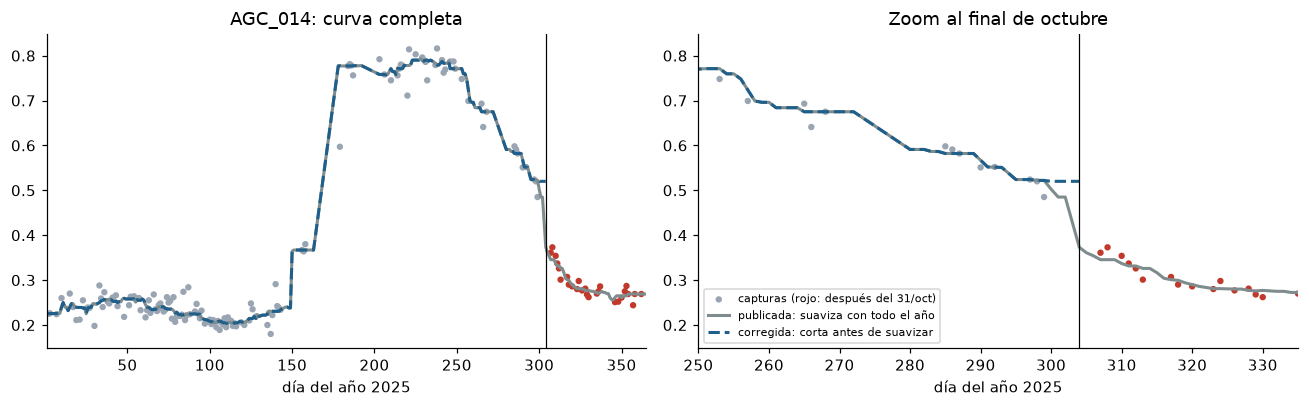

AGC_014: integral publicada 65.781, corregida 67.020, diferencia +1.239 NDVI·día


In [6]:
CORTE = 304

def curva(doy, valores, dias):
    s = pd.Series(np.asarray(valores, float)).groupby(np.asarray(doy, int)).median().reindex(np.asarray(dias, int))
    return s.rolling(15, center=True, min_periods=3).median().interpolate(limit_area="inside")

def integral(c, fin_max=CORTE):
    c = c.loc[:fin_max]; base = c.loc[91:150].median(); temporada = c.loc[150:min(330, fin_max)]
    if temporada.isna().all() or not np.isfinite(base):
        return np.nan
    pico, dia_pico = temporada.max(), temporada.idxmax(); umbral = base + 0.5 * (pico - base)
    subida = c.loc[150:dia_pico]; inicio = subida[subida >= umbral].index.min()
    bajada = c.loc[dia_pico:fin_max]; fin = bajada[bajada < umbral].index.min() if (bajada < umbral).any() else fin_max
    return float((c.loc[inicio:fin] - base).clip(lower=0).sum())

def integrales(cap, receta):
    c = cap.assign(doy=pd.to_datetime(cap.fecha).dt.dayofyear)
    if receta == "corregida":
        c = c[c.doy <= CORTE]; dias = np.arange(1, CORTE + 1)
    else:
        dias = np.arange(1, 366)
    return pd.Series({p: integral(curva(g.doy, g.ndvi_promedio, dias)) for p, g in c.groupby(ID)}, dtype=float)

I_pub, I_cor = integrales(capturas, "publicada"), integrales(capturas, "corregida")
ejemplo = (I_cor - I_pub).abs().idxmax()
g = capturas[capturas[ID].eq(ejemplo)].assign(doy=lambda d: pd.to_datetime(d.fecha).dt.dayofyear)
c_pub = curva(g.doy, g.ndvi_promedio, np.arange(1, 366)); c_cor = curva(g[g.doy <= CORTE].doy, g[g.doy <= CORTE].ndvi_promedio, np.arange(1, CORTE + 1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (x0, x1) in zip(ax, [(1, 365), (250, 335)]):
    a.scatter(g.doy, g.ndvi_promedio, s=10, c=np.where(g.doy > CORTE, "#c0392b", "#9aa5b3"), label="capturas (rojo: después del 31/oct)")
    a.plot(c_pub.index, c_pub, color="#7f8c8d", lw=2, label="publicada: suaviza con todo el año")
    a.plot(c_cor.index, c_cor, color="#1f5f8b", lw=2, ls="--", label="corregida: corta antes de suavizar")
    a.axvline(CORTE, color="k", lw=0.8); a.set_xlim(x0, x1); a.set_xlabel("día del año 2025")
ax[0].set_title(f"{ejemplo}: curva completa"); ax[1].set_title("Zoom al final de octubre"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"{ejemplo}: integral publicada {I_pub[ejemplo]:.3f}, corregida {I_cor[ejemplo]:.3f}, diferencia {I_cor[ejemplo]-I_pub[ejemplo]:+.3f} NDVI·día")

En los días previos al corte, la curva publicada usa la mediana de una ventana que llega
a noviembre. La corregida solo ve capturas hasta el 31 de octubre. La diferencia es
pequeña en la mayoría de parcelas, pero **no es cero**, y en principio podría cambiar
qué parcela queda por encima o por debajo de sus vecinas.

## 3. Las 197 parcelas: cuánto cambia, cobertura y vecinos

El contraste es la integral propia menos la mediana de las parcelas (de las 197) a menos
de 1 km, con ≥2 vecinas. La regla publicada cuenta vecinas *geométricas*, y su mediana
omite valores ausentes. Por eso podría basarse en una sola vecina válida. Se comprueba si
ocurre.

In [7]:
xy = meta[["x_m", "y_m"]].to_numpy(float); ids = meta[ID].to_numpy()
dist = np.linalg.norm(xy[:, None] - xy[None], axis=2)
VEC = {p: ids[(dist[i] < 1000) & (dist[i] > 0)] for i, p in enumerate(ids)}

def contraste(serie):
    out = {}
    for p, v in VEC.items():
        vals = serie.reindex(v).to_numpy(float)
        out[p] = serie[p] - np.nanmedian(vals) if len(v) >= 2 and np.isfinite(serie[p]) and np.isfinite(vals).any() else np.nan
    return pd.Series(out, dtype=float)

K_pub, K_cor = contraste(I_pub.reindex(ids)), contraste(I_cor.reindex(ids))
for nombre, x in [("integral_publicada", I_pub), ("integral_corregida", I_cor), ("K1_publicado", K_pub), ("K1_corregido", K_cor)]:
    np.testing.assert_allclose(x.reindex(variables_control.index), variables_control[nombre], atol=1e-12, rtol=0, equal_nan=True)
vecinas_finitas = pd.Series({p: int(np.isfinite(I_cor.reindex(v)).sum()) for p, v in VEC.items()})
geom = pd.Series({p: len(v) for p, v in VEC.items()})
oculta = meta.set_index(ID).CONJUNTO.eq("PREDICCION")
dI, dK = I_cor.reindex(ids) - I_pub.reindex(ids), K_cor - K_pub
resumen_cambio = pd.DataFrame([{"grupo": n, "parcelas": int(m.sum()), "integrales que cambian": int((dI[m].abs() > 1e-12).sum()),
                                "contrastes disponibles": int(K_cor[m].notna().sum()), "contrastes que cambian": int((dK[m].abs() > 1e-12).sum()),
                                "|Δ contraste| mediana": float(dK[m].abs().median()), "|Δ contraste| máx.": float(dK[m].abs().max())}
                               for n, m in [("etiquetadas", ~oculta), ("59 ocultas", oculta), ("todas", oculta | ~oculta)]]).set_index("grupo")
display(resumen_cambio.round(4))
print(f"Spearman contraste publicado–corregido: {K_pub.corr(K_cor, method='spearman'):.4f}")
print("Contrastes con ≥2 vecinas geométricas pero <2 vecinas finitas:", int(((geom >= 2) & (vecinas_finitas < 2)).sum()))
assert (dI.abs() > 1e-12).sum() == 130 and (dK.abs() > 1e-12).sum() == 131 and K_cor.notna().sum() == 158
assert ((geom >= 2) & (vecinas_finitas < 2)).sum() == 0

,parcelas,integrales que cambian,contrastes disponibles,contrastes que cambian,|Δ contraste| mediana,|Δ contraste| máx.
grupo,,,,,,
etiquetadas,138,92,108,90,0.0639,1.1275
59 ocultas,59,38,50,41,0.0568,0.9300
todas,197,130,158,131,0.0601,1.1275


Spearman contraste publicado–corregido: 0.9985
Contrastes con ≥2 vecinas geométricas pero <2 vecinas finitas: 0


**Resultado.** Cambian 130 de 197 integrales y 131 de 158 contrastes. La cobertura es la
misma: 108 etiquetadas y 50 ocultas tienen contraste. Los cambios son pequeños frente a
la escala de la variable, y el orden casi no cambia (Spearman ≈ 0.998). **Ningún
contraste se apoya en una sola vecina válida**, así que la regla de vecinos no necesitó
precisarse.

**Prueba de invariancia.** La receta corregida no debe depender de nada posterior al
corte. Cambiamos, borramos y añadimos capturas posteriores al 31/oct y recalculamos.

In [8]:
post = pd.to_datetime(capturas.fecha).dt.dayofyear > CORTE
rng = np.random.default_rng(20261008)
escenarios = {"cambiar_valores_posteriores": capturas.assign(ndvi_promedio=np.where(post, rng.uniform(-1, 1, len(capturas)), capturas.ndvi_promedio)),
              "borrar_posteriores": capturas[~post],
              "añadir_posteriores": pd.concat([capturas, pd.DataFrame({ID: capturas[ID].unique(), "fecha": "2025-11-02", "ndvi_promedio": 0.95, "porcentaje_nubosidad": 0.0})], ignore_index=True)}
inv = pd.DataFrame([{"escenario": n, "corregida: integrales que cambian": int((integrales(c, "corregida").reindex(I_cor.index) != I_cor).sum()),
                     "publicada: integrales que cambian": int((integrales(c, "publicada").reindex(I_pub.index) != I_pub).sum())} for n, c in escenarios.items()])
display(inv)
assert inv["corregida: integrales que cambian"].eq(0).all() and inv["publicada: integrales que cambian"].gt(0).all()

,escenario,corregida: integrales que cambian,publicada: integrales que cambian
0,cambiar_valores_posteriores,0,114
1,borrar_posteriores,0,130
2,añadir_posteriores,0,131


## 4. Comparación en dos juegos de particiones

| Procedimiento | Qué es |
| --- | --- |
| MUN / MIX | Referencias con receta fija (MIX = 0.5 media municipal + 0.5 IDW k=20) |
| K1_publicado | MIX + β·z con la variable de EXP_09: **control de reproducción** |
| K1_corregido | MIX + β·z con el corte bien hecho |

β = Σz̃e/(Σz̃² + 10). Los residuos e de MIX se obtienen dentro del entrenamiento con las
particiones internas, y z̃ se estandariza con mediana y desviación del entrenamiento.
Sin contraste, la parcela recibe MIX. Primero comprobamos que cada predicción guardada
cumple esa ecuación con los parámetros guardados. Eso es aritmética, no reentrenamiento.

In [9]:
oof = csv_insumo("oof"); par = csv_insumo("parametros"); varc = variables_control
PARTES = {"historicas": ("hist_externas", "hist_internas"), "nuevas": ("nuevas_externas", "nuevas_internas")}
for cj, (ke, ki) in PARTES.items():
    ext = csv_insumo(ke); o = oof[oof.conjunto.eq(cj)]
    assert len(o) == 4 * 1380 and set(o.modelo) == {"MUN", "MIX", "K1_publicado", "K1_corregido"}
    val = ext[ext.rol.eq("validacion")].set_index(["repeticion", "pliegue", ID]).index
    for m, q in o.groupby("modelo"):
        assert set(q.set_index(["repeticion", "pliegue", ID]).index) == set(val)
max_dif = 0.0
for (cj, r, f), q in oof.groupby(["conjunto", "repeticion", "pliegue"]):
    mixp = q[q.modelo.eq("MIX")].set_index(ID).predicho
    for k in ["K1_publicado", "K1_corregido"]:
        p = par[(par.conjunto == cj) & (par.repeticion == r) & (par.pliegue == f) & (par.modelo == k)].iloc[0]
        z = varc.loc[mixp.index, k].to_numpy(float)
        esperado = mixp.to_numpy() + np.where(np.isnan(z), 0.0, p.beta * (z - p.mediana) / p.escala)
        max_dif = max(max_dif, float(np.abs(q[q.modelo.eq(k)].set_index(ID).loc[mixp.index, "predicho"].to_numpy() - esperado).max()))
print(f"Ecuación MIX + β·z reproducida en 100 pliegues exteriores × 2 candidatos = 200 ecuaciones; diferencia máxima {max_dif:.1e}")
assert max_dif < 1e-12
oof = oof.merge(etiquetas.rename(columns={Y: "obs"}), on=ID, validate="many_to_one")
assert np.allclose(oof.obs, oof.observado)

def metr(g):
    e = g.predicho - g.obs; sst = ((g.obs - g.obs.mean()) ** 2).sum()
    return pd.Series({"n_oof": len(g), "RMSE": np.sqrt((e ** 2).mean()), "MAE": e.abs().mean(), "R2": 1 - (e ** 2).sum() / sst})

ESC = {(cj, "SEEN135"): oof[oof.conjunto.eq(cj) & oof.municipio_visto] for cj in PARTES} | {(cj, "FULL138"): oof[oof.conjunto.eq(cj)] for cj in PARTES}
met = pd.concat({k: v.groupby("modelo").apply(metr, include_groups=False) for k, v in ESC.items()}, names=["conjunto", "escenario", "modelo"])
ctrl = csv_insumo("metricas_control").set_index(["conjunto", "escenario", "modelo"])
np.testing.assert_allclose(met[["RMSE", "MAE", "R2"]].to_numpy(), ctrl.loc[met.index, ["RMSE", "MAE", "R2"]].to_numpy(), atol=1e-12, rtol=0)
tabla = met.xs("SEEN135", level="escenario")[["RMSE", "MAE", "R2"]].unstack("conjunto")
display(tabla.reindex(["MIX", "K1_publicado", "K1_corregido", "MUN"]).round(5))

Ecuación MIX + β·z reproducida en 100 pliegues exteriores × 2 candidatos = 200 ecuaciones; diferencia máxima 8.9e-16


RMSE                 MAE                  R2         
conjunto     historicas   nuevas historicas   nuevas historicas   nuevas
modelo                                                                  
MIX             0.48720  0.48567    0.33421  0.33571    0.66604  0.66813
K1_publicado    0.48159  0.48069    0.33300  0.33472    0.67368  0.67490
K1_corregido    0.48198  0.48096    0.33337  0.33488    0.67315  0.67453
MUN             0.49340  0.49222    0.32127  0.32133    0.65747  0.65912

K1c − MIX                          K1c − K1pub                    \
                mean      min      max reps<0        mean      min      max   
conjunto                                                                      
historicas  -0.00522 -0.00681 -0.00358     10     0.00039  0.00019  0.00073   
nuevas      -0.00473 -0.00747 -0.00035     10     0.00027  0.00010  0.00055   

                  K1pub − MIX                           
           reps<0        mean      min      max reps<0  
conjunto                                                
historicas      0     -0.0056 -0.00707 -0.00401     10  
nuevas          0     -0.0050 -0.00791 -0.00072     10

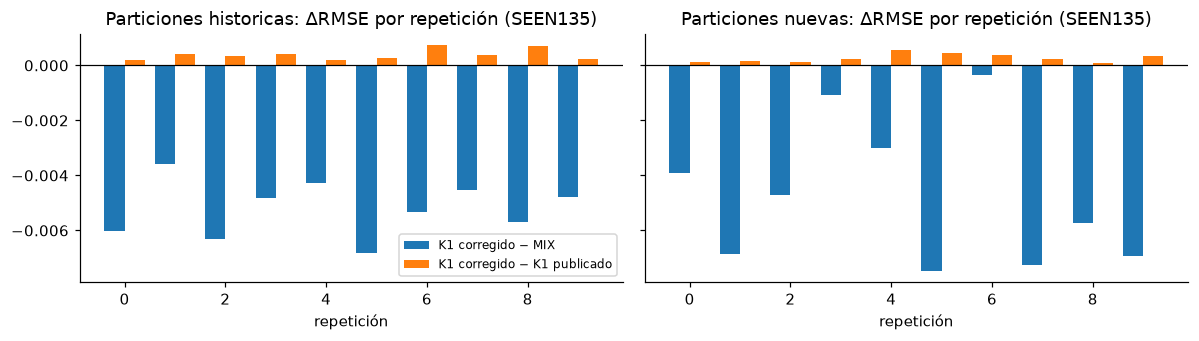

In [10]:
rep = pd.concat({cj: ESC[(cj, "SEEN135")].groupby(["modelo", "repeticion"]).apply(lambda g: np.sqrt(((g.predicho - g.obs) ** 2).mean()), include_groups=False).unstack("modelo")
                 for cj in PARTES}, names=["conjunto"])
dif = pd.DataFrame({"K1c − MIX": rep.K1_corregido - rep.MIX, "K1c − K1pub": rep.K1_corregido - rep.K1_publicado, "K1pub − MIX": rep.K1_publicado - rep.MIX})
resumen_pareado = dif.groupby("conjunto").agg(["mean", "min", "max", lambda s: int((s < 0).sum())]).rename(columns={"<lambda_0>": "reps<0"}, level=1)
display(resumen_pareado.round(5))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for a, cj in zip(ax, PARTES):
    d = dif.loc[cj]; a.bar(d.index - 0.2, d["K1c − MIX"], 0.4, label="K1 corregido − MIX"); a.bar(d.index + 0.2, d["K1c − K1pub"], 0.4, label="K1 corregido − K1 publicado")
    a.axhline(0, color="k", lw=0.8); a.set_title(f"Particiones {cj}: ΔRMSE por repetición (SEEN135)"); a.set_xlabel("repetición")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
assert (dif["K1c − MIX"] < 0).all() and (dif["K1c − K1pub"] > 0).all()

**Lectura.**

* **K1 publicado reproduce EXP_09:** 0.4816 en particiones históricas y 0.4807 en nuevas.
* **K1 corregido** baja el RMSE de MIX de 0.48720 a **0.48198** (históricas) y de 0.48567
  a **0.48096** (nuevas). Mejora a MIX en las 10 repeticiones de cada juego, y su MAE
  también queda por debajo del de MIX.
* **Frente a K1 publicado, el corregido es algo peor en las 20 repeticiones.** La
  discrepancia temporal **inflaba** la ganancia, pero solo en ~0.0003–0.0004 t/ha, cerca
  de un 7 %. La mejora no dependía de ella.
* En las particiones nuevas, la repetición menos favorable queda casi empatada con MIX
  (−0.0004). Las 10 repeticiones reutilizan las mismas 138 parcelas: **no son diez pruebas
  independientes.**

## 5. Dónde está la mejora: territorio y concentración

Retirar parcelas se hace **solo al evaluar** (las mismas OOF), como sensibilidad. Nunca
se reentrena sin ellas.

In [11]:
zonas = pd.concat({cj: ESC[(cj, "SEEN135")].assign(zona=lambda d: np.where(d.Municipio.eq("Chignahuapan"), "Chignahuapan", "resto"))
                  .groupby(["zona", "modelo"]).apply(lambda g: np.sqrt(((g.predicho - g.obs) ** 2).mean()), include_groups=False).unstack("modelo") for cj in PARTES}, names=["conjunto"])
display(zonas[["MUN", "MIX", "K1_publicado", "K1_corregido"]].round(4))
munis = csv_insumo("municipios_control").pivot_table(index=["conjunto", "Municipio"], columns="modelo", values="RMSE")
display(munis[["MUN", "MIX", "K1_corregido"]].round(4))

def sensibilidad(o, cand):
    w = o.pivot_table(index=[ID, "repeticion"], columns="modelo", values="predicho").join(o.groupby([ID, "repeticion"]).obs.first())
    dse = ((w[cand] - w.obs) ** 2 - (w.MIX - w.obs) ** 2).groupby(ID).sum().sort_values()
    filas = []
    for k in (0, 2, 5):
        ww = w[~w.index.get_level_values(ID).isin(dse.index[:k])]
        filas.append({"retiradas": k, "parcelas": ", ".join(dse.index[:k]), "ΔRMSE vs MIX": np.sqrt(((ww[cand] - ww.obs) ** 2).mean()) - np.sqrt(((ww.MIX - ww.obs) ** 2).mean())})
    return dse, pd.DataFrame(filas)

sens = {}
for cj in PARTES:
    dse, s = sensibilidad(ESC[(cj, "SEEN135")], "K1_corregido"); sens[cj] = s
    print(f"{cj}: cambio neto de SSE {dse.sum():+.3f}; mejoran {(dse < 0).sum()} parcelas, empeoran {(dse > 0).sum()}")
    display(s.round(5))
ctrl = csv_insumo("sensibilidades_control")
for cj, s in sens.items():
    c = ctrl[(ctrl.conjunto == cj) & (ctrl.candidato == "K1_corregido")].sort_values("retiradas_de_evaluacion")
    np.testing.assert_allclose(s["ΔRMSE vs MIX"], c.delta_RMSE, atol=1e-12, rtol=0)

modelo                      MUN     MIX  K1_publicado  K1_corregido
conjunto   zona                                                    
historicas Chignahuapan  0.5902  0.5736        0.5681        0.5687
           resto         0.3565  0.3683        0.3623        0.3623
nuevas     Chignahuapan  0.5883  0.5692        0.5644        0.5648
           resto         0.3564  0.3716        0.3661        0.3661

modelo                               MUN     MIX  K1_corregido
conjunto   Municipio                                          
historicas Almoloya               0.2007  0.1794        0.1719
           Calpulalpan            0.3790  0.4013        0.4023
           Chignahuapan           0.5902  0.5736        0.5687
           Cuautepec de Hinojosa  0.1655  0.2604        0.2394
           Emiliano Zapata        0.0000  0.1382        0.1382
           Singuilucan            0.4531  0.4424        0.4264
nuevas     Almoloya               0.1991  0.1831        0.1727
           Calpulalpan            0.3812  0.4085        0.4108
           Chignahuapan           0.5883  0.5692        0.5648
           Cuautepec de Hinojosa  0.1655  0.2601        0.2419
           Emiliano Zapata        0.0000  0.1125        0.1125
           Singuilucan            0.4500  0.4417        0.4246

historicas: cambio neto de SSE -6.824; mejoran 58 parcelas, empeoran 49


,retiradas,parcelas,ΔRMSE vs MIX
0,0,,-0.00522
1,2,"AGC_162, AGC_172",-0.00104
2,5,"AGC_162, AGC_172, AGC_049, AGC_133, AGC_024",0.00334


nuevas: cambio neto de SSE -6.146; mejoran 60 parcelas, empeoran 47


,retiradas,parcelas,ΔRMSE vs MIX
0,0,,-0.00471
1,2,"AGC_162, AGC_172",-0.00061
2,5,"AGC_162, AGC_172, AGC_049, AGC_133, AGC_024",0.00348


**Resultado.**

* La mejora aparece sobre todo en **Chignahuapan** (0.5736 → 0.5687 en particiones
  históricas), donde estaba la mayor parte del error, y también en Singuilucan y Almoloya.
* En **Calpulalpan**, K1 corregido queda ligeramente peor que MIX. Fuera de
  Chignahuapan, MUN sigue siendo mejor que ambos.
* **La ganancia está concentrada.** Sin las 2 parcelas más favorecidas (AGC_162 y
  AGC_172), sigue habiendo mejora, pero de solo ~0.001 t/ha. Sin las 5, se invierte en
  ambos juegos.

## 6. ¿Podría ser azar? Revisión del nulo de EXP_09 y un nulo espacial

El estadístico es el mismo de EXP_09: **el menor RMSE SEEN entre seis candidatos** (K1,
borde rojo, radar, AlphaEarth, historia y combinado). No se reduce la familia a un solo
candidato. Cada nulo se ejecutó **una vez**, con semilla y tamaño fijados en el registro
previo.

| Nulo | Cómo genera variables sin relación con el rendimiento | Qué conserva | Qué no conserva |
| --- | --- | --- | --- |
| N0 | Permutación de filas dentro de municipio (EXP_09), con K1 publicado | Distribución y correlación entre columnas | Dependencia espacial fina; ubicación de los faltantes |
| N1 | Igual que N0, con K1 corregido | Igual | Igual |
| N2 | Aleatorización espectral de Moran: cambia los signos de los coeficientes en vectores propios de la vecindad de 1 km (Wagner y Dray, 2015) | Varianza, I de Moran, espectro espacial, correlaciones entre columnas y ubicación de faltantes | La forma exacta de la distribución marginal |

**Por qué hace falta N2.** Los contrastes y los residuos de rendimiento tienen dependencia
espacial a menos de 1 km (EXP_08). Suponer que cualquier asignación dentro del municipio
es igual de probable **no está justificado**: destruye esa estructura y mueve los
faltantes. N2 supone en cambio que, sin relación con el rendimiento, el campo es
invariante a esos cambios de signo, lo que es razonable para un proceso espacial
estacionario. **Tampoco es una prueba exacta.**

,candidato,RMSE observado,media del mínimo nulo,percentil 5 nulo,k/N,(k+1)/(N+1),válido
nulo,,,,,,,
N0,K1_publicado,0.4816,0.4858,0.4786,0.130,0.1343,True
N1,K1_corregido,0.4820,0.4853,0.4792,0.180,0.1841,True
N2,K1_corregido,0.4820,0.4859,0.4786,0.125,0.1294,True


Conservación MSR verificada en 20 sorteos: {'max_dif_moran': 6.38378239159465e-16, 'max_dif_covarianza': 7.105427357601002e-14, 'faltantes_iguales': True}


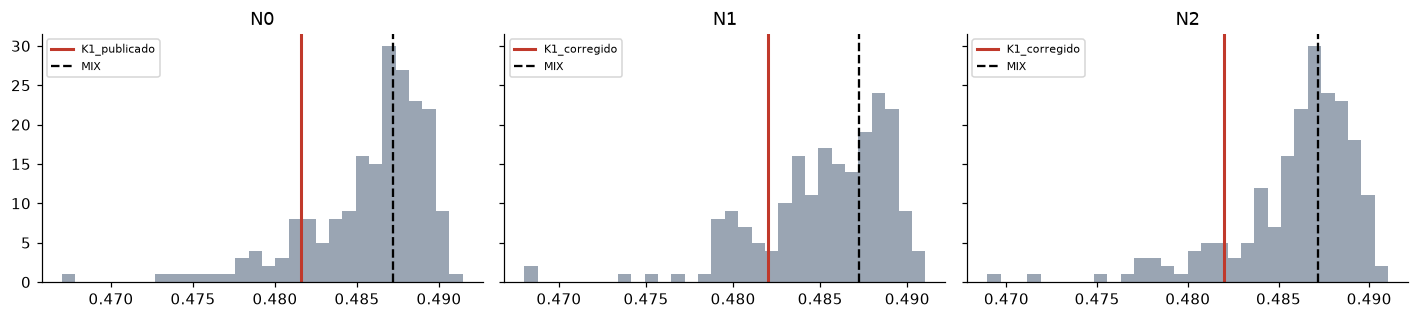

In [12]:
NUL = json_insumo("nulos_resumen"); sorteos = csv_insumo("nulos_sorteos")
filas = []
for n in ["N0", "N1", "N2"]:
    d = sorteos[sorteos.nulo.eq(n)]; r = NUL[n]; k = int((d.minimo_familia <= r["rmse_observado"]).sum())
    assert k == r["k"] and len(d) == 200
    filas.append({"nulo": n, "candidato": r["candidato"], "RMSE observado": r["rmse_observado"], "media del mínimo nulo": d.minimo_familia.mean(),
                  "percentil 5 nulo": d.minimo_familia.quantile(0.05), "k/N": k / 200, "(k+1)/(N+1)": (k + 1) / 201, "válido": r["valido"]})
display(pd.DataFrame(filas).set_index("nulo").round(4))
print("Conservación MSR verificada en 20 sorteos:", NUL["N2"]["conservacion_msr"])
fig, ax = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for a, n in zip(ax, ["N0", "N1", "N2"]):
    d = sorteos[sorteos.nulo.eq(n)]; a.hist(d.minimo_familia, bins=30, color="#9aa5b3")
    a.axvline(NUL[n]["rmse_observado"], color="#c0392b", lw=2, label=NUL[n]["candidato"]); a.axvline(0.48720, color="k", ls="--", label="MIX")
    a.set_title(n); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
assert NUL["N0"]["p_k_sobre_N"] == 0.13

**Resultado.**

* **N0 reproduce exactamente el p = 0.13 de EXP_09.**
* Con el corte corregido, el p de familia es **≈0.18 con la permutación municipal (N1)**
  y **≈0.13 con el nulo espacial (N2)**. Ambos quedan por encima del umbral registrado
  de 0.10.
* N2 resultó *menos* exigente que N1 en estos datos. No asumimos que un nulo sea siempre
  más conservador que el otro: se reportan ambos y la regla exige los dos.
* Ningún p-valor depende de repetir permutaciones: cada nulo se ejecutó una vez, con el
  tamaño fijado.

## 7. Regla de desarrollo de EXP_10 y decisión

Fijada en el protocolo antes de los scores, en SEEN135 y en **ambos** juegos:
**R1** RMSE < MIX; **R2** ≥8/10 repeticiones; **R3** MAE ≤ MIX; **R4** sin invertirse al
retirar de la evaluación las 2 parcelas más favorecidas. **S**: p de familia ≤ 0.10 en N1
y en N2. Cumplir R1–R4 significa "cumple los requisitos predictivos". Solo S
hablaría de "evidencia estadística suficiente para adoptar".

In [13]:
reglas = csv_insumo("reglas_control").set_index("candidato")
k = reglas.loc["K1_corregido"]
tabla_reglas = pd.DataFrame({
    "históricas": [bool(tabla.loc["K1_corregido", ("RMSE", "historicas")] < tabla.loc["MIX", ("RMSE", "historicas")]),
                   int((dif.loc["historicas", "K1c − MIX"] < 0).sum()),
                   bool(tabla.loc["K1_corregido", ("MAE", "historicas")] <= tabla.loc["MIX", ("MAE", "historicas")]),
                   bool(sens["historicas"].iloc[1]["ΔRMSE vs MIX"] < 0)],
    "nuevas": [bool(tabla.loc["K1_corregido", ("RMSE", "nuevas")] < tabla.loc["MIX", ("RMSE", "nuevas")]),
               int((dif.loc["nuevas", "K1c − MIX"] < 0).sum()),
               bool(tabla.loc["K1_corregido", ("MAE", "nuevas")] <= tabla.loc["MIX", ("MAE", "nuevas")]),
               bool(sens["nuevas"].iloc[1]["ΔRMSE vs MIX"] < 0)]},
    index=["R1 RMSE < MIX", "R2 repeticiones < MIX", "R3 MAE ≤ MIX", "R4 sin invertirse quitando 2"])
display(tabla_reglas)
REQ = bool(k.requisitos_predictivos); S = bool(k.S)
assert REQ == bool(tabla_reglas.loc[["R1 RMSE < MIX", "R3 MAE ≤ MIX", "R4 sin invertirse quitando 2"]].all().all() and (tabla_reglas.loc["R2 repeticiones < MIX"] >= 8).all())
print(f"Requisitos predictivos R1–R4: {REQ} | Evidencia estadística S (p_N1={k.p_N1:.3f}, p_N2={k.p_N2:.3f} ≤ 0.10): {S}")
DECISION = REG["decision_regla"]; print("Decisión por la regla registrada:", DECISION)
assert REQ and not S and DECISION.startswith("conservar_MIX")

,históricas,nuevas
R1 RMSE < MIX,True,True
R2 repeticiones < MIX,10,10
R3 MAE ≤ MIX,True,True
R4 sin invertirse quitando 2,True,True


Requisitos predictivos R1–R4: True | Evidencia estadística S (p_N1=0.184, p_N2=0.129 ≤ 0.10): False
Decisión por la regla registrada: conservar_MIX_K1_corregido_alternativa_documentada_sin_evidencia_estadistica_suficiente


### Conclusión

**a) Discrepancia técnica corregida.** Confirmada: la receta publicada usaba capturas de
noviembre para valores de octubre. Afectaba 130/197 integrales y 131/158 contrastes. La
receta corregida es invariante a todo lo posterior al 31/oct, y su cobertura es la misma.

**b) Mejora predictiva observada.** Con el corte correcto, K1 sigue mejorando a MIX:
≈0.0052 t/ha de RMSE en particiones históricas y ≈0.0047 en nuevas (~1 %), con MAE no
peor. La discrepancia inflaba la ganancia en ~7 %, pero no la explicaba.

**c) Estabilidad y concentración.** La mejora es estable en dirección (20/20
repeticiones), pero está concentrada. Depende sobre todo de pocas parcelas de
Chignahuapan y se invierte al quitar las 5 más favorecidas. No hay evidencia estadística
suficiente: el p de familia es 0.18 (N1) y 0.13 (N2).

**d) Recomendación provisional.** Según la regla registrada, **conservar MIX como
referencia oficial**. K1 corregido queda como **alternativa documentada que cumple los
requisitos predictivos de desarrollo sin evidencia estadística suficiente**. Elegirlo es
una decisión explícita del equipo, no un resultado de este experimento.

## 8. Las 59 ocultas: soporte, sin predecirlas

In [14]:
sop = csv_insumo("soporte_control")
display(sop.groupby("Municipio").agg(ocultas=(ID, "size"), con_contraste=("K1_corregido", lambda s: int(s.notna().sum())),
                                     respaldo_MIX=("respaldo_MIX", "sum"), dentro_del_rango=("dentro_rango_etiquetadas", "sum")))
nana = sop[sop.Municipio.str.startswith("Nanacamilpa")]
display(nana)
assert int(sop.K1_corregido.notna().sum()) == 50 and len(sop) == 59

,ocultas,con_contraste,respaldo_MIX,dentro_del_rango
Municipio,,,,
Almoloya,4,3,1,3
Calpulalpan,14,9,5,9
Chignahuapan,29,29,0,29
Cuautepec de Hinojosa,4,3,1,3
Nanacamilpa de Mariano Arista,1,0,1,0
Singuilucan,7,6,1,6


,ID_POLIGONO,Municipio,K1_corregido,K1_publicado,vecinos_geometricos,respaldo_MIX,dentro_rango_etiquetadas
34,AGC_120,Nanacamilpa de Mariano Arista,NaN,NaN,0,True,False


50 de 59 ocultas tienen contraste, todas dentro del rango observado en las etiquetadas.
Las 9 restantes recibirían MIX sin corrección. Un rango univariado no garantiza soporte.

**Nanacamilpa (AGC_120):** su municipio tiene una sola etiqueta, la parcela no tiene
vecinas a <1 km y recibiría MIX sin corrección. SEEN135 no puntúa ningún caso
equivalente, así que su error esperado no está medido por este experimento.

## 9. Cómo reproducir el entrenamiento

Este cuaderno **no entrena**. Para reproducir la corrida desde la carpeta del proyecto:

```bash
uv run --locked --all-groups python scripts/factibilidad_10.py           # solo X: variables, vecinos, invariancia
uv run --locked --all-groups python scripts/experimento_10.py --salida resultados/exp_10_verificacion_contraste_vecinal/<nueva>
uv run --locked --all-groups python scripts/verificar_exp_10_resultados.py
uv run --locked --all-groups pytest -q tests/test_modelo_10.py
```

`factibilidad_10.py` reescribe las salidas de factibilidad, que deben coincidir con los
hashes de `registro_previo.json`. `experimento_10.py` no sobrescribe una carpeta
existente. Presupuesto de una corrida:

* 100 evaluaciones de referencias exteriores y 400 de MIX interno;
* 200 ajustes de corrección;
* el mismo número otra vez como control de fuga;
* 180,900 ajustes de corrección en los nulos (3 × 201 × 300).

La réplica de determinismo repitió todo y produjo 13 archivos idénticos.

## 10. Relación con EXP_08 y EXP_09

* Los cuadernos y cierres de EXP_08/09 se conservan sin cambios. Sus cifras "hasta 31 oct"
  corresponden a la receta publicada, con la discrepancia.
* **EXP_09 K2 (borde rojo) y K3 (radar)** usaban la misma construcción y comparten la
  discrepancia. Aquí solo se usan como miembros del nulo de familia; no se corrigieron
  ni se reevaluaron como candidatos.
* El cierre de EXP_09 (recomendar MIX) se mantiene, y EXP_10 llega a la misma
  recomendación con la variable corregida.

## Referencias

Wagner, H. H., & Dray, S. (2015). Generating spatially constrained null models for
irregularly spaced data using Moran spectral randomization methods. *Methods in Ecology
and Evolution, 6*(10), 1169–1178. https://doi.org/10.1111/2041-210X.12407

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent
selection bias in performance evaluation. *Journal of Machine Learning Research, 11*,
2079–2107. https://jmlr.org/papers/v11/cawley10a.html

Jönsson, P., & Eklundh, L. (2004). TIMESAT—a program for analyzing time-series of satellite
sensor data. *Computers & Geosciences, 30*(8), 833–845. https://doi.org/10.1016/j.cageo.2004.05.006

In [15]:
resumen = {"id": "EXP_10", "modo": "lector_resultados_experimento_registrado_sin_ajustes", "parcelas": 197, "etiquetas": 138,
           "capturas_incorporadas": int(len(capturas)), "integrales_cambian": int((dI.abs() > 1e-12).sum()),
           "contrastes_cambian": int((dK.abs() > 1e-12).sum()), "contrastes_disponibles": int(K_cor.notna().sum()),
           "invariancia_corregida": True, "ecuaciones_oof_reproducidas": 200, "juegos_particiones": 2,
           "oof_total": int(len(oof)), "metricas_recalculadas": True, "ajustes_actuales": 0, "predicciones_finales_generadas": 0,
           "requisitos_predictivos_K1_corregido": REQ, "evidencia_estadistica_K1_corregido": S, "decision_regla": DECISION,
           "rmse_seen": {f"{m}|{cj}": float(tabla.loc[m, ("RMSE", cj)]) for m in tabla.index for cj in PARTES},
           "colab_real_probado": False}
print("RESUMEN_EXP_10_JSON=" + json.dumps(resumen, ensure_ascii=False, sort_keys=True))

RESUMEN_EXP_10_JSON={"ajustes_actuales": 0, "capturas_incorporadas": 32257, "colab_real_probado": false, "contrastes_cambian": 131, "contrastes_disponibles": 158, "decision_regla": "conservar_MIX_K1_corregido_alternativa_documentada_sin_evidencia_estadistica_suficiente", "ecuaciones_oof_reproducidas": 200, "etiquetas": 138, "evidencia_estadistica_K1_corregido": false, "id": "EXP_10", "integrales_cambian": 130, "invariancia_corregida": true, "juegos_particiones": 2, "metricas_recalculadas": true, "modo": "lector_resultados_experimento_registrado_sin_ajustes", "oof_total": 11040, "parcelas": 197, "predicciones_finales_generadas": 0, "requisitos_predictivos_K1_corregido": true, "rmse_seen": {"K1_corregido|historicas": 0.48198075658497197, "K1_corregido|nuevas": 0.4809604605838424, "K1_publicado|historicas": 0.48159117705430465, "K1_publicado|nuevas": 0.48068979028702147, "MIX|historicas": 0.4871965149200082, "MIX|nuevas": 0.48567008670434514, "MUN|historicas": 0.49340403132471566, "MUN|nu